# Evaluation results and discussion: 24 agentic-workflow variants

This is the single notebook for the evaluation. It reads the executed run (312 runs = 24 variants × 13 scenarios), plus two complete re-runs of the same 312 runs for metric 7 (consistency), and has three parts:

| Part | Contents | Role |
|---|---|---|
| **§0 Data preparation** | Load the scored runs, join latency and tokens from the raw logs, derive pass/fail labels | Set-up (collapse) |
| **Part A · Results and discussion** | Seven metrics → main analysis → H1–H4 (scorecard, significance test, evidence, verdict) → additional findings → qualitative analysis → robustness → consistency → conclusion | **Presentation** |
| **Part B · Supporting analysis** | The full evidence: every metric per variant, paired significance tests (H1–H4), task categories, failures, the final result tables (by variant, by category) | Questions and appendices |

## Presentation guide

**Set-up (5 minutes before)**
1. Open this notebook in VS Code and click **Run All** at the top. It takes about a minute.
2. Hide the code: `Ctrl+Shift+P` → type **Collapse All Code** → Enter. Only headings, charts and talking points stay visible.
3. Zoom in so the back row can read it: `Ctrl` + `=` two or three times.
4. Scroll to **Part A** and close every other window.

**3-minute run of show**

| Time | Section | Content |
|---|---|---|
| 0:00 | A1 Study and hypotheses | Hypothesis table |
| 0:10 | **A2 Evaluation metrics** | Metric table (computed), then the chart |
| 0:40 | A3 Main analysis | Task success by design choice vs by task type |
| 0:55 | **A4 H1** | Scorecard → significance table → refusal evidence → verdict |
| 1:20 | **A5 H2** | Scorecard → significance table → escalation evidence → verdict |
| 1:45 | **A6 H3** | Scorecard → significance table → team failures → verdict |
| 2:10 | **A7 H4** | Scorecard → significance table → tool counts → verdict |
| 2:35 | **A8 Additional findings** | RAG vs skills; team roles; wording-only failures |
| 2:50 | A11 Conclusion | Verdict table; A9–A10b only on request |

**Tips**
- Read the **🎤 Say** box under each heading. It is written as speech, so you can say it almost word for word, and you never need to explain the code.
- Scroll so the heading sits at the top of the screen, then talk while the chart is visible.
- **Questions:** the answer is usually in **Part B**, e.g. "Is that difference significant?" → §5–§7 and the verdict table in §11. Or show any real run with `show_case("EVAL-13", "s8-a")` (type it into a new cell and press `Shift+Enter`).
- **If something breaks live:** every Part B chart is also saved in `results/deepeval/output/figures/` and can be opened as an image.
- **Code reference:** each cell starts with a "PURPOSE" comment.

## §0 Data preparation

Loads and labels the runs. Run these cells, then collapse them; nothing here needs presenting.

In [1]:
# ──────────────────────────────────────────────────────────────────────────────
# PURPOSE: setup only.
# - Imports the libraries: pandas for tables, matplotlib and seaborn for charts, scipy for statistical tests.
# - Finds the project folder and the file paths the notebook reads from.
# - Sets the chart colours and style used throughout the notebook.
# Nothing to present here.
# ──────────────────────────────────────────────────────────────────────────────
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
pd.set_option("display.precision", 3)

# Repo root, found whether the notebook runs from results/deepeval or the root
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "EXPERIMENT.md").exists())
CSV = ROOT / "results/deepeval/data/raw/baseline/run1/scored_dedup.csv"
RAW_DIR = ROOT / "deepeval"
FIG_DIR = ROOT / "results/deepeval/output/figures"
FIG_DIR.mkdir(exist_ok=True)

# Colours: categorical slot 1 (blue) = agentic, slot 2 (orange) = graph; one-hue ramp for heatmaps
C_AGENTIC, C_GRAPH = "#2a78d6", "#eb6834"
CONTROL_PAL = {"agentic": C_AGENTIC, "graph": C_GRAPH}
SEQ = sns.light_palette("#2a78d6", as_cmap=True)
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.titleweight": "bold", "axes.titlesize": 11, "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": INK2, "ytick.color": INK2, "font.size": 9, "legend.frameon": False,
    "lines.linewidth": 2,
})

## 1. Load and label the data

In [2]:
# ──────────────────────────────────────────────────────────────────────────────
# PURPOSE: loads the scored results. Each row is one run (one variant answering one scenario), 312 rows in total.
# It then derives labels from the setup ID (e.g. "s3-c"):
# - family = S1..S8
# - variant = a..d
# - control = agentic or graph
# - agents = single or multi
# - policy = RAG or SKILL
# - strategy = ReAct or plan-and-execute
# pair_id links each agentic variant to its graph twin (S1-a <-> S5-a), which the paired statistical tests need later.
# ──────────────────────────────────────────────────────────────────────────────
df = pd.read_csv(CSV)

df["family"] = df["setup"].str[:2].str.upper()           # S1..S8
df["variant"] = df["setup"].str[-1]                      # a..d
fam_num = df["family"].str[1].astype(int)
df["control"] = np.where(fam_num <= 4, "agentic", "graph")
df["agents"] = np.where(fam_num.isin([1, 2, 5, 6]), "single", "multi")
df["policy"] = np.where(fam_num % 2 == 1, "RAG", "SKILL")

SINGLE_STRAT = {"a": "react", "b": "plan_execute"}
MULTI_STRAT = {"a": "react / react", "b": "plan / plan", "c": "react / plan", "d": "plan / react"}
df["strategy"] = np.where(df["agents"] == "single", df["variant"].map(SINGLE_STRAT), df["variant"].map(MULTI_STRAT))
# The "thinking mode" of whoever makes the tool calls (the agent, or the specialists in multi-agent setups)
df["worker_strategy"] = df["variant"].map({"a": "react", "b": "plan_execute", "c": "plan_execute", "d": "react"})
# The supervisor's thinking mode in multi-agent setups ("none" for single agents, which have no supervisor)
df["supervisor"] = np.where(df["agents"] == "single", "none",
                            df["variant"].map({"a": "react", "b": "plan_execute", "c": "react", "d": "plan_execute"}))

# Matched pair across control style: same agent count, policy and variant (S1-a <-> S5-a, ...)
df["pair_id"] = df["agents"] + "-" + df["policy"] + "-" + df["variant"]
df["arch"] = df["agents"] + " · " + df["control"]

df[["setup", "family", "variant", "control", "agents", "policy", "strategy", "pair_id"]].drop_duplicates().reset_index(drop=True)

,setup,family,variant,control,agents,policy,strategy,pair_id
0,s1-a,S1,a,agentic,single,RAG,react,single-RAG-a
1,s1-b,S1,b,agentic,single,RAG,plan_execute,single-RAG-b
2,s2-a,S2,a,agentic,single,SKILL,react,single-SKILL-a
3,s2-b,S2,b,agentic,single,SKILL,plan_execute,single-SKILL-b
4,s3-a,S3,a,agentic,multi,RAG,react / react,multi-RAG-a
5,s3-b,S3,b,agentic,multi,RAG,plan / plan,multi-RAG-b
6,s3-c,S3,c,agentic,multi,RAG,react / plan,multi-RAG-c
7,s3-d,S3,d,agentic,multi,RAG,plan / react,multi-RAG-d
8,s4-a,S4,a,agentic,multi,SKILL,react / react,multi-SKILL-a
9,s4-b,S4,b,agentic,multi,SKILL,plan / plan,multi-SKILL-b


### 1a. Join latency and cost from the raw run logs

The scored CSV has no timing, so latency, LLM calls, tokens and tool calls come from the raw run JSONL files in
`results/deepeval/data/raw/baseline/run1/results.jsonl`. A multi-turn case (EVAL-12, EVAL-13) has one `workflow_end` event per turn; those are summed.

EVAL-01 was run twice for every setup in `data/raw/baseline/run1/results.jsonl`, and the deduped CSV kept the **later** run, so we keep the last
raw row per (case, setup). The assert checks that every scored row found its run and that ticket statuses agree.

In [3]:
# ──────────────────────────────────────────────────────────────────────────────
# PURPOSE: adds the cost and speed data, which are not in the scored file.
# - Reads the raw run logs (.jsonl). For each run it adds up the wall-clock time, the number of LLM calls,
#   the input/output tokens and the tools called.
# - Joins these onto the scored rows.
# - The two asserts check that every scored row found its raw run and that the ticket statuses agree.
# ──────────────────────────────────────────────────────────────────────────────
# Run 1's raw log. It holds all 312 scored runs plus an earlier EVAL-01 pass for every setup; that earlier pass comes
# first in the file, so keeping the last row per (case, setup) selects the scored run.
RUN1_LOG = ROOT / "results/deepeval/data/raw/baseline/run1/results.jsonl"

def summarise_run(row):
    events = row["trace"].get("events", [])
    ends = [e for e in events if e["kind"] == "workflow_end"]
    calls = [e for e in events if e["kind"] == "llm_call"]
    return {
        "case_id": row["case_id"], "setup": row["setup"],
        "raw_status": row["ticket_status"],
        "elapsed_s": sum(e.get("elapsed_s", 0) for e in ends),
        "llm_calls": sum(e.get("llm_calls", 0) for e in ends),
        "input_tokens": sum(e.get("input_tokens", 0) for e in calls),
        "output_tokens": sum(e.get("output_tokens", 0) for e in calls),
        "tool_calls": len(row["tools_called"]),
        "tool_path": " > ".join(t["name"] for t in row["tools_called"]),
        "write_count": len(row.get("writes") or []),
        "models": ",".join(sorted({e.get("model", "?") for e in calls})),
        "turns": len(ends),
    }

raw = pd.DataFrame([summarise_run(json.loads(line)) | {"run_idx": i}
                    for i, line in enumerate(RUN1_LOG.open(encoding="utf-8"))])

key = ["case_id", "setup"]
raw = raw.sort_values("run_idx")
raw_kept = raw.drop_duplicates(key, keep="last")

df = df.merge(raw_kept.drop(columns="run_idx"), on=key, how="left", validate="one_to_one")
assert df["elapsed_s"].notna().all(), "a scored row has no raw run"
assert (df["raw_status"] == df["ticket_status"]).all(), "raw and scored ticket statuses disagree"
df["total_tokens"] = df["input_tokens"] + df["output_tokens"]

print(f"{len(df)} scored rows = {df.setup.nunique()} setups × {df.case_id.nunique()} cases")
print("Agent LLM(s) used:", df["models"].value_counts().to_dict())

312 scored rows = 24 setups × 13 cases
Agent LLM(s) used: {'openai/gpt-oss-120b': 312}


### 1b. Case catalogue

In [4]:
# ──────────────────────────────────────────────────────────────────────────────
# PURPOSE: attaches a description and tags to each of the 13 scenarios.
# - kind = routine lookup (EVAL-01 to 08) or non-routine.
# - The tags in deepeval/cases/categories.csv add category (simple lookup / multi-step / safety), complexity, turns, etc.
# These tags let us break results down by task type later on.
# ──────────────────────────────────────────────────────────────────────────────
cases = pd.read_csv(RAW_DIR / "cases" / "baseline.csv").set_index("case_id")[["focus", "expected_ticket_status"]].sort_index()

# Routine single-lookup cases vs the cases that need the agent to adapt (writes, safety, injection, clarification, replay)
ROUTINE = [f"EVAL-0{i}" for i in range(1, 9)]
cases["kind"] = np.where(cases.index.isin(ROUTINE), "routine lookup", "non-routine")
df = df.merge(cases[["focus", "kind"]], left_on="case_id", right_index=True)

# Task tags (§9 explains them). They live in deepeval/cases/categories.csv: edit that file to re-tag a case, then rerun
TAXONOMY = (pd.read_csv(ROOT / "deepeval/cases/categories.csv", index_col="case_id")
              .drop(columns=["focus", "query"])
              .rename(columns=lambda c: c.replace("_", " ")))
DIMS = list(TAXONOMY.columns)
CAT_ORDER = list(dict.fromkeys(TAXONOMY["category"]))          # categories in the order they first appear in the CSV
assert set(TAXONOMY.index) == set(df.case_id), "every case needs a tag"
df = df.drop(columns=[c for c in DIMS if c in df.columns]).join(TAXONOMY, on="case_id")   # replaces the raw turn count
cases

,focus,expected_ticket_status,kind
case_id,,,
EVAL-01,Order contents lookup: items in the power-bank...,resolved,routine lookup
EVAL-02,Order status lookup: processing order,resolved,routine lookup
EVAL-03,Payment lookup: captured payment status,resolved,routine lookup
EVAL-04,Return lookup: pending fault claim status,resolved,routine lookup
EVAL-05,Tracking lookup: delivered shipment status,resolved,routine lookup
EVAL-06,Policy lookup: ordinary return request window,resolved,routine lookup
EVAL-07,Customer order lookup: identify processing order,resolved,routine lookup
EVAL-08,Shipment lookup: carrier and tracking number,resolved,routine lookup
EVAL-09,"Refund processing: approved bottle return, SGD 20",resolved,non-routine


## 2. The metrics

Every comparison below uses the eight DeepEval metrics in the CSV, each reported two ways:

- **Pass rate:** the share of runs that pass, from the `<metric>_success_manual` columns (score ≥ 0.5, plus two
  hand corrections; see below).
- **Mean score:** the judge's raw 0–1 score (`<metric>_score`).

| Metric | Judging criterion | Scope |
|---|---|---|
| answer correctness | The reply answers the request, agrees with the ground truth and invents nothing | all runs |
| tool correctness | The right tools were called, in the right order | all runs |
| argument correctness | The tool calls used the right arguments | all runs |
| task completion | The trace shows the task done (a write only counts if it succeeded) | all runs |
| step efficiency | Only relevant steps; no loops, repeats or invented IDs | all runs |
| trajectory quality | Evidence used correctly; policy and write safeguards followed | all runs |
| plan adherence | Execution followed the plan | plan_execute variants only (b, c, d) |
| plan quality | The plan was complete, ordered and safe | plan_execute variants only (b, c, d) |

The CSV also records the final ticket status and the expected one, so **ticket status** is shown alongside as a
supplementary check. It is not a DeepEval metric.

**How the manual labels are made.** The judge's own `_success` flags are not reliable: for several G-Eval metrics a
score of 1.0 is often flagged `False` (first table). So each `_success_manual` column is recalculated in the
spreadsheet with a threshold formula, `=IF(score>=0.5, TRUE, FALSE)` (0.5 is DeepEval's default threshold), and the
same rule applies to every metric and every row. Two cells were then corrected by hand: argument correctness for
EVAL-04 s7-b and EVAL-05 s8-c is TRUE despite a score of 0.33. The judge penalised the choice of tools there, but the
arguments themselves were correct. The second table counts these hand corrections; any row without a manual label
would fall back to the same score ≥ 0.5 rule, and the line below it counts those (there should be none).

EVAL-12 and EVAL-13 were re-scored against rewritten ground truths (the runs themselves are unchanged), and their
labels follow the same formula.

In [5]:
# ──────────────────────────────────────────────────────────────────────────────
# PURPOSE: turns the judge's scores into pass/fail labels.
# - The first table shows that the judge's own pass flags were unreliable (e.g. a score of 1.0 flagged as a fail).
# - So each metric's pass label comes from the manually reviewed column (score >= 0.5, plus two hand corrections).
# - status_ok = 1 if the ticket ended in the expected status (resolved / awaiting customer / awaiting human).
# The printed line shows the overall pass rate for every metric.
# ──────────────────────────────────────────────────────────────────────────────
CORE = ["answer_correctness", "tool_correctness", "argument_correctness",
        "task_completion_trace", "step_efficiency_trace", "trajectory_quality_trace"]
PLAN = ["plan_adherence_trace", "plan_quality_trace"]
METRICS = CORE + PLAN
SHORT = {"answer_correctness": "answer", "tool_correctness": "tool", "argument_correctness": "argument",
         "task_completion_trace": "task completion", "step_efficiency_trace": "step efficiency",
         "trajectory_quality_trace": "trajectory", "plan_adherence_trace": "plan adherence",
         "plan_quality_trace": "plan quality", "status_ok": "ticket status"}
THRESH = 0.5

flag_check = pd.DataFrame({
    SHORT[m]: {"score ≥ 0.5 but flagged False": ((df[f"{m}_score"] >= THRESH) & (df[f"{m}_success"].astype(str) == "False")).sum(),
               "score < 0.5 but flagged True": ((df[f"{m}_score"] < THRESH) & (df[f"{m}_success"].astype(str) == "True")).sum()}
    for m in METRICS}).T
display(flag_check)

def to_bool(col):
    # Accepts True/False however it was written (Excel saves TRUE/FALSE); anything else is a data error
    out = col.map(lambda v: v if isinstance(v, bool) or pd.isna(v) else {"true": True, "false": False}.get(str(v).strip().lower(), "BAD"))
    bad = out.eq("BAD")
    if bad.any():
        raise ValueError(f"{col.name}: {bad.sum()} labels are not True/False, e.g. rows "
                         f"{df.loc[bad, ['case_id', 'setup']].head(3).values.tolist()}: {col[bad].head(2).tolist()}")
    return out

overrides, fallback = {}, set()
for m in METRICS:
    score_rule = (df[f"{m}_score"] >= THRESH).where(df[f"{m}_score"].notna())
    manual = to_bool(df[f"{m}_success_manual"])
    has_score = df[f"{m}_score"].notna()
    both = manual.notna() & has_score
    overrides[SHORT[m]] = {
        "manual pass, score < 0.5": int((both & manual.eq(True) & score_rule.eq(False)).sum()),
        "manual fail, score ≥ 0.5": int((both & manual.eq(False) & score_rule.eq(True)).sum()),
        "no manual label → score rule": int((manual.isna() & has_score).sum()),
    }
    fallback |= set(df.index[manual.isna() & has_score])
    # 1.0 = pass, 0.0 = fail, NaN = metric not scored for this run (whatever the manual column says)
    df[f"{m}_pass"] = manual.where(manual.notna(), score_rule).where(has_score).astype(float)
display(pd.DataFrame(overrides).T)
print("Runs with no manual labels (scored by the score ≥ 0.5 rule instead), per case:",
      df.loc[sorted(fallback)].groupby("case_id").size().to_dict())

df["status_ok"] = (df["ticket_status"] == df["expected_ticket_status"]).astype(float)

PASS_COLS = [f"{m}_pass" for m in METRICS] + ["status_ok"]
SCORE_COLS = [f"{m}_score" for m in METRICS]
label = lambda c: SHORT[c.removesuffix("_pass").removesuffix("_score")]
print("Overall pass rates:", {label(c): f"{df[c].mean():.0%}" for c in PASS_COLS})

,score ≥ 0.5 but flagged False,score < 0.5 but flagged True
answer,73,0
tool,0,0
argument,0,0
task completion,39,0
step efficiency,71,0
trajectory,123,0
plan adherence,14,0
plan quality,42,0


,"manual pass, score < 0.5","manual fail, score ≥ 0.5",no manual label → score rule
answer,0,0,0
tool,0,0,0
argument,2,0,0
task completion,0,0,0
step efficiency,0,0,0
trajectory,0,0,0
plan adherence,0,0,0
plan quality,0,0,0


Runs with no manual labels (scored by the score ≥ 0.5 rule instead), per case: {}
Overall pass rates: {'answer': '88%', 'tool': '96%', 'argument': '87%', 'task completion': '87%', 'step efficiency': '96%', 'trajectory': '89%', 'plan adherence': '91%', 'plan quality': '97%', 'ticket status': '94%'}


---
# Part A · Results and discussion

**Order of presentation:** A1 study and hypotheses → A2 metrics → A3 main analysis → A4–A7 hypotheses H1–H4 → A8 additional findings → A9 qualitative analysis → A10 robustness → A11 conclusion.

**Structure of each hypothesis section:** (1) seven-metric scorecard · (2) significance test · (3) evidence from responses and traces · (4) verdict and chart.

In [6]:
# ──────────────────────────────────────────────────────────────────────────────
# PURPOSE: prepares everything Part A needs, built around our seven metrics.
# - 1 task_pass      = answer correct AND ticket status matches the gold case    (Task success)
# - 2 tool_call_pass = right tools AND right arguments vs the gold case          (Tool-call accuracy)
# - 3 step_pass      = no unnecessary steps in the recorded trace                (Step efficiency)
# - 4 cost_usd       = input/output tokens x the model's price                   (Cost)
# - 5 elapsed_s      = time for the whole workflow                               (Latency)
# - 6 *_robust_pass  = passed under original AND paraphrased AND messy wording   (Robustness)
# - 7 *_consistent   = same outcome in run 1 and both re-runs                  (Consistency)
# Helpers: scorecard() builds the seven-metric table for two sides of a design choice; paired_test() runs one
# significance test on matched pairs (McNemar for pass/fail, Wilcoxon for numbers); show_tests() displays them;
# run_of() returns the raw transcript and trace of a run; verdict_box() draws the verdict banner.
# ──────────────────────────────────────────────────────────────────────────────
# Presentation helpers: our seven metrics per run, scorecards, paired significance tests, large type for projection
from IPython.display import HTML, display

PRICE_IN, PRICE_OUT = 0.03, 0.17            # US$ per million tokens, openai/gpt-oss-120b (configs/base.yaml)
df["task_pass"] = df["answer_correctness_pass"].astype(bool) & df["status_ok"].astype(bool)          # 1 Task success
df["tool_call_pass"] = df["tool_correctness_pass"].astype(bool) & df["argument_correctness_pass"].astype(bool)  # 2 Tool-call accuracy
df["step_pass"] = df["step_efficiency_trace_pass"].astype(bool)                                       # 3 Step efficiency
df["cost_usd"] = (df["input_tokens"] * PRICE_IN + df["output_tokens"] * PRICE_OUT) / 1e6               # 4 Cost
#                                                                                                        5 Latency = elapsed_s
# 6 Robustness: pass under original AND paraphrased AND messy wording (from the robustness rounds)
rob = pd.read_csv(ROOT / "results/deepeval/output/tables/robustness_by_setup_and_case.csv")
_r = rob.set_index(["case_id", "setup"])
_key = pd.MultiIndex.from_frame(df[["case_id", "setup"]])
for c in ["task_robust_pass", "tool_robust_pass", "step_robust_pass"]:
    df[c] = _r[c].reindex(_key).astype(bool).values
# 7 Consistency: same pass/fail outcome in all three runs (run 1 + two complete re-runs), from the consistency notebook
TABLES = ROOT / "results/deepeval/output/tables"
PREPARED = ROOT / "results/deepeval/data/prepared"
cons = pd.read_csv(TABLES / "consistency_by_setup_and_case.csv").set_index(["case_id", "setup"])
for c, src_col in [("task_consistent", "task_same_outcome"), ("tool_consistent", "tool_same_outcome"),
                   ("step_consistent", "step_same_outcome")]:
    df[c] = cons[src_col].reindex(_key).astype(bool).values

# The two re-runs, with the same columns and labelling rules as run 1 (built by analysis/1_consistency.ipynb).
# `three` stacks run 1 (this notebook's df) and both re-runs: 936 rows, used by A5 and A10b.
LABELS = ["setup", "family", "variant", "control", "agents", "policy", "strategy", "worker_strategy",
          "supervisor", "pair_id"]
def run_flags(frame, run):
    out = frame[["case_id", "setup"]].copy()
    out["run"] = run
    out["status_ok"] = (frame.ticket_status == frame.expected_ticket_status).astype(float).values
    out["task_pass"] = (frame.answer_correctness_success_manual.astype(bool).values & out.status_ok.astype(bool).values)
    out["tool_correctness_pass"] = frame.tool_correctness_success_manual.astype(bool).values
    out["tool_call_pass"] = (out.tool_correctness_pass.values & frame.argument_correctness_success_manual.astype(bool).values)
    out["step_pass"] = frame.step_efficiency_trace_success_manual.astype(bool).values
    out["elapsed_s"] = frame.elapsed_s.values
    out["cost_usd"] = ((frame.input_tokens * PRICE_IN + frame.output_tokens * PRICE_OUT) / 1e6).values
    return out
three = pd.concat([run_flags(df, "run 1")] + [run_flags(pd.read_csv(PREPARED / f"baseline_run{i}.csv"), f"re-run {i - 1}")
                                               for i in (2, 3)], ignore_index=True)
three = three.merge(df[LABELS].drop_duplicates("setup"), on="setup").merge(df[["case_id", "kind", "category"]].drop_duplicates("case_id"), on="case_id")
assert len(three) == 3 * len(df), "each re-run needs the same 312 runs"

GOOD, CRITICAL, AMBER = "#0ca30c", "#d03b3b", "#fab219"
BIG = {"font.size": 14, "axes.titlesize": 16, "axes.labelsize": 14, "xtick.labelsize": 13,
       "ytick.labelsize": 13, "legend.fontsize": 12, "figure.dpi": 100, "axes.edgecolor": INK2,
       "axes.axisbelow": True}
pct = lambda s: 100 * s.mean()
NICE = {"agentic": "Agentic", "graph": "Graph", "single": "Single agent", "multi": "Multi-agent",
        "RAG": "RAG", "SKILL": "Skills", "react": "ReAct", "plan_execute": "Plan-and-execute"}
df["ab_strategy"] = df["variant"].map({"a": "react", "b": "plan_execute"})   # variants a vs b, as in report Table 10
H1_IDX = ["pair_id", "case_id"]                          # agentic <-> graph twin: same agents, policy, variant, case
H3_IDX = ["control", "policy", "variant", "case_id"]     # single <-> team twin: same control, policy, variant, case
H4_IDX = ["family", "supervisor", "case_id"]             # react <-> plan worker: same setup family, supervisor, case

def bar_labels(ax, bars, fmt, pad, size=14):
    for b in bars:
        v = b.get_height()
        ax.text(b.get_x() + b.get_width() / 2, v + pad, fmt(v), ha="center", fontsize=size, fontweight="bold", color=INK)

def scorecard(col, left, right):
    # Our seven metrics for two sides of one design choice (pooled runs; same numbers as report Table 10)
    L, R = df[df[col] == left], df[df[col] == right]
    card = pd.DataFrame({
        NICE[left]: [pct(L.task_pass), pct(L.tool_call_pass), pct(L.step_pass), L.cost_usd.median(),
                     L.elapsed_s.median(), pct(L.task_robust_pass), pct(L.task_consistent)],
        NICE[right]: [pct(R.task_pass), pct(R.tool_call_pass), pct(R.step_pass), R.cost_usd.median(),
                      R.elapsed_s.median(), pct(R.task_robust_pass), pct(R.task_consistent)],
    }, index=["1 Task success (%)", "2 Tool-call accuracy (%)", "3 Step efficiency (%)", "4 Cost (median US$)",
              "5 Latency (median s)", "6 Robustness: task success, all 3 wordings (%)", "7 Consistency: same task outcome, 3 runs (%)"])
    card["Difference"] = card[NICE[left]] - card[NICE[right]]
    card["Note"] = ""
    num = [NICE[left], NICE[right], "Difference"]
    display(card.style.format("{:.1f}", na_rep="–", subset=num)
            .format("{:.5f}", na_rep="–", subset=pd.IndexSlice[["4 Cost (median US$)"], num])
            .set_caption(f"<b>Scorecard: {NICE[left]} vs {NICE[right]}</b> (n = {len(L)} vs {len(R)} runs)"))
    return card

def pairs(data, index, side, col):
    # One row per matched pair (same case, everything equal except `side`); one column per side
    return data.pivot_table(index=index, columns=side, values=col, aggfunc="first").dropna()

def paired_test(name, data, index, side, a, b, col, test, stat="median"):
    # One significance test on matched pairs, returned as a table row.
    #   McNemar (pass/fail): counts the pairs where only one side passed; p = exact binomial test on those counts.
    #   Wilcoxon (numbers):  signed-rank test on the paired differences.
    w = pairs(data.assign(v=data[col].astype(float)), index, side, "v")
    row = {"Comparison": name, "Test": test, "Pairs": len(w)}
    if test == "McNemar":
        only_a, only_b = int(((w[a] == 1) & (w[b] == 0)).sum()), int(((w[a] == 0) & (w[b] == 1)).sum())
        p = stats.binomtest(only_a, only_a + only_b, 0.5).pvalue if only_a + only_b else 1.0
        row |= {"Statistic": "% passing", "A": 100 * w[a].mean(), "B": 100 * w[b].mean(),
                "Only A passes": only_a, "Only B passes": only_b}
    else:
        p = stats.wilcoxon(w[a], w[b], zero_method="zsplit").pvalue
        f = np.median if stat == "median" else np.mean
        row |= {"Statistic": stat, "A": f(w[a]), "B": f(w[b]),
                "Only A passes": np.nan, "Only B passes": np.nan}
    row |= {"p-value": p, "Significant (p < 0.05)": "yes" if p < 0.05 else "no"}
    return row

def show_tests(rows, a, b):
    t = pd.DataFrame(rows).set_index("Comparison")
    display(t.style.format({"A": "{:.1f}", "B": "{:.1f}", "Only A passes": "{:.0f}", "Only B passes": "{:.0f}",
                            "p-value": "{:.3g}"}, na_rep="–")
            .map(lambda v: f"font-weight:bold;color:{GOOD}" if v == "yes" else "", subset=["Significant (p < 0.05)"])
            .set_caption(f"<b>Significance tests on matched pairs</b>: A = {NICE[a]}, B = {NICE[b]}"))
    return t

def verdict_box(code_, claim, verdict, colour, points):
    # The coloured verdict banner; every number in it is read from the tables above
    items = "".join(f"<li>{p}</li>" for p in points)
    display(HTML(
        f'<div style="background:#fcfcfb;color:{INK};border:1px solid {GRID};border-left:8px solid {colour};'
        f'border-radius:8px;padding:12px 18px;margin:6px 0;font-size:15px;line-height:1.45">'
        f'<div style="font-size:19px"><b>{code_}</b> · <i>{claim}</i></div>'
        f'<div style="margin:6px 0"><span style="background:{colour};color:{INK if colour == AMBER else "white"};'
        f'padding:3px 10px;border-radius:12px;font-weight:700">{verdict}</span></div>'
        f'<ul style="margin:4px 0 0 0">{items}</ul></div>'))

# Raw transcripts and traces (same run the scored row came from)
transcripts = {}
for line in RUN1_LOG.open(encoding="utf-8"):
    r = json.loads(line)
    transcripts[(r["case_id"], r["setup"])] = r          # later lines overwrite: last run kept, as in §1a
run_of = lambda row: transcripts[(row.case_id, row.setup)]
print(f"{len(df)} runs ready: task success {pct(df.task_pass):.1f}%, robust {pct(df.task_robust_pass):.1f}%, "
      f"consistent {pct(df.task_consistent):.1f}%, median cost US${df.cost_usd.median():.5f}; "
      f"{len(three)} rows across the three runs")

312 runs ready: task success 86.2%, robust 81.1%, consistent 80.4%, median cost US$0.00049; 936 rows across the three runs


## A1 · Study design and hypotheses

> **🎤 Say:** "We built 24 variants of one customer-support workflow by crossing four design choices, and ran each on the same 13 scenarios: 312 runs. We test four hypotheses, each judged on the same seven metrics."

| | Hypothesis | Comparison |
|---|---|---|
| **H1** | Letting agents make their own tool calls is **more flexible and may be faster** | Agentic (S1–S4) vs graph (S5–S8) |
| **H2** | A deterministic, code-controlled flow **succeeds more often** and gives **more consistent** results | Graph vs agentic |
| **H3** | A single agent is **as accurate on routine tasks and cheaper**; a team **wins on complex tasks** | Single agent vs supervisor + 2 specialists |
| **H4** | Plan-and-execute gives **better tool use and trajectories**, at a latency and LLM-call cost | Plan-and-execute vs ReAct |

The fourth design choice, RAG vs skills for the policy store, has no hypothesis; A8 covers it as an additional finding.

## A2 · Evaluation metrics

> **🎤 Say:** "Every run is evaluated on seven metrics. **Task success**: the same resolution as the gold case, meaning a correct answer *and* the right final ticket status. **Tool-call accuracy**: the tools and arguments used, compared with the gold case's expected calls. **Step efficiency**: the recorded trace, checked for unnecessary, repeated or looping steps. **Cost**: tokens across the whole workflow. **Latency**: total time. **Robustness**: the same question paraphrased and with typos; a case counts only if it passes all three. **Consistency**: the whole evaluation was run three times; a case counts as consistent if its pass/fail outcome is the same in all three runs. The table computes each result from the runs."

In [7]:
# ──────────────────────────────────────────────────────────────────────────────
# PURPOSE: the table of our seven metrics (A2): description, computation, and the result computed from all runs.
# ──────────────────────────────────────────────────────────────────────────────
metrics_table = pd.DataFrame([
    ("1 Task success", "Same end resolution as the gold case",
     "answer_correctness passes AND status_match (ticket status = expected)", f"{pct(df.task_pass):.1f}%"),
    ("2 Tool-call accuracy", "Tools and arguments match the gold case",
     "tool_correctness (expected tools, in order) AND argument_correctness",
     f"{pct(df.tool_call_pass):.1f}% (mean scores {df.tool_correctness_score.mean():.2f} / {df.argument_correctness_score.mean():.2f})"),
    ("3 Step efficiency", "No unnecessary steps compared with the gold path",
     "step_efficiency_trace: LLM judge on the recorded trace (no redundant, looping or invented-ID steps)",
     f"{pct(df.step_pass):.1f}% (mean score {df.step_efficiency_trace_score.mean():.2f})"),
    ("4 Cost", "Tokens for the entire workflow", "(input_tokens × 0.03 + output_tokens × 0.17) / 10^6 US$",
     f"US${df.cost_usd.median():.5f} median"),
    ("5 Latency", "Time for the entire workflow", "elapsed_s: guard → agents → reply writer → approver",
     f"{df.elapsed_s.median():.1f} s median"),
    ("6 Robustness", "Same result under a paraphrase and a messy, typo-laden input",
     "robust = original AND paraphrase AND messy, for metrics 1–3", f"{pct(df.task_robust_pass):.1f}% (task success)"),
    ("7 Consistency", "Same result when the query is re-run", "run 1 outcome = re-run 1 outcome = re-run 2 outcome, for metrics 1–3",
     f"{pct(df.task_consistent):.1f}% task / {pct(df.tool_consistent):.1f}% tool / {pct(df.step_consistent):.1f}% step"),
], columns=["Metric", "Description", "Computation", f"Result ({len(df)} runs)"]).set_index("Metric")
display(metrics_table.style.set_properties(**{"text-align": "left", "font-size": "14px"}))

,Description,Computation,Result (312 runs)
Metric,,,
1 Task success,Same end resolution as the gold case,answer_correctness passes AND status_match (ticket status = expected),86.2%
2 Tool-call accuracy,Tools and arguments match the gold case,"tool_correctness (expected tools, in order) AND argument_correctness",83.3% (mean scores 0.91 / 0.83)
3 Step efficiency,No unnecessary steps compared with the gold path,"step_efficiency_trace: LLM judge on the recorded trace (no redundant, looping or invented-ID steps)",95.8% (mean score 0.91)
4 Cost,Tokens for the entire workflow,(input_tokens × 0.03 + output_tokens × 0.17) / 10^6 US$,US$0.00049 median
5 Latency,Time for the entire workflow,elapsed_s: guard → agents → reply writer → approver,33.8 s median
6 Robustness,"Same result under a paraphrase and a messy, typo-laden input","robust = original AND paraphrase AND messy, for metrics 1–3",81.1% (task success)
7 Consistency,Same result when the query is re-run,"run 1 outcome = re-run 1 outcome = re-run 2 outcome, for metrics 1–3",80.4% task / 85.9% tool / 83.0% step


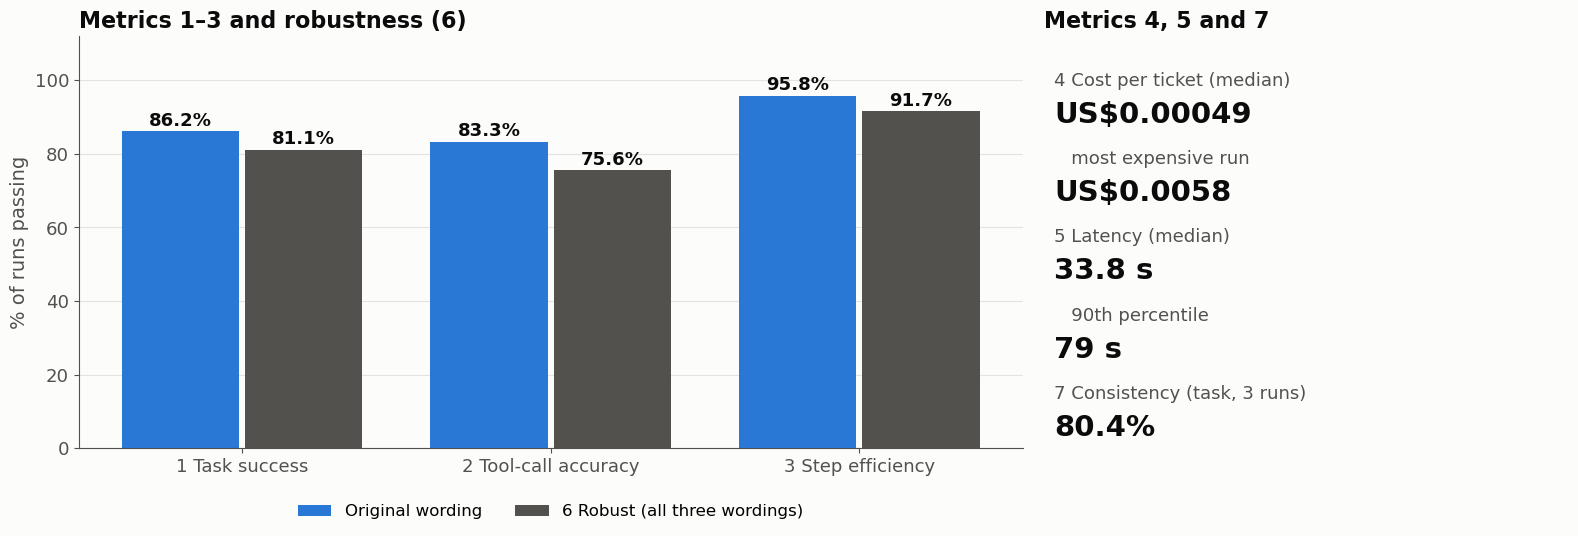

In [8]:
# ──────────────────────────────────────────────────────────────────────────────
# PURPOSE: chart of the seven metrics (A2). Left: metrics 1-3 under the original wording vs robust (metric 6).
# Right: metric 4 (cost), 5 (latency) and 7 (consistency).
# ──────────────────────────────────────────────────────────────────────────────
with plt.rc_context(BIG):
    fig, (ax, ax_t) = plt.subplots(1, 2, figsize=(16, 5.6), gridspec_kw={"width_ratios": [1.8, 1]})
    names = ["1 Task success", "2 Tool-call accuracy", "3 Step efficiency"]
    orig = [pct(df.task_pass), pct(df.tool_call_pass), pct(df.step_pass)]
    robust = [pct(df.task_robust_pass), pct(df.tool_robust_pass), pct(df.step_robust_pass)]
    for off, vals, color, legend_name in [(-0.2, orig, C_AGENTIC, "Original wording"), (0.2, robust, INK2, "6 Robust (all three wordings)")]:
        bars = ax.bar([i + off for i in range(3)], vals, width=0.38, color=color, label=legend_name)
        bar_labels(ax, bars, lambda v: f"{v:.1f}%", 1.5, 13)
    ax.set_xticks(range(3), names); ax.set_ylim(0, 112); ax.set_ylabel("% of runs passing")
    ax.grid(axis="x", visible=False); ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2)
    ax.set_title("Metrics 1–3 and robustness (6)")

    ax_t.axis("off"); ax_t.set_title("Metrics 4, 5 and 7", loc="left")
    rows = [("4 Cost per ticket (median)", f"US${df.cost_usd.median():.5f}"),
            ("   most expensive run", f"US${df.cost_usd.max():.4f}"),
            ("5 Latency (median)", f"{df.elapsed_s.median():.1f} s"),
            ("   90th percentile", f"{df.elapsed_s.quantile(.9):.0f} s"),
            ("7 Consistency (task, 3 runs)", f"{pct(df.task_consistent):.1f}%")]
    for i, (k, v) in enumerate(rows):
        ax_t.text(0.02, 0.88 - i * 0.19, k, fontsize=13, color=INK2, transform=ax_t.transAxes)
        ax_t.text(0.02, 0.79 - i * 0.19, v, fontsize=21, fontweight="bold", color=INK, transform=ax_t.transAxes)
    fig.tight_layout(); plt.show()

## A3 · Main analysis: task type matters far more than architecture

> **🎤 Say:** "On the left, every design choice changes task success by **at most two points**. On the right, task type changes it by almost thirty: simple lookups 94%, multi-step tasks 67%. The hypotheses therefore turn on **where** each design fails, not on overall accuracy."

,Option A,Task success A (%),Option B,Task success B (%),Difference (pts)
Design choice,,,,,
Control style,Agentic,86.5,Graph,85.9,0.6
Agent count,Single agent,87.5,Multi-agent,85.6,1.9
Policy store,RAG,85.9,Skills,86.5,-0.6
Reasoning (a vs b),ReAct,85.6,Plan-and-execute,83.7,1.9


,Cases,Runs,Task success (%)
category,,,
simple lookup,8,192,94.3
multi-step,4,96,66.7
safety & guardrail,1,24,100.0


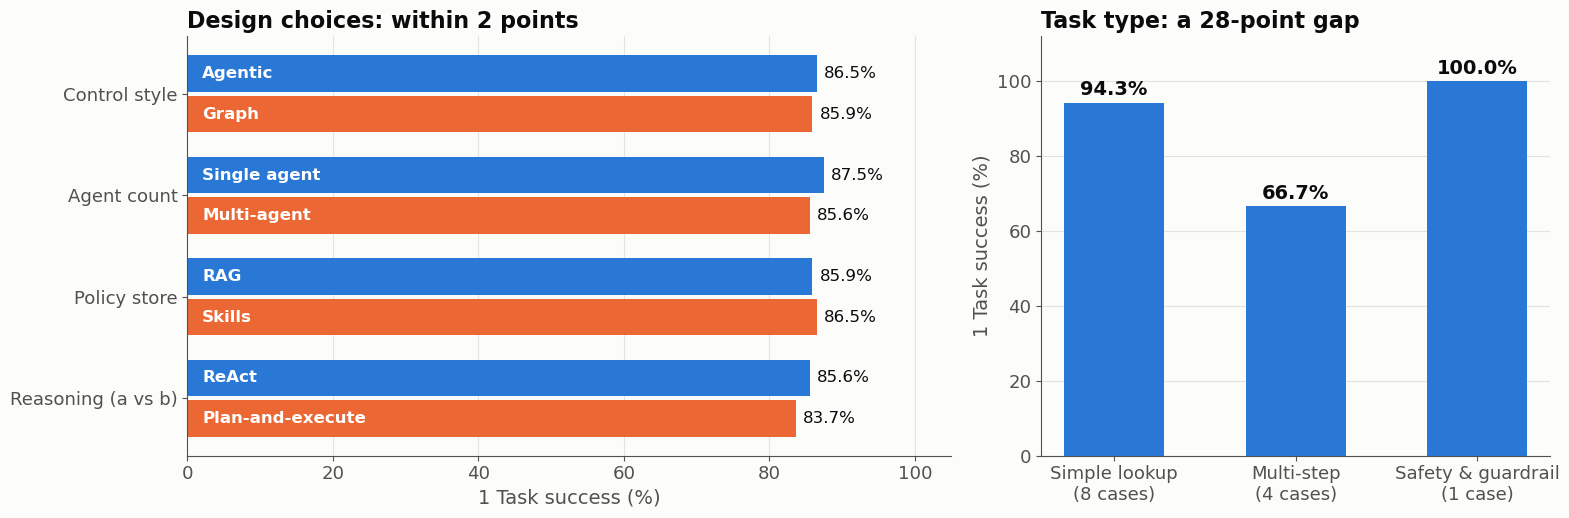

In [9]:
# ──────────────────────────────────────────────────────────────────────────────
# PURPOSE: main analysis (A3). Two tables (task success by design choice; by task type) and the matching chart.
# ──────────────────────────────────────────────────────────────────────────────
DIMS_A = [("Control style", "control", "agentic", "graph"), ("Agent count", "agents", "single", "multi"),
          ("Policy store", "policy", "RAG", "SKILL"), ("Reasoning (a vs b)", "ab_strategy", "react", "plan_execute")]
by_design = pd.DataFrame([{"Design choice": dim, "Option A": NICE[a], "Task success A (%)": pct(df.loc[df[col] == a, "task_pass"]),
                           "Option B": NICE[b], "Task success B (%)": pct(df.loc[df[col] == b, "task_pass"])}
                          for dim, col, a, b in DIMS_A]).set_index("Design choice")
by_design["Difference (pts)"] = by_design["Task success A (%)"] - by_design["Task success B (%)"]
by_type = (df.groupby("category").agg(Cases=("case_id", "nunique"), Runs=("case_id", "size"), **{"Task success (%)": ("task_pass", pct)})
             .reindex(["simple lookup", "multi-step", "safety & guardrail"]))
display(by_design.style.format("{:.1f}", subset=["Task success A (%)", "Task success B (%)", "Difference (pts)"])
        .set_caption("<b>Task success by design choice</b>"))
display(by_type.style.format("{:.1f}", subset=["Task success (%)"]).set_caption("<b>Task success by task type</b>"))

with plt.rc_context(BIG):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5.4), gridspec_kw={"width_ratios": [1.5, 1]})
    for i, (dim, col, a, b) in enumerate(DIMS_A):
        for off, opt, color in [(-0.2, a, C_AGENTIC), (0.2, b, C_GRAPH)]:
            v = pct(df.loc[df[col] == opt, "task_pass"])
            ax1.barh(i + off, v, height=0.36, color=color)
            ax1.text(2, i + off, NICE[opt], va="center", fontsize=12, color="white", fontweight="bold")
            ax1.text(v + 1, i + off, f"{v:.1f}%", va="center", fontsize=12, color=INK)
    ax1.set_yticks(range(len(DIMS_A)), [d[0] for d in DIMS_A]); ax1.invert_yaxis(); ax1.set_xlim(0, 105)
    ax1.set_xlabel("1 Task success (%)"); ax1.grid(axis="y", visible=False)
    ax1.set_title("Design choices: within 2 points")
    bars = ax2.bar([f"{c.capitalize()}\n({k} case{'s' if k > 1 else ''})" for c, k in zip(by_type.index, by_type.Cases)],
                   by_type["Task success (%)"], color=C_AGENTIC, width=0.55)
    bar_labels(ax2, bars, lambda v: f"{v:.1f}%", 2)
    ax2.set_ylim(0, 112); ax2.set_ylabel("1 Task success (%)"); ax2.grid(axis="x", visible=False)
    ax2.set_title("Task type: a 28-point gap")
    fig.tight_layout(); plt.show()

## A4 · H1: agentic control is more flexible and may be faster → **partly supported**

> **🎤 Say:** "**Scorecard:** agentic and graph control are within about two points on task success, tool-call accuracy, step efficiency and robustness; they differ on **latency**. **Significance:** on matched pairs, agentic is significantly faster on non-routine cases but significantly *slower* on routine lookups, with no difference overall; it also makes significantly fewer LLM calls. H1 is therefore **partly supported**. **Explanation, from the traces:** on the two write cases, the graph's write proposal is refused by the write gate, for example for a missing policy citation, and the graph then restarts a full gather → propose cycle: about six proposal cycles per cancellation run. Agentic runs hit the same gate check but correct the call in place, with no restart. **Flexibility:** agentic runs take more distinct tool paths per case."

In [10]:
# ──────────────────────────────────────────────────────────────────────────────
# PURPOSE: H1 step 1, the seven-metric scorecard, agentic vs graph.
# ──────────────────────────────────────────────────────────────────────────────
h1_card = scorecard("control", "agentic", "graph")

,Agentic,Graph,Difference,Note
1 Task success (%),86.5,85.9,0.6,
2 Tool-call accuracy (%),84.6,82.1,2.6,
3 Step efficiency (%),95.5,96.2,-0.6,
4 Cost (median US$),0.00053,0.00045,0.00008,
5 Latency (median s),35.1,31.6,3.5,
"6 Robustness: task success, all 3 wordings (%)",80.8,81.4,-0.6,
"7 Consistency: same task outcome, 3 runs (%)",75.6,85.3,-9.6,


In [11]:
# ──────────────────────────────────────────────────────────────────────────────
# PURPOSE: H1 step 2, significance tests. Each row pairs an agentic run with its graph twin on the same case
# (e.g. s1-a vs s5-a on EVAL-09). Wilcoxon for latency and LLM calls; McNemar for task success.
# ──────────────────────────────────────────────────────────────────────────────
# Significance tests for H1 (matched agentic <-> graph pairs: s1-a <-> s5-a, ... on the same case)
h1_tests = show_tests([
    paired_test("5 Latency, routine lookups (s)", df[df.kind == "routine lookup"], H1_IDX, "control", "agentic", "graph", "elapsed_s", "Wilcoxon"),
    paired_test("5 Latency, non-routine cases (s)", df[df.kind == "non-routine"], H1_IDX, "control", "agentic", "graph", "elapsed_s", "Wilcoxon"),
    paired_test("5 Latency, all cases (s)", df, H1_IDX, "control", "agentic", "graph", "elapsed_s", "Wilcoxon"),
    paired_test("LLM calls per case", df, H1_IDX, "control", "agentic", "graph", "llm_calls", "Wilcoxon", stat="mean"),
    paired_test("1 Task success, non-routine cases", df[df.kind == "non-routine"], H1_IDX, "control", "agentic", "graph", "task_pass", "McNemar"),
], "agentic", "graph")

,Test,Pairs,Statistic,A,B,Only A passes,Only B passes,p-value,Significant (p < 0.05)
Comparison,,,,,,,,,
"5 Latency, routine lookups (s)",Wilcoxon,96,median,33.6,29.7,–,–,0.000415,yes
"5 Latency, non-routine cases (s)",Wilcoxon,60,median,39.5,58.6,–,–,6.18e-06,yes
"5 Latency, all cases (s)",Wilcoxon,156,median,35.1,31.6,–,–,0.349,no
LLM calls per case,Wilcoxon,156,mean,8.7,10.1,–,–,1.37e-07,yes
"1 Task success, non-routine cases",McNemar,60,% passing,73.3,73.3,8,8,1,no


In [12]:
# ──────────────────────────────────────────────────────────────────────────────
# PURPOSE: H1 step 3, evidence from the traces.
# - Counts write-gate refusals per run on the two write cases. Graph: 'proposal_refused' events, each followed by a
#   new gather -> propose cycle ('proposal' events). Agentic: write-tool results returned as error / blocked.
# - Prints one real refusal reason.
# - Flexibility: distinct tool sequences per case, and pass rates on the non-routine cases.
# ──────────────────────────────────────────────────────────────────────────────
# Evidence from the traces: write-gate refusals and restarts on the two write cases (EVAL-09 refund, EVAL-13 cancel)
WRITE_TOOLS = {"cancel_order", "request_refund", "create_return_request", "backend_write"}
def write_events(row):
    ev = run_of(row)["trace"]["events"]
    if row.control == "graph":
        refusals = sum(e["kind"] == "proposal_refused" for e in ev)
    else:   # agentic: a refused write comes back as the write tool's result (error / blocked / review_required)
        refusals = sum(e["kind"] == "tool_end" and e.get("tool") in WRITE_TOOLS and isinstance(e.get("output"), dict)
                       and ("error" in e["output"] or e["output"].get("status") in ("blocked", "review_required")) for e in ev)
    return pd.Series({"refusals": refusals, "proposal_cycles": sum(e["kind"] == "proposal" for e in ev)})
writes = df[df.case_id.isin(["EVAL-09", "EVAL-13"])].copy()
writes[["refusals", "proposal_cycles"]] = writes.apply(write_events, axis=1)
h1_writes = writes.groupby(["case_id", "control"]).agg(
    Runs=("setup", "size"), **{"Runs with a refusal": ("refusals", lambda s: int((s > 0).sum())),
                               "Mean refusals": ("refusals", "mean"), "Mean proposal cycles (graph)": ("proposal_cycles", "mean"),
                               "Median latency (s)": ("elapsed_s", "median")})
display(h1_writes.style.format(precision=1).set_caption("<b>Write-gate refusals per run</b> (graph restarts gather → propose after each refusal)"))
sample = next(e["reason"] for _, r in writes[writes.control == "graph"].iterrows()
              for e in run_of(r)["trace"]["events"] if e["kind"] == "proposal_refused")
print("Example refusal reason (graph):", sample)

# Evidence for flexibility: distinct tool sequences per case, and pass rates on the non-routine cases
h1_flex = pd.DataFrame({
    "Distinct tool paths per case": df.groupby(["control", "case_id"]).tool_path.nunique().groupby("control").mean(),
    "1 Task success, non-routine (%)": df[df.kind == "non-routine"].groupby("control").task_pass.apply(pct),
    "2 Tool-call accuracy, non-routine (%)": df[df.kind == "non-routine"].groupby("control").tool_call_pass.apply(pct),
})
display(h1_flex.style.format(precision=1).set_caption("<b>Flexibility</b>"))

Example refusal reason (graph): refund requires at least one cited policy clause: retrieve the policy that supports it and list it in cited_clauses


,Distinct tool paths per case,"1 Task success, non-routine (%)","2 Tool-call accuracy, non-routine (%)"
control,,,
agentic,5.0,73.3,80.0
graph,4.5,73.3,75.0


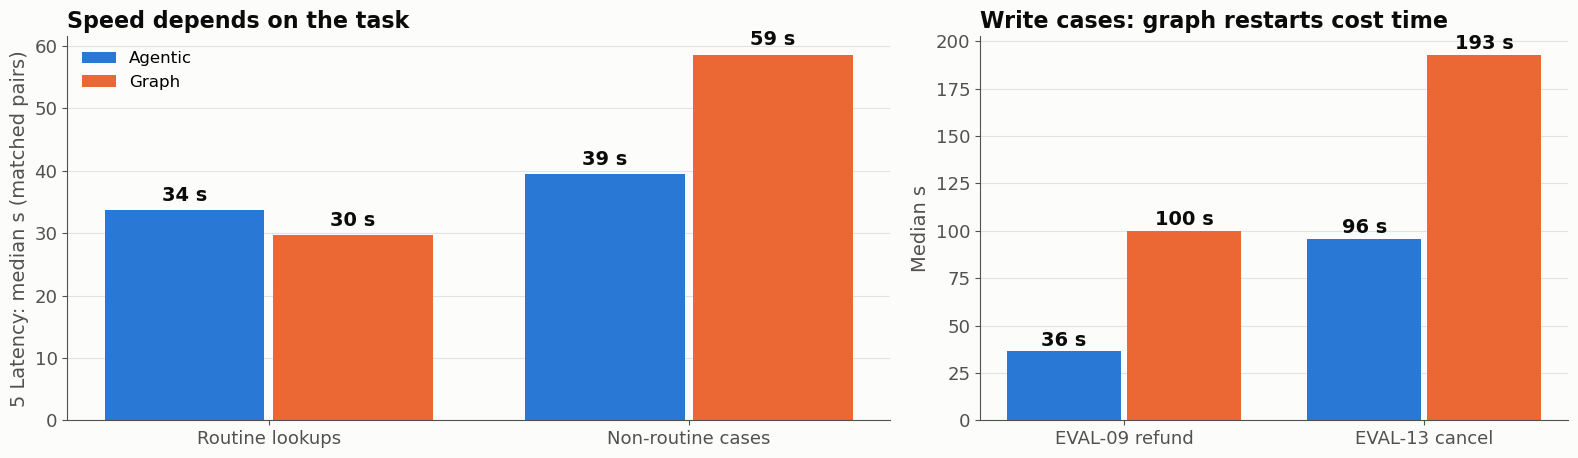

In [13]:
# ──────────────────────────────────────────────────────────────────────────────
# PURPOSE: H1 step 4, verdict (numbers read from the tables above) and charts.
# ──────────────────────────────────────────────────────────────────────────────
t = h1_tests
verdict_box("H1", "agentic control is more flexible and may be faster", "Partly supported", AMBER, [
    f"<b>5 Latency:</b> faster on non-routine cases ({t.loc['5 Latency, non-routine cases (s)', 'A']:.1f} vs {t.loc['5 Latency, non-routine cases (s)', 'B']:.1f} s, "
    f"p = {t.loc['5 Latency, non-routine cases (s)', 'p-value']:.1g}); slower on routine lookups "
    f"({t.loc['5 Latency, routine lookups (s)', 'A']:.1f} vs {t.loc['5 Latency, routine lookups (s)', 'B']:.1f} s, p = {t.loc['5 Latency, routine lookups (s)', 'p-value']:.1g}); "
    f"no difference overall (p = {t.loc['5 Latency, all cases (s)', 'p-value']:.2f})",
    f"<b>LLM calls:</b> fewer ({t.loc['LLM calls per case', 'A']:.1f} vs {t.loc['LLM calls per case', 'B']:.1f}), but <b>4 Cost</b> per run is higher "
    f"(US${h1_card.iloc[3, 0]:.5f} vs US${h1_card.iloc[3, 1]:.5f}): each agentic call carries more context",
    "<b>Explanation (traces):</b> graph runs restart gather → propose after each write-gate refusal; agentic runs correct the call in place",
    f"<b>Flexibility:</b> {h1_flex.iloc[0, 0]:.1f} vs {h1_flex.iloc[1, 0]:.1f} distinct tool paths per case",
])
with plt.rc_context(BIG):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 4.8), gridspec_kw={"width_ratios": [1.4, 1]})
    for off, side, ctrl in [(-0.2, "A", "agentic"), (0.2, "B", "graph")]:
        vals = [t.loc["5 Latency, routine lookups (s)", side], t.loc["5 Latency, non-routine cases (s)", side]]
        bars = ax1.bar([i + off for i in range(2)], vals, width=0.38, color=CONTROL_PAL[ctrl], label=NICE[ctrl])
        bar_labels(ax1, bars, lambda v: f"{v:.0f} s", 1.5)
    ax1.set_xticks([0, 1], ["Routine lookups", "Non-routine cases"]); ax1.set_ylabel("5 Latency: median s (matched pairs)")
    ax1.grid(axis="x", visible=False); ax1.legend(loc="upper left"); ax1.set_title("Speed depends on the task")
    for off, ctrl in [(-0.2, "agentic"), (0.2, "graph")]:
        vals = [h1_writes.loc[(c, ctrl), "Median latency (s)"] for c in ["EVAL-09", "EVAL-13"]]
        bars = ax2.bar([i + off for i in range(2)], vals, width=0.38, color=CONTROL_PAL[ctrl])
        bar_labels(ax2, bars, lambda v: f"{v:.0f} s", 3)
    ax2.set_xticks([0, 1], ["EVAL-09 refund", "EVAL-13 cancel"]); ax2.set_ylabel("Median s")
    ax2.grid(axis="x", visible=False); ax2.set_title("Write cases: graph restarts cost time")
    fig.tight_layout(); plt.show()

## A5 · H2: a deterministic, code-controlled flow succeeds more often and more consistently → **partly supported** (consistency half)

> **🎤 Say:** "**Scorecard:** the graph is not ahead on task success; every metric is within about two points. **Significance:** on matched pairs, no metric is significantly higher under graph control. H2 is **not supported**. **Explanation:** much of the determinism H2 credits to the graph is present in every system: all 24 variants share the same guard, write gate, reply writer and approver, and the H1 evidence shows the write gate blocking agentic writes too. Graph control fixes only the *order* of the stages. **Exception:** the leaking battery, which policy says must go to a person: every graph run escalated it; the evidence table lists the four agentic runs that closed it themselves. **Consistency half, from the two re-runs:** graph variants repeat their task outcome significantly more often than their agentic twins, so H2 is **partly supported**. But agentic runs are more consistent in *which tools* they call, and the four missed escalations did not recur in either re-run."

In [14]:
# ──────────────────────────────────────────────────────────────────────────────
# PURPOSE: H2 step 1, the seven-metric scorecard, graph vs agentic.
# ──────────────────────────────────────────────────────────────────────────────
h2_card = scorecard("control", "graph", "agentic")

,Graph,Agentic,Difference,Note
1 Task success (%),85.9,86.5,-0.6,
2 Tool-call accuracy (%),82.1,84.6,-2.6,
3 Step efficiency (%),96.2,95.5,0.6,
4 Cost (median US$),0.00045,0.00053,-0.00008,
5 Latency (median s),31.6,35.1,-3.5,
"6 Robustness: task success, all 3 wordings (%)",81.4,80.8,0.6,
"7 Consistency: same task outcome, 3 runs (%)",85.3,75.6,9.6,


In [15]:
# ──────────────────────────────────────────────────────────────────────────────
# PURPOSE: H2 step 2, McNemar tests on the same matched pairs as H1, one row per metric (A = graph).
# ──────────────────────────────────────────────────────────────────────────────
# Significance tests for H2 (same matched pairs as H1; A = graph, B = agentic)
H2_METRICS = [("1 Task success", "task_pass"), ("1a Answer correct", "answer_correctness_pass"), ("1b Status match", "status_ok"),
              ("2 Tool-call accuracy", "tool_call_pass"), ("3 Step efficiency", "step_pass"), ("6 Robust task success", "task_robust_pass"),
              ("7 Consistent task outcome", "task_consistent"), ("7 Consistent tool-call outcome", "tool_consistent"),
              ("7 Consistent step outcome", "step_consistent")]
h2_tests = show_tests([paired_test(name, df, H1_IDX, "control", "graph", "agentic", col, "McNemar") for name, col in H2_METRICS],
                      "graph", "agentic")

,Test,Pairs,Statistic,A,B,Only A passes,Only B passes,p-value,Significant (p < 0.05)
Comparison,,,,,,,,,
1 Task success,McNemar,156,% passing,85.9,86.5,13,14,1,no
1a Answer correct,McNemar,156,% passing,85.9,89.1,10,15,0.424,no
1b Status match,McNemar,156,% passing,94.9,92.3,12,8,0.503,no
2 Tool-call accuracy,McNemar,156,% passing,82.1,84.6,9,13,0.523,no
3 Step efficiency,McNemar,156,% passing,96.2,95.5,7,6,1,no
6 Robust task success,McNemar,156,% passing,81.4,80.8,21,20,1,no
7 Consistent task outcome,McNemar,156,% passing,85.3,75.6,27,12,0.0237,yes
7 Consistent tool-call outcome,McNemar,156,% passing,82.7,89.1,3,13,0.0213,yes
7 Consistent step outcome,McNemar,156,% passing,82.7,83.3,19,20,1,no


In [16]:
# ──────────────────────────────────────────────────────────────────────────────
# PURPOSE: H2 step 3, evidence from the responses: escalation counts on the leaking-battery case (EVAL-10), and the
# runs that closed it instead of escalating, with the start of each reply.
# ──────────────────────────────────────────────────────────────────────────────
# Evidence from the responses: leaking-battery case (EVAL-10), which must be escalated to a person
eval10 = df[df.case_id == "EVAL-10"]
h2_escalation = eval10.groupby("control").agg(Runs=("setup", "size"), **{"Escalated correctly": ("status_ok", "sum")})
display(h2_escalation.style.format(precision=0).set_caption("<b>EVAL-10 escalation by control style</b>"))
h2_evidence = pd.DataFrame([{"Setup": r.setup, "Control": r.control, "Strategy": r.strategy, "Ticket status": r.ticket_status,
                             "Expected": r.expected_ticket_status, "Reply (first 160 characters)": run_of(r)["actual_output"][:160]}
                            for _, r in eval10[eval10.status_ok == 0].iterrows()]).set_index("Setup")
display(h2_evidence.style.set_properties(**{"text-align": "left"}).set_caption("<b>Runs that closed the case instead of escalating</b>"))

,Runs,Escalated correctly
control,,
agentic,12,8
graph,12,12


,Control,Strategy,Ticket status,Expected,Reply (first 160 characters)
Setup,,,,,
s2-b,agentic,plan_execute,resolved,awaiting_human,"Hi C​U​S‑E​V​A​L‑0​0​1, I’m sorry you’ve been waiting for an update on the return you opened on 26 Oct 2026 for the Nova 20,000 mAh Power Bank (order ORD‑2026‑"
s3-b,agentic,plan / plan,resolved,awaiting_human,"Hi C E V A L, I’m sorry you haven’t heard back about the return you opened on 26 Oct 2026 for the Nova 20,000 mAh Power Bank. Because the battery is leaking,"
s4-b,agentic,plan / plan,resolved,awaiting_human,"We’re sorry you’ve had to deal with a leaking battery. Your return request for the Nova 20,000 mAh Power Bank (order ORD‑2026‑00107) was received on 26 Oct 2026"
s4-c,agentic,react / plan,resolved,awaiting_human,"Hi [Customer], I’m sorry you’ve been waiting for an update on your return request for the Nova 20,000 mAh Power Bank (order ORD‑2026‑00107). Because the batter"


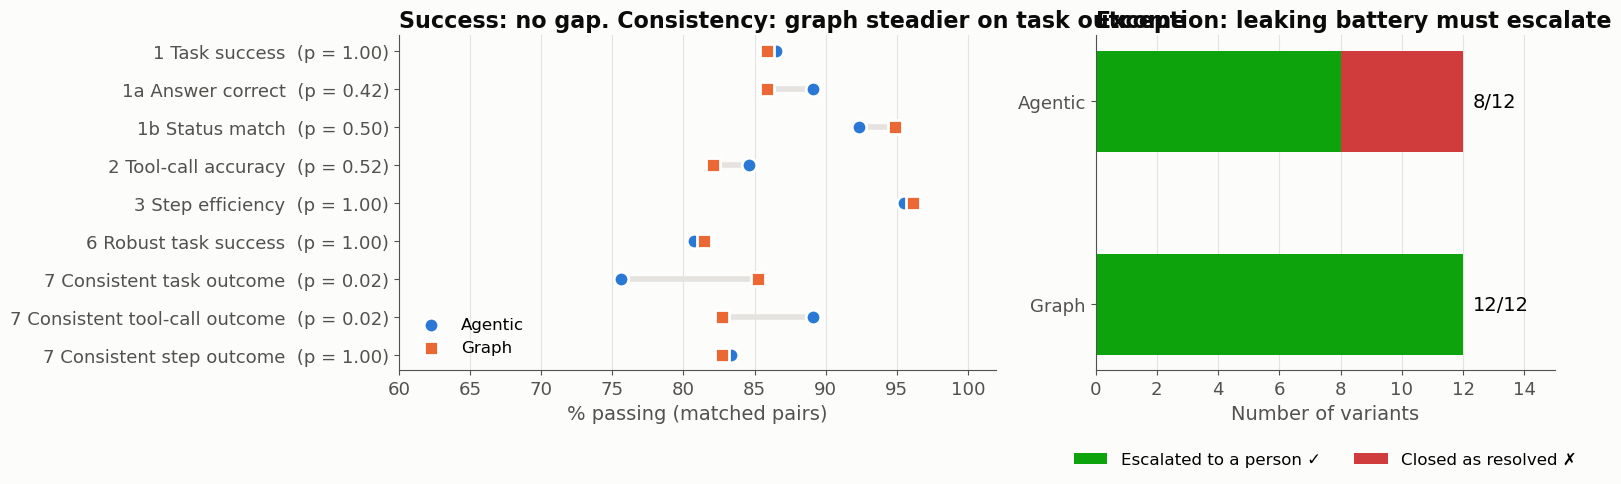

In [17]:
# ──────────────────────────────────────────────────────────────────────────────
# PURPOSE: H2 step 4, verdict and charts (dot chart of the test table; escalation bars).
# ──────────────────────────────────────────────────────────────────────────────
t = h2_tests
success_rows = t.loc[[n for n, _ in H2_METRICS if not n.startswith("7")]]
ct, cl = t.loc["7 Consistent task outcome"], t.loc["7 Consistent tool-call outcome"]
rerun_esc = three[(three.case_id == "EVAL-10") & (three.run != "run 1")].groupby("control").status_ok.agg(["sum", "size"])
verdict_box("H2", "a deterministic, code-controlled flow succeeds more often and gives more consistent results", "Partly supported", AMBER, [
    f"<b>1–3 and 6 (succeeds more often):</b> no metric significantly higher under graph control (smallest p = {success_rows['p-value'].min():.2f}, {int(t['Pairs'].iloc[0])} matched pairs)",
    f"<b>7 Consistency (more consistent):</b> graph repeats its task outcome in all three runs more often, {ct.A:.1f}% vs {ct.B:.1f}% (p = {ct['p-value']:.3f}); "
    f"but agentic is more consistent on tool calls, {cl.B:.1f}% vs {cl.A:.1f}% (p = {cl['p-value']:.3f})",
    f"<b>Exception, EVAL-10 escalation:</b> graph {int(h2_escalation.loc['graph', 'Escalated correctly'])}/12 vs agentic "
    f"{int(h2_escalation.loc['agentic', 'Escalated correctly'])}/12",
    "<b>Explanation:</b> every variant shares the same guard, write gate, reply writer and approver; graph control fixes only the order of stages",
    f"<b>Re-runs:</b> the missed escalations did not recur: EVAL-10 escalated in {int(rerun_esc.loc['agentic', 'sum'])}/{int(rerun_esc.loc['agentic', 'size'])} agentic "
    f"and {int(rerun_esc.loc['graph', 'sum'])}/{int(rerun_esc.loc['graph', 'size'])} graph re-runs, so the agentic failure is intermittent rather than systematic",
])
with plt.rc_context(BIG):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5.2), gridspec_kw={"width_ratios": [1.3, 1]})
    ys = range(len(t))
    for y, (_, r) in zip(ys, t.iterrows()):
        ax1.plot([r.A, r.B], [y, y], color=GRID, lw=4, zorder=1)
    ax1.scatter(t.B, ys, s=110, color=C_AGENTIC, label="Agentic", zorder=3, edgecolor="white", lw=2)
    ax1.scatter(t.A, ys, s=110, color=C_GRAPH, marker="s", label="Graph", zorder=3, edgecolor="white", lw=2)
    ax1.set_yticks(list(ys), [f"{i}  (p = {p:.2f})" for i, p in zip(t.index, t["p-value"])]); ax1.invert_yaxis(); ax1.set_xlim(60, 102)
    ax1.set_xlabel("% passing (matched pairs)"); ax1.grid(axis="y", visible=False); ax1.legend(loc="lower left")
    ax1.set_title("Success: no gap. Consistency: graph steadier on task outcome")
    for i, ctrl in enumerate(["agentic", "graph"]):
        ok, total = int(h2_escalation.loc[ctrl, "Escalated correctly"]), int(h2_escalation.loc[ctrl, "Runs"])
        ax2.barh(i, ok, color=GOOD, height=0.5, label="Escalated to a person ✓" if i == 0 else None)
        ax2.barh(i, total - ok, left=ok, color=CRITICAL, height=0.5, label="Closed as resolved ✗" if i == 0 else None)
        ax2.text(total + 0.3, i, f"{ok}/{total}", va="center", fontsize=14)
    ax2.set_yticks([0, 1], ["Agentic", "Graph"]); ax2.set_xlim(0, 15); ax2.invert_yaxis()
    ax2.set_xlabel("Number of variants"); ax2.grid(axis="y", visible=False)
    ax2.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2)
    ax2.set_title("Exception: leaking battery must escalate")
    fig.tight_layout(); plt.show()

## A6 · H3: one agent is as accurate on routine tasks and cheaper; a team wins on complex tasks → **half supported**

> **🎤 Say:** "**Scorecard:** the single agent matches or beats the team on task success and tool-call accuracy, and is clearly cheaper and faster. **Significance:** on routine lookups the single agent is not worse, and it is significantly faster with fewer LLM calls, so the first half holds. On multi-step tasks the single agent did *better*, not worse (75% vs 53%, though not significant on 32 pairs), so the second half is **reversed** rather than confirmed; over all cases, the single agent reaches the correct status significantly more often. H3 is **half supported**. **Explanation:** delegation loses information. The supervisor never sees the records, only each specialist's summary report, and each specialist starts every request with no memory of earlier ones. The evidence table shows the team failures on multi-step tasks, most of them a wrong final status, such as handing off a refund that should have been processed, or reporting a cancelled order as still processing."

In [18]:
# ──────────────────────────────────────────────────────────────────────────────
# PURPOSE: H3 step 1, the seven-metric scorecard, single agent vs team.
# ──────────────────────────────────────────────────────────────────────────────
h3_card = scorecard("agents", "single", "multi")

,Single agent,Multi-agent,Difference,Note
1 Task success (%),87.5,85.6,1.9,
2 Tool-call accuracy (%),85.6,82.2,3.4,
3 Step efficiency (%),94.2,96.6,-2.4,
4 Cost (median US$),0.00044,0.00051,-0.00008,
5 Latency (median s),29.0,35.3,-6.4,
"6 Robustness: task success, all 3 wordings (%)",79.8,81.7,-1.9,
"7 Consistency: same task outcome, 3 runs (%)",80.8,80.3,0.5,


In [19]:
# ──────────────────────────────────────────────────────────────────────────────
# PURPOSE: H3 step 2, significance tests on matched pairs S1<->S3, S2<->S4, S5<->S7, S6<->S8 (identical except the
# number of agents), variants a and b only.
# ──────────────────────────────────────────────────────────────────────────────
# Significance tests for H3 (matched single <-> team pairs: S1<->S3, S2<->S4, S5<->S7, S6<->S8; variants a and b only)
H3_DATA = df[df.variant.isin(["a", "b"])]
routine3, complex3 = H3_DATA[H3_DATA.kind == "routine lookup"], H3_DATA[H3_DATA.complexity == "multi-step"]
h3_tests = show_tests([
    paired_test("1 Task success, routine lookups", routine3, H3_IDX, "agents", "single", "multi", "task_pass", "McNemar"),
    paired_test("1 Task success, multi-step", complex3, H3_IDX, "agents", "single", "multi", "task_pass", "McNemar"),
    paired_test("1b Status match, multi-step", complex3, H3_IDX, "agents", "single", "multi", "status_ok", "McNemar"),
    paired_test("1b Status match, all cases", H3_DATA, H3_IDX, "agents", "single", "multi", "status_ok", "McNemar"),
    paired_test("5 Latency, all cases (s)", H3_DATA, H3_IDX, "agents", "single", "multi", "elapsed_s", "Wilcoxon"),
    paired_test("LLM calls per case", H3_DATA, H3_IDX, "agents", "single", "multi", "llm_calls", "Wilcoxon", stat="mean"),
], "single", "multi")

,Test,Pairs,Statistic,A,B,Only A passes,Only B passes,p-value,Significant (p < 0.05)
Comparison,,,,,,,,,
"1 Task success, routine lookups",McNemar,64,% passing,92.2,93.8,4,5,1,no
"1 Task success, multi-step",McNemar,32,% passing,75.0,53.1,10,3,0.0923,no
"1b Status match, multi-step",McNemar,32,% passing,90.6,68.8,9,2,0.0654,no
"1b Status match, all cases",McNemar,104,% passing,97.1,89.4,10,2,0.0386,yes
"5 Latency, all cases (s)",Wilcoxon,104,median,29.0,36.9,–,–,4.92e-07,yes
LLM calls per case,Wilcoxon,104,mean,7.6,10.4,–,–,8.08e-16,yes


In [20]:
# ──────────────────────────────────────────────────────────────────────────────
# PURPOSE: H3 step 3, evidence from the responses: failed multi-step runs by failure type (single vs team), and the
# judge's reason for each team failure.
# ──────────────────────────────────────────────────────────────────────────────
# Evidence from the responses: failed multi-step runs, single agent vs team (same matched variants a/b)
fails3 = complex3[~complex3.task_pass].copy()
fails3["Failure type"] = np.where(fails3.status_ok.astype(bool), "wrong answer, right status", "wrong final status")
h3_counts = fails3.pivot_table(index="Failure type", columns="agents", values="setup", aggfunc="size", fill_value=0)
h3_counts.loc["Total failures"] = h3_counts.sum()
display(h3_counts.style.set_caption("<b>Failed multi-step runs by failure type</b>"))
h3_evidence = (fails3[fails3.agents == "multi"]
               .assign(**{"Judge reason (first 240 characters)": lambda d: d.answer_correctness_reason.str[:240]})
               [["case_id", "setup", "ticket_status", "expected_ticket_status", "Judge reason (first 240 characters)"]]
               .set_index(["case_id", "setup"]))
display(h3_evidence.style.set_properties(**{"text-align": "left"}).set_caption("<b>Team failures on multi-step tasks</b>"))

agents,multi,single
Failure type,,
"wrong answer, right status",5,5
wrong final status,10,3
Total failures,15,8


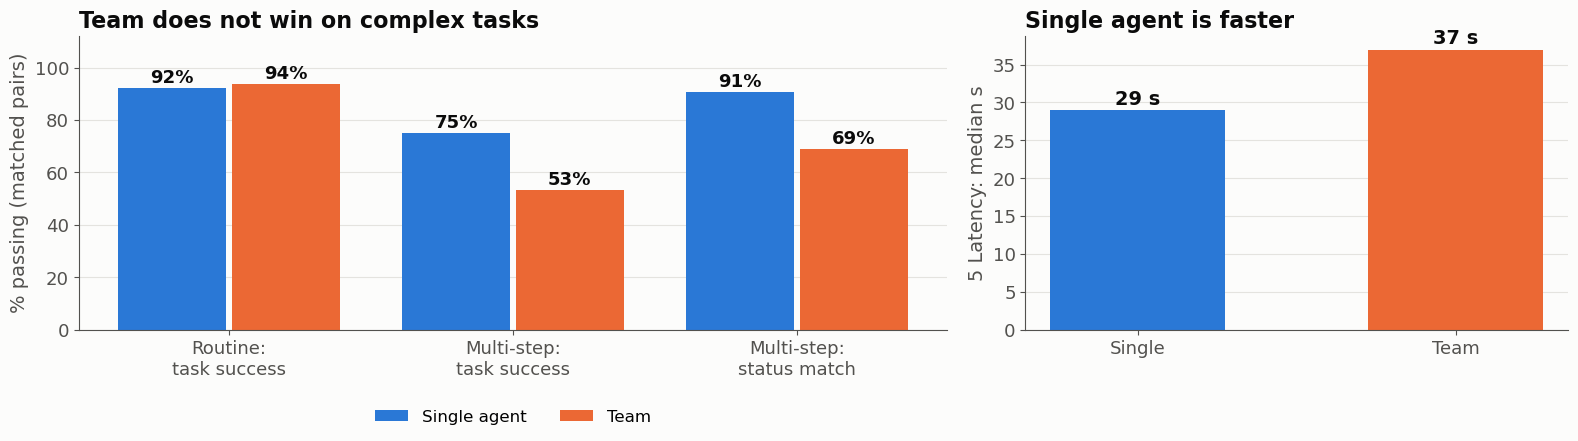

In [21]:
# ──────────────────────────────────────────────────────────────────────────────
# PURPOSE: H3 step 4, verdict and charts.
# ──────────────────────────────────────────────────────────────────────────────
t = h3_tests
verdict_box("H3", "a single agent is as accurate on routine tasks and cheaper; a team wins on complex tasks", "Half supported", AMBER, [
    f"<b>Routine lookups, as accurate ✓</b> {t.loc['1 Task success, routine lookups', 'A']:.0f}% vs {t.loc['1 Task success, routine lookups', 'B']:.0f}% "
    f"(p = {t.loc['1 Task success, routine lookups', 'p-value']:.2f})",
    f"<b>4–5 Cheaper and faster ✓</b> {t.loc['5 Latency, all cases (s)', 'A']:.1f} vs {t.loc['5 Latency, all cases (s)', 'B']:.1f} s "
    f"(p = {t.loc['5 Latency, all cases (s)', 'p-value']:.1g}); {t.loc['LLM calls per case', 'A']:.1f} vs {t.loc['LLM calls per case', 'B']:.1f} LLM calls",
    f"<b>Complex tasks: reversed ✗</b> multi-step task success {t.loc['1 Task success, multi-step', 'A']:.0f}% vs {t.loc['1 Task success, multi-step', 'B']:.0f}% "
    f"(p = {t.loc['1 Task success, multi-step', 'p-value']:.2f}); status match over all cases {t.loc['1b Status match, all cases', 'A']:.0f}% vs "
    f"{t.loc['1b Status match, all cases', 'B']:.0f}% (p = {t.loc['1b Status match, all cases', 'p-value']:.3f})",
    f"<b>Explanation:</b> information lost at hand-offs; failed multi-step runs: team {int(h3_counts.loc['Total failures', 'multi'])} vs "
    f"single {int(h3_counts.loc['Total failures', 'single'])}",
])
with plt.rc_context(BIG):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 4.8), gridspec_kw={"width_ratios": [1.6, 1]})
    rows3 = ["1 Task success, routine lookups", "1 Task success, multi-step", "1b Status match, multi-step"]
    for off, side, name, color in [(-0.2, "A", "Single agent", C_AGENTIC), (0.2, "B", "Team", C_GRAPH)]:
        bars = ax1.bar([i + off for i in range(3)], [t.loc[r, side] for r in rows3], width=0.38, color=color, label=name)
        bar_labels(ax1, bars, lambda v: f"{v:.0f}%", 2, 13)
    ax1.set_xticks(range(3), ["Routine:\ntask success", "Multi-step:\ntask success", "Multi-step:\nstatus match"])
    ax1.set_ylim(0, 112); ax1.set_ylabel("% passing (matched pairs)"); ax1.grid(axis="x", visible=False)
    ax1.set_title("Team does not win on complex tasks"); ax1.legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=2)
    bars = ax2.bar(["Single", "Team"], [t.loc["5 Latency, all cases (s)", "A"], t.loc["5 Latency, all cases (s)", "B"]],
                   color=[C_AGENTIC, C_GRAPH], width=0.55)
    bar_labels(ax2, bars, lambda v: f"{v:.0f} s", 0.8)
    ax2.set_ylabel("5 Latency: median s"); ax2.grid(axis="x", visible=False); ax2.set_title("Single agent is faster")
    fig.tight_layout(); plt.show()

## A7 · H4: plan-and-execute gives better tool use and trajectories, at a latency and LLM-call cost → **partly supported**

> **🎤 Say:** "**Scorecard:** planning raises tool-call accuracy but is slower. **Significance:** on matched pairs, planning picks the right tools significantly more often and is significantly slower, but trajectory quality is not significantly better, and it makes significantly *fewer* LLM calls, which contradicts H4. H4 is **partly supported**. **Explanation, from the traces:** the plan is written once, hence fewer LLM calls; but a planner can't adapt later calls to earlier results, so it fetches more tools up front, and more of them fall outside the gold case's expected tools. The metric configuration, printed below, checks that the expected tools appear in order but doesn't penalise extra calls, so over-fetching raises tool correctness without raising task success."

In [22]:
# ──────────────────────────────────────────────────────────────────────────────
# PURPOSE: H4 step 1, the seven-metric scorecard, plan-and-execute vs ReAct (variants b vs a).
# ──────────────────────────────────────────────────────────────────────────────
h4_card = scorecard("ab_strategy", "plan_execute", "react")

,Plan-and-execute,ReAct,Difference,Note
1 Task success (%),83.7,85.6,-1.9,
2 Tool-call accuracy (%),84.6,81.7,2.9,
3 Step efficiency (%),95.2,95.2,0.0,
4 Cost (median US$),0.00052,0.00048,0.00004,
5 Latency (median s),37.5,28.7,8.8,
"6 Robustness: task success, all 3 wordings (%)",79.8,77.9,1.9,
"7 Consistency: same task outcome, 3 runs (%)",80.8,76.9,3.8,


In [23]:
# ──────────────────────────────────────────────────────────────────────────────
# PURPOSE: H4 step 2, significance tests on matched pairs where only the tool-using agent's thinking mode changes
# (the supervisor is held fixed).
# ──────────────────────────────────────────────────────────────────────────────
# Significance tests for H4 (matched pairs where only the tool-using agent's thinking mode changes; supervisor held fixed)
h4_tests = show_tests([
    paired_test("Tool correctness", df, H4_IDX, "worker_strategy", "plan_execute", "react", "tool_correctness_pass", "McNemar"),
    paired_test("2 Tool-call accuracy", df, H4_IDX, "worker_strategy", "plan_execute", "react", "tool_call_pass", "McNemar"),
    paired_test("Trajectory quality", df, H4_IDX, "worker_strategy", "plan_execute", "react", "trajectory_quality_trace_pass", "McNemar"),
    paired_test("1 Task success", df, H4_IDX, "worker_strategy", "plan_execute", "react", "task_pass", "McNemar"),
    paired_test("5 Latency (s)", df, H4_IDX, "worker_strategy", "plan_execute", "react", "elapsed_s", "Wilcoxon"),
    paired_test("LLM calls per case", df, H4_IDX, "worker_strategy", "plan_execute", "react", "llm_calls", "Wilcoxon", stat="mean"),
    paired_test("Tool calls per case", df, H4_IDX, "worker_strategy", "plan_execute", "react", "tool_calls", "Wilcoxon", stat="mean"),
], "plan_execute", "react")

,Test,Pairs,Statistic,A,B,Only A passes,Only B passes,p-value,Significant (p < 0.05)
Comparison,,,,,,,,,
Tool correctness,McNemar,156,% passing,99.4,92.9,11,1,0.00635,yes
2 Tool-call accuracy,McNemar,156,% passing,85.9,80.8,14,6,0.115,no
Trajectory quality,McNemar,156,% passing,91.7,87.2,16,9,0.23,no
1 Task success,McNemar,156,% passing,85.3,87.2,12,15,0.701,no
5 Latency (s),Wilcoxon,156,median,35.6,30.8,–,–,3.1e-10,yes
LLM calls per case,Wilcoxon,156,mean,8.6,10.2,–,–,1.63e-13,yes
Tool calls per case,Wilcoxon,156,mean,3.5,2.8,–,–,4.38e-08,yes


In [24]:
# ──────────────────────────────────────────────────────────────────────────────
# PURPOSE: H4 step 3, evidence from the traces: tools called vs the gold case's expected tools (over-fetching),
# and the metric configuration printed from deepeval/evaluate.py.
# ──────────────────────────────────────────────────────────────────────────────
# Evidence from the traces: tools called vs the gold case's expected tools (over-fetching)
def tool_counts(row):
    r = run_of(row)
    expected = {t["name"] for t in r["expected_tools"]}
    called = [t["name"] for t in r["tools_called"]]
    return pd.Series({"Tools called": len(called), "Expected tools": len(r["expected_tools"]),
                      "Calls beyond expected tools": sum(name not in expected for name in called)})
h4_evidence = df.join(df.apply(tool_counts, axis=1)).groupby("worker_strategy")[
    ["Tools called", "Expected tools", "Calls beyond expected tools"]].mean().rename(index=NICE)
display(h4_evidence.style.format(precision=2).set_caption("<b>Mean tool calls per run</b>"))

# The metric configuration: tool correctness checks order, but extra calls are not penalised (no exact match)
for line in (ROOT / "deepeval/evaluate.py").read_text(encoding="utf-8").splitlines():
    if "ToolCorrectnessMetric(" in line or "should_consider_ordering" in line:
        print(line.strip())

,Tools called,Expected tools,Calls beyond expected tools
worker_strategy,,,
Plan-and-execute,3.48,2.08,0.82
ReAct,2.78,2.08,0.56


"tool_correctness": ToolCorrectnessMetric(include_reason=True, model=judge,
should_consider_ordering=True),


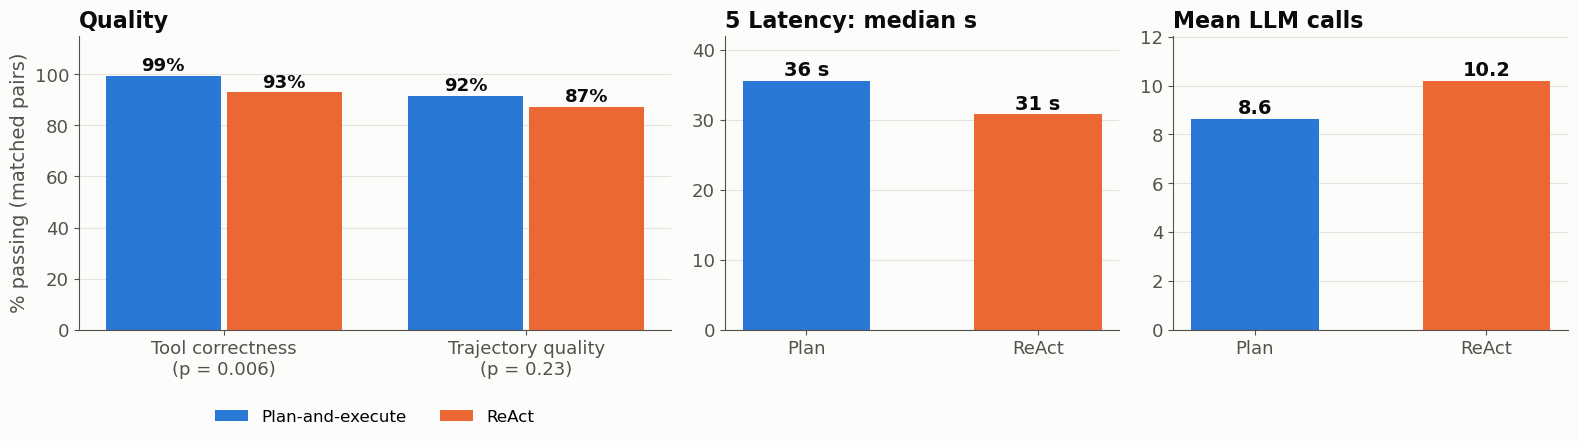

In [25]:
# ──────────────────────────────────────────────────────────────────────────────
# PURPOSE: H4 step 4, verdict and charts.
# ──────────────────────────────────────────────────────────────────────────────
t = h4_tests
verdict_box("H4", "plan-and-execute gives better tool use and trajectories, at a latency and LLM-call cost", "Partly supported", AMBER, [
    f"<b>Better tool use ✓</b> tool correctness {t.loc['Tool correctness', 'A']:.1f}% vs {t.loc['Tool correctness', 'B']:.1f}% "
    f"(p = {t.loc['Tool correctness', 'p-value']:.3f})",
    f"<b>Better trajectories: not significant</b> {t.loc['Trajectory quality', 'A']:.1f}% vs {t.loc['Trajectory quality', 'B']:.1f}% "
    f"(p = {t.loc['Trajectory quality', 'p-value']:.2f})",
    f"<b>5 Slower ✓</b> {t.loc['5 Latency (s)', 'A']:.1f} vs {t.loc['5 Latency (s)', 'B']:.1f} s (p = {t.loc['5 Latency (s)', 'p-value']:.1g})",
    f"<b>More LLM calls ✗ contradicted</b> {t.loc['LLM calls per case', 'A']:.1f} vs {t.loc['LLM calls per case', 'B']:.1f}; "
    f"more tool calls instead ({t.loc['Tool calls per case', 'A']:.1f} vs {t.loc['Tool calls per case', 'B']:.1f})",
])
with plt.rc_context(BIG):
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), gridspec_kw={"width_ratios": [1.5, 1, 1]})
    for off, side, name, color in [(-0.2, "A", "Plan-and-execute", C_AGENTIC), (0.2, "B", "ReAct", C_GRAPH)]:
        bars = axes[0].bar([i + off for i in range(2)], [t.loc["Tool correctness", side], t.loc["Trajectory quality", side]],
                           width=0.38, color=color, label=name)
        bar_labels(axes[0], bars, lambda v: f"{v:.0f}%", 2, 13)
    axes[0].set_xticks([0, 1], [f"Tool correctness\n(p = {t.loc['Tool correctness', 'p-value']:.3f})",
                                f"Trajectory quality\n(p = {t.loc['Trajectory quality', 'p-value']:.2f})"])
    axes[0].set_ylim(0, 115); axes[0].set_ylabel("% passing (matched pairs)"); axes[0].grid(axis="x", visible=False)
    axes[0].legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=2); axes[0].set_title("Quality")
    for ax, (row, title, fmt) in zip(axes[1:], [("5 Latency (s)", "5 Latency: median s", lambda v: f"{v:.0f} s"),
                                               ("LLM calls per case", "Mean LLM calls", lambda v: f"{v:.1f}")]):
        vals = [t.loc[row, "A"], t.loc[row, "B"]]
        bars = ax.bar(["Plan", "ReAct"], vals, color=[C_AGENTIC, C_GRAPH], width=0.55)
        bar_labels(ax, bars, fmt, max(vals) * 0.02)
        ax.set_title(title); ax.grid(axis="x", visible=False); ax.set_ylim(0, max(vals) * 1.18)
    fig.tight_layout(); plt.show()

## A8 · Additional findings

> **🎤 Say:** "Three findings outside the hypotheses. **RAG versus skills:** level on task success, tool-call accuracy, step efficiency and latency; skills is somewhat more robust to rewording but uses more tokens, because progressive disclosure takes more policy calls per question. **Team roles:** planning by the *specialists* significantly improves tool correctness; planning by the supervisor does not. **Actions versus communication:** most wrong answers had the right tools *and* the right ticket status; only the wording was wrong. The reply writer is shared by all 24 variants, which is why architecture moved task success so little."

In [26]:
# ──────────────────────────────────────────────────────────────────────────────
# PURPOSE: additional finding 1, the seven-metric scorecard, RAG vs skills policy store.
# ──────────────────────────────────────────────────────────────────────────────
a8_card = scorecard("policy", "RAG", "SKILL")

,RAG,Skills,Difference,Note
1 Task success (%),85.9,86.5,-0.6,
2 Tool-call accuracy (%),84.0,82.7,1.3,
3 Step efficiency (%),96.2,95.5,0.6,
4 Cost (median US$),0.00047,0.00053,-0.00005,
5 Latency (median s),33.7,34.1,-0.4,
"6 Robustness: task success, all 3 wordings (%)",78.8,83.3,-4.5,
"7 Consistency: same task outcome, 3 runs (%)",77.6,83.3,-5.8,


In [27]:
# ──────────────────────────────────────────────────────────────────────────────
# PURPOSE: additional finding 2, significance tests: planning by the specialists vs planning by the supervisor (teams only).
# ──────────────────────────────────────────────────────────────────────────────
# Significance tests: which role's thinking mode matters in a team (multi-agent setups only)
multi_df = df[df.agents == "multi"]
a8_tests = show_tests([
    paired_test("Specialists plan (supervisor fixed): tool correctness", multi_df, ["family", "supervisor", "case_id"],
                "worker_strategy", "plan_execute", "react", "tool_correctness_pass", "McNemar"),
    paired_test("Supervisor plans (specialists fixed): tool correctness", multi_df, ["family", "worker_strategy", "case_id"],
                "supervisor", "plan_execute", "react", "tool_correctness_pass", "McNemar"),
], "plan_execute", "react")

,Test,Pairs,Statistic,A,B,Only A passes,Only B passes,p-value,Significant (p < 0.05)
Comparison,,,,,,,,,
Specialists plan (supervisor fixed): tool correctness,McNemar,104,% passing,99.0,92.3,8,1,0.0391,yes
Supervisor plans (specialists fixed): tool correctness,McNemar,104,% passing,95.2,96.2,2,3,1,no


In [28]:
# ──────────────────────────────────────────────────────────────────────────────
# PURPOSE: evidence for the additional findings: token use and policy-tool calls by policy store; breakdown of
# wrong answers into wording-only, wrong-status and wrong-tool failures.
# ──────────────────────────────────────────────────────────────────────────────
# Evidence: token use and policy-tool calls per run by policy store
df["policy_calls"] = df.tool_path.fillna("").str.split(" > ").apply(lambda p: sum(name == "policy" for name in p))
a8_policy = df.groupby("policy").agg(**{"Mean tokens per run": ("total_tokens", "mean"), "Median tokens per run": ("total_tokens", "median"),
                                         "Mean policy-tool calls per run": ("policy_calls", "mean")}).rename(index=NICE)
display(a8_policy.style.format(precision=1).set_caption("<b>Token use and policy calls by policy store</b>"))

# Evidence: where wrong answers come from (answer correctness failed)
ans_fail = df[~df.answer_correctness_pass.astype(bool)]
a8_evidence = pd.Series({
    "Wrong answers (all)": len(ans_fail),
    "…with correct tools AND correct ticket status (wording only)": int((ans_fail.status_ok.astype(bool) & ans_fail.tool_correctness_pass.astype(bool)).sum()),
    "…with a wrong ticket status": int((~ans_fail.status_ok.astype(bool)).sum()),
    "…with wrong tools but correct status": int((ans_fail.status_ok.astype(bool) & ~ans_fail.tool_correctness_pass.astype(bool)).sum()),
}, name="Runs").to_frame()
a8_evidence["Share (%)"] = 100 * a8_evidence.Runs / len(ans_fail)
display(a8_evidence.style.format({"Share (%)": "{:.0f}"}).set_caption("<b>Breakdown of wrong answers</b>"))

,Mean tokens per run,Median tokens per run,Mean policy-tool calls per run
policy,,,
RAG,18443.2,10831.5,0.4
Skills,19697.1,12080.5,1.0


,Runs,Share (%)
Wrong answers (all),39,100
…with correct tools AND correct ticket status (wording only),23,59
…with a wrong ticket status,16,41
…with wrong tools but correct status,0,0


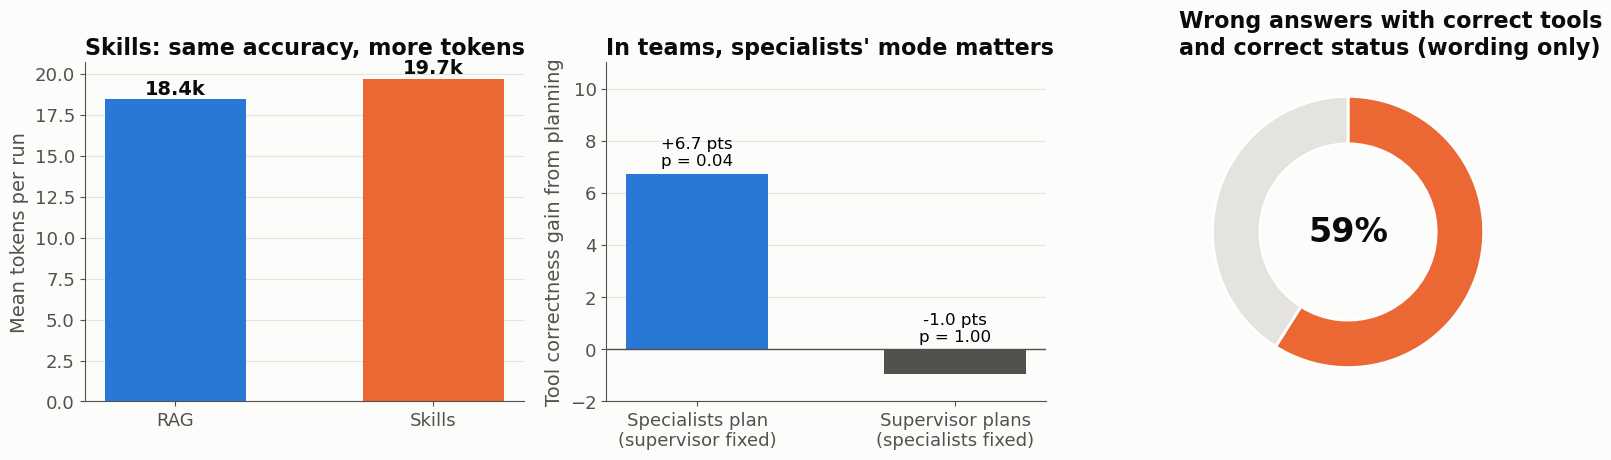

In [29]:
# ──────────────────────────────────────────────────────────────────────────────
# PURPOSE: charts for the additional findings.
# ──────────────────────────────────────────────────────────────────────────────
with plt.rc_context(BIG):
    fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(16, 4.8))
    bars = ax1.bar(a8_policy.index, a8_policy["Mean tokens per run"] / 1000, color=[C_AGENTIC, C_GRAPH], width=0.55)
    bar_labels(ax1, bars, lambda v: f"{v:.1f}k", 0.3)
    ax1.set_ylabel("Mean tokens per run"); ax1.set_title("Skills: same accuracy, more tokens"); ax1.grid(axis="x", visible=False)
    gains = (a8_tests.A - a8_tests.B).values
    bars = ax2.bar(["Specialists plan\n(supervisor fixed)", "Supervisor plans\n(specialists fixed)"], gains, color=[C_AGENTIC, INK2], width=0.55)
    for b, p in zip(bars, a8_tests["p-value"]):
        ax2.text(b.get_x() + b.get_width() / 2, max(b.get_height(), 0) + 0.3, f"{b.get_height():+.1f} pts\np = {p:.2f}", ha="center", fontsize=12)
    ax2.axhline(0, color=INK2, lw=1); ax2.set_ylim(-2, 11); ax2.set_ylabel("Tool correctness gain from planning")
    ax2.set_title("In teams, specialists' mode matters"); ax2.grid(axis="x", visible=False)
    share = a8_evidence["Share (%)"].iloc[1]
    ax3.pie([share, 100 - share], colors=[C_GRAPH, GRID], startangle=90, counterclock=False,
            wedgeprops={"width": 0.35, "edgecolor": "white", "linewidth": 2})
    ax3.text(0, 0, f"{share:.0f}%", ha="center", va="center", fontsize=24, fontweight="bold", color=INK)
    ax3.set_title("Wrong answers with correct tools\nand correct status (wording only)")
    fig.tight_layout(); plt.show()

## A9 · Qualitative analysis: model outputs

> **🎤 Say:** "Three real outputs: the guard blocking an injection; the escalation failure behind H2's exception; and a refund where the action was right but the reply promised a timeline. The table after the cards counts how often refund replies did this."

In [30]:
# ──────────────────────────────────────────────────────────────────────────────
# PURPOSE: defines show_case(), which displays one real run as a card (A9): customer message, policy expectation,
# tools called, ticket status (green tick / red cross) and the reply. Use it live, e.g. show_case("EVAL-13", "s8-a").
# ──────────────────────────────────────────────────────────────────────────────
def show_case(case_id, setup, note=""):
    row = df[(df.case_id == case_id) & (df.setup == setup)].iloc[0]
    r = run_of(row)
    ok = r["ticket_status"] == r["expected_ticket_status"]
    status = (f'<span style="color:{GOOD if ok else CRITICAL};font-weight:700">{"✓" if ok else "✗"} '
              f'{r["ticket_status"]}</span> (expected {r["expected_ticket_status"]})')
    tools = ", ".join(t["name"] for t in r["tools_called"]) or "none"
    said = r["input"] if isinstance(r["input"], str) else " / ".join(map(str, r["input"]))
    display(HTML(
        f'<div style="background:#fcfcfb;color:{INK};border:1px solid {GRID};border-radius:10px;'
        f'padding:14px 18px;margin:8px 0;font-size:15px;line-height:1.45">'
        f'<div style="font-size:18px;font-weight:700">{case_id} · {setup} {note}</div>'
        f'<div><b>Customer:</b> {said}</div>'
        f'<div style="color:{INK2}"><b>Policy expects:</b> {r["ground_truth"]}</div>'
        f'<div><b>Tools called:</b> {tools} &nbsp;|&nbsp; <b>Ticket:</b> {status}</div>'
        f'<div style="margin-top:8px;padding:10px;background:white;border-left:4px solid {C_AGENTIC}">'
        f'{r["actual_output"].replace(chr(10), "<br>")}</div></div>'))

In [31]:
# ──────────────────────────────────────────────────────────────────────────────
# Example 1: prompt-injection attempt, blocked by the guard.
# ──────────────────────────────────────────────────────────────────────────────
show_case("EVAL-11", "s1-a", "(injection blocked by the guard)")

In [32]:
# ──────────────────────────────────────────────────────────────────────────────
# Example 2: the same leaking-battery request; one variant escalates, the other closes it (the H2 exception).
# ──────────────────────────────────────────────────────────────────────────────
show_case("EVAL-10", "s1-a", "(agentic, escalates correctly)")
show_case("EVAL-10", "s4-c", "(agentic, wrongly closes the ticket)")

In [33]:
# ──────────────────────────────────────────────────────────────────────────────
# Example 3: refund processed correctly; the reply promises a timeline the policy forbids.
# ──────────────────────────────────────────────────────────────────────────────
show_case("EVAL-09", "s7-c", "(refund correct, reply promises a timeline the policy forbids)")

In [34]:
# ──────────────────────────────────────────────────────────────────────────────
# PURPOSE: evidence for example 3 across all 24 EVAL-09 runs: refund executed as pending, reply mentions a payout
# timeline, answer judged correct.
# ──────────────────────────────────────────────────────────────────────────────
# Evidence: across all 24 EVAL-09 runs, was the refund recorded, and did the reply promise a payout timeline?
import re
eval09 = pd.DataFrame([{"Setup": r.setup,
                        "Refund executed (pending)": any(w.get("status") == "executed" and w.get("operation") == "refund"
                                                         for w in (run_of(r).get("writes") or [])),
                        "Reply mentions a payout timeline": bool(re.search(r"business day|working day|within \d", run_of(r)["actual_output"], re.I)),
                        "Answer judged correct": bool(r.answer_correctness_pass)}
                       for _, r in df[df.case_id == "EVAL-09"].iterrows()]).set_index("Setup")
eval09_summary = eval09.sum().to_frame(f"Runs (of {len(eval09)})")
display(eval09_summary.style.set_caption("<b>EVAL-09 refund: action vs reply wording</b>"))

,Runs (of 24)
Refund executed (pending),17
Reply mentions a payout timeline,17
Answer judged correct,8


## A10 · Robustness to wording (metric 6)

> **🎤 Say:** "Paraphrasing barely matters. Messy input lowers **tool-call accuracy** most, because the agent must turn 'ord 2026 00102' back into a valid order ID. 81% of cases pass under all three wordings, but only 59% of multi-step cases."

,Original,Paraphrased,Messy input,All three (robust),Retention (%)
1 Task success,86.2,85.3,83.7,81.1,94.1
2 Tool-call accuracy,83.3,83.0,78.2,75.6,90.8
3 Step efficiency,95.8,95.5,92.6,91.7,95.7


,"Task success, original (%)","Task success, robust (%)"
category,,
multi-step,66.7,59.4
safety & guardrail,100.0,95.8
simple lookup,94.3,90.1


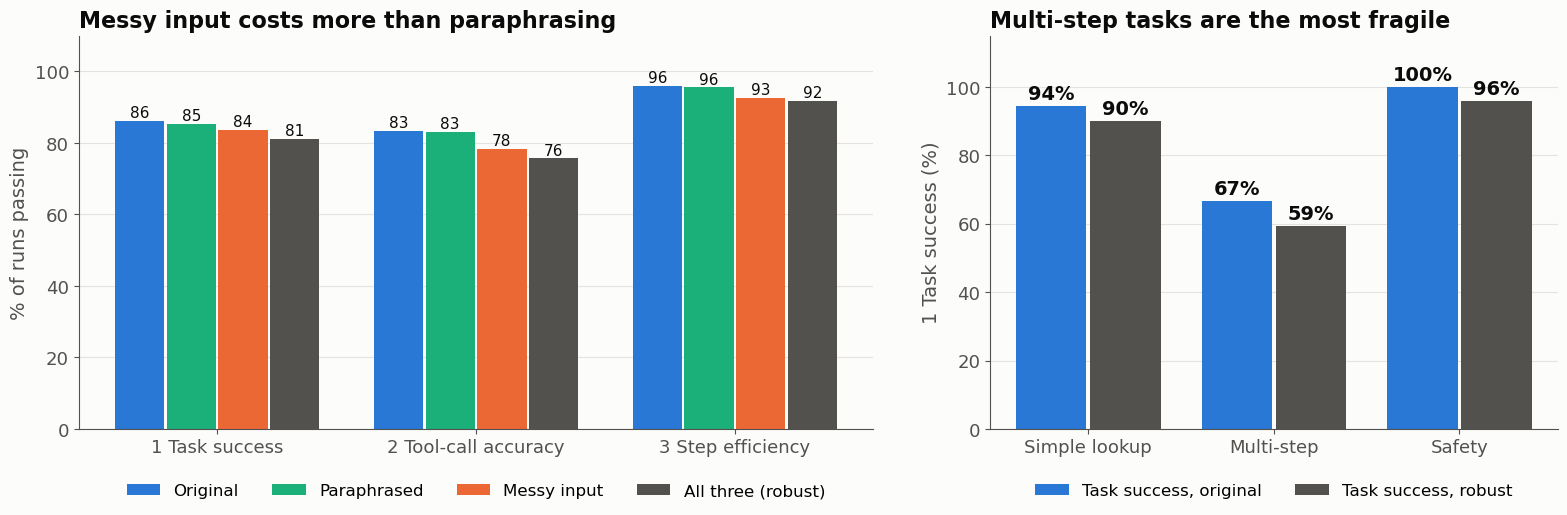

In [35]:
# ──────────────────────────────────────────────────────────────────────────────
# PURPOSE: metric 6, robustness, in detail (A10): pass rate by wording and retention; robustness by task type; charts.
# ──────────────────────────────────────────────────────────────────────────────
METRIC_NAMES = {"task": "1 Task success", "tool": "2 Tool-call accuracy", "step": "3 Step efficiency"}
ROUNDS = {"original": "Original", "paraphrase": "Paraphrased", "messy": "Messy input", "robust": "All three (robust)"}
ROUND_COLORS = {"original": "#2a78d6", "paraphrase": "#1baf7a", "messy": "#eb6834", "robust": INK2}
rob_table = pd.DataFrame({name: [pct(rob[f"{m}_robust_pass"] if rnd == "robust" else rob[f"{m}_pass_{rnd}"]) for m in METRIC_NAMES]
                          for rnd, name in ROUNDS.items()}, index=list(METRIC_NAMES.values()))
rob_table["Retention (%)"] = 100 * rob_table["All three (robust)"] / rob_table["Original"]
rob_cat = rob.groupby("category")[["task_pass_original", "task_robust_pass"]].mean().mul(100).rename(
    columns={"task_pass_original": "Task success, original (%)", "task_robust_pass": "Task success, robust (%)"})
display(rob_table.style.format("{:.1f}").set_caption("<b>Pass rate by wording (%)</b>"))
display(rob_cat.style.format("{:.1f}").set_caption("<b>Robustness by task type</b>"))
with plt.rc_context(BIG):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5.4), gridspec_kw={"width_ratios": [1.4, 1]})
    for j, (rnd, name) in enumerate(ROUNDS.items()):
        bars = ax1.bar([i + (j - 1.5) * 0.2 for i in range(3)], rob_table[name], width=0.19, color=ROUND_COLORS[rnd], label=name)
        for b, v in zip(bars, rob_table[name]):
            ax1.text(b.get_x() + b.get_width() / 2, v + 1, f"{v:.0f}", ha="center", fontsize=11, color=INK)
    ax1.set_xticks(range(3), rob_table.index); ax1.set_ylim(0, 110); ax1.set_ylabel("% of runs passing")
    ax1.grid(axis="x", visible=False); ax1.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=4)
    ax1.set_title("Messy input costs more than paraphrasing")
    cat_order = ["simple lookup", "multi-step", "safety & guardrail"]
    for off, col, color in [(-0.2, "Task success, original (%)", C_AGENTIC), (0.2, "Task success, robust (%)", INK2)]:
        bars = ax2.bar([i + off for i in range(3)], rob_cat.loc[cat_order, col], width=0.38, color=color, label=col.replace(" (%)", ""))
        bar_labels(ax2, bars, lambda v: f"{v:.0f}%", 2)
    ax2.set_xticks(range(3), ["Simple lookup", "Multi-step", "Safety"]); ax2.set_ylim(0, 115)
    ax2.set_ylabel("1 Task success (%)"); ax2.grid(axis="x", visible=False)
    ax2.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2)
    ax2.set_title("Multi-step tasks are the most fragile")
    fig.tight_layout(); plt.show()

## A10b · Consistency across three runs (metric 7)

> **🎤 Say:** "We ran the entire evaluation three times: all 312 runs, same model, same judge. **The headline holds**: task success was 86, 91 and 90%, and tool-call accuracy 83, 85 and 87%. **Per case**, four in five runs repeat the same task outcome in all three runs; inconsistency sits almost entirely in the multi-step cases. **Graph control is steadier on outcomes, agentic control steadier on tool choice.** **What does not hold:** individual variant rankings: s1-b was 100% in run 1 but 92% in both re-runs, and the top variant changes every run. So we only trust pooled comparisons. Latency is the least stable measure: only about a quarter of cases stay within ±20% across runs."

Run 1 is the original evaluation; re-runs 1 and 2 (`data/raw/baseline/run2/`, `run3/`) repeat the same 312 runs with the same agent model and the same judge (`openai/gpt-oss-120b`, temperature 0). Two ground truths (EVAL-11, EVAL-13) had been edited by mistake before the re-runs; they were restored to the run-1 wording and those 48 rows per re-run were re-scored, so all three runs are judged against the same references.


,1 Task success (%),2 Tool-call accuracy (%),3 Step efficiency (%),4 Cost (median US$),5 Latency (median s)
run,,,,,
run 1,86.2,83.3,95.8,0.00049,33.8
re-run 1,89.4,85.3,91.0,0.00053,22.7
re-run 2,88.5,86.2,89.1,0.00050,29.5


,run 1 = re-run 1,run 1 = re-run 2,re-run 1 = re-run 2,All three agree
1 Task success,85.9,85.6,89.4,80.4
2 Tool-call accuracy,90.4,90.7,90.7,85.9
3 Step efficiency,90.1,88.8,87.2,83.0


,run 1,re-run 1,re-run 2,Replicates?
Single agents reach the right ticket status more often (%),97 vs 92,96 vs 93,97 vs 93,yes
Plan-and-execute workers choose tools better (%),99 vs 93,99 vs 96,100 vs 96,yes (smaller gap)
Single agents are faster (median s),29 vs 35,18 vs 25,24 vs 32,yes
Agentic faster on non-routine cases (median s),39 vs 59,28 vs 48,36 vs 51,yes
"Graph faster on routine lookups (median s, graph vs agentic)",30 vs 34,21 vs 19,26 vs 24,no: reverses
Simple lookups vs multi-step task success (%),94 vs 67,96 vs 73,94 vs 74,yes (smaller gap)
Refund case EVAL-09 task success (%),29,33,25,yes
s1-b task success (%),100,92,92,no
Best variant(s),"s1-b, s4-d (100%)","s2-a, s3-d, s7-c (100%)","s1-a, s3-b (100%)",no: changes every run


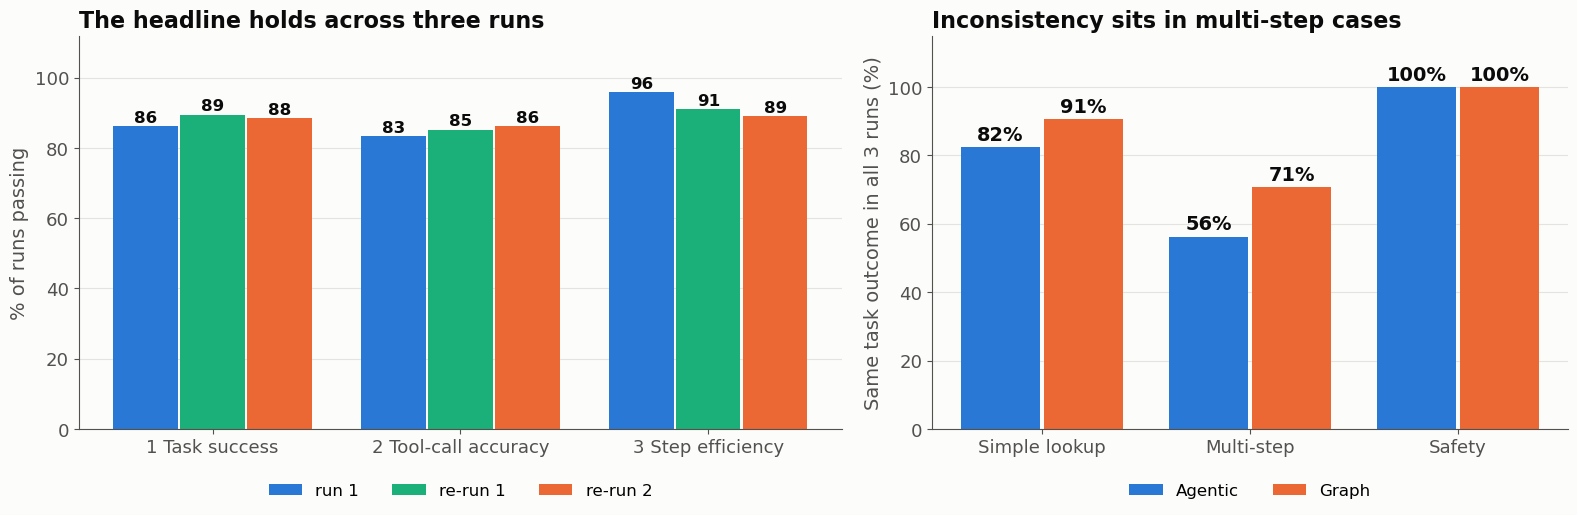

In [36]:
# ──────────────────────────────────────────────────────────────────────────────
# PURPOSE: metric 7, consistency, in detail (A10b).
# - Table 1: headline metrics in each of the three runs.
# - Table 2: agreement between runs (pairwise = the plan's original_pass == second_pass; strict = all three agree).
# - Table 3: which run-1 findings replicate in both re-runs.
# - Chart: headline metrics per run; consistency by task type and control style.
# ──────────────────────────────────────────────────────────────────────────────
per_run = three.groupby("run", sort=False).agg(**{
    "1 Task success (%)": ("task_pass", pct), "2 Tool-call accuracy (%)": ("tool_call_pass", pct),
    "3 Step efficiency (%)": ("step_pass", pct), "4 Cost (median US$)": ("cost_usd", "median"),
    "5 Latency (median s)": ("elapsed_s", "median")})
display(per_run.style.format("{:.1f}").format("{:.5f}", subset=["4 Cost (median US$)"])
        .set_caption("<b>Headline metrics in each run</b> (312 runs each)"))

wide = three.pivot_table(index=["case_id", "setup"], columns="run", values=["task_pass", "tool_call_pass", "step_pass"], aggfunc="first")
agreement = pd.DataFrame({
    f"{a} = {b}": {m: pct(wide[(c, a)] == wide[(c, b)]) for m, c in
                   [("1 Task success", "task_pass"), ("2 Tool-call accuracy", "tool_call_pass"), ("3 Step efficiency", "step_pass")]}
    for a, b in [("run 1", "re-run 1"), ("run 1", "re-run 2"), ("re-run 1", "re-run 2")]})
agreement["All three agree"] = [pct(df.task_consistent), pct(df.tool_consistent), pct(df.step_consistent)]
display(agreement.style.format("{:.1f}").set_caption("<b>Agreement between runs</b> (% of the 312 case × variant pairs)"))

def findings(d):
    lookup = d[d.kind == "routine lookup"]; other = d[d.kind != "routine lookup"]
    best = d.groupby("setup").task_pass.mean()
    return {
        "Single agents reach the right ticket status more often (%)": f"{pct(d[d.agents == 'single'].status_ok):.0f} vs {pct(d[d.agents == 'multi'].status_ok):.0f}",
        "Plan-and-execute workers choose tools better (%)": f"{pct(d[d.worker_strategy == 'plan_execute'].tool_correctness_pass):.0f} vs {pct(d[d.worker_strategy == 'react'].tool_correctness_pass):.0f}",
        "Single agents are faster (median s)": f"{d[d.agents == 'single'].elapsed_s.median():.0f} vs {d[d.agents == 'multi'].elapsed_s.median():.0f}",
        "Agentic faster on non-routine cases (median s)": f"{other[other.control == 'agentic'].elapsed_s.median():.0f} vs {other[other.control == 'graph'].elapsed_s.median():.0f}",
        "Graph faster on routine lookups (median s, graph vs agentic)": f"{lookup[lookup.control == 'graph'].elapsed_s.median():.0f} vs {lookup[lookup.control == 'agentic'].elapsed_s.median():.0f}",
        "Simple lookups vs multi-step task success (%)": f"{pct(d[d.category == 'simple lookup'].task_pass):.0f} vs {pct(d[d.category == 'multi-step'].task_pass):.0f}",
        "Refund case EVAL-09 task success (%)": f"{pct(d[d.case_id == 'EVAL-09'].task_pass):.0f}",
        "s1-b task success (%)": f"{pct(d[d.setup == 's1-b'].task_pass):.0f}",
        "Best variant(s)": ", ".join(best[best == best.max()].index) + f" ({100 * best.max():.0f}%)",
    }
replication = pd.DataFrame({run: findings(three[three.run == run]) for run in ["run 1", "re-run 1", "re-run 2"]})
replication["Replicates?"] = ["yes", "yes (smaller gap)", "yes", "yes", "no: reverses", "yes (smaller gap)", "yes",
                              "no", "no: changes every run"]
display(replication.style.set_properties(**{"text-align": "left"}).set_caption("<b>Do the run-1 findings replicate?</b>"))

with plt.rc_context(BIG):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5.4), gridspec_kw={"width_ratios": [1.2, 1]})
    run_colors = ["#2a78d6", "#1baf7a", "#eb6834"]
    cols = ["1 Task success (%)", "2 Tool-call accuracy (%)", "3 Step efficiency (%)"]
    for j, (run, color) in enumerate(zip(per_run.index, run_colors)):
        bars = ax1.bar([i + (j - 1) * 0.27 for i in range(3)], per_run.loc[run, cols], width=0.26, color=color, label=run)
        bar_labels(ax1, bars, lambda v: f"{v:.0f}", 1.2, 12)
    ax1.set_xticks(range(3), [c.replace(" (%)", "") for c in cols]); ax1.set_ylim(0, 112); ax1.set_ylabel("% of runs passing")
    ax1.grid(axis="x", visible=False); ax1.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=3)
    ax1.set_title("The headline holds across three runs")
    cat_order = ["simple lookup", "multi-step", "safety & guardrail"]
    cons_by = df.groupby(["category", "control"]).task_consistent.mean().mul(100).unstack().reindex(cat_order)
    for off, ctrl in [(-0.2, "agentic"), (0.2, "graph")]:
        bars = ax2.bar([i + off for i in range(3)], cons_by[ctrl], width=0.38, color=CONTROL_PAL[ctrl], label=NICE[ctrl])
        bar_labels(ax2, bars, lambda v: f"{v:.0f}%", 2)
    ax2.set_xticks(range(3), ["Simple lookup", "Multi-step", "Safety"]); ax2.set_ylim(0, 115)
    ax2.set_ylabel("Same task outcome in all 3 runs (%)"); ax2.grid(axis="x", visible=False)
    ax2.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2)
    ax2.set_title("Inconsistency sits in multi-step cases")
    fig.tight_layout(); plt.show()


## A11 · Conclusion

| Hypothesis | Verdict | Deciding metrics | Explanation |
|---|---|---|---|
| **H1** agentic is more flexible, may be faster | 🟨 Partly supported | 5 Latency, LLM calls | Faster only where the task branches; the graph restarts gather → propose after each write-gate refusal |
| **H2** deterministic flow succeeds more often and more consistently | 🟨 Partly supported | 1 Task success, 2, 3, 6, 7 Consistency | Not more successful (all variants share the same safeguards); but graph repeats its task outcome more often across runs, while agentic is steadier on tool choice |
| **H3** single as accurate and cheaper; team wins on complex tasks | 🟨 Half supported | 1 Task success, 4 Cost, 5 Latency | Cheaper and as accurate ✓; teams lose information at hand-offs and fail more multi-step tasks ✗ |
| **H4** planning improves tool use and trajectories, at a cost | 🟨 Partly supported | 2 Tool-call accuracy, 5 Latency | Better tool selection and slower ✓; trajectories not significant; fewer LLM calls, more tool calls |

**Additional findings:** RAG and skills are equivalent on accuracy; in teams, only the specialists' strategy matters; most wrong answers are a wording problem in the shared reply writer (A8). Across three full runs the pooled results replicate, but individual variant rankings do not (A10b).

**Future work:** (1) a **hybrid**: a single plan-and-execute agent inside a graph that hard-codes escalation; (2) a **constrained reply writer**; (3) **more scenarios and more repeats per variant**, so that individual variants can be ranked, plus a second judge.

> **🎤 Say:** "Architecture decides *where* the agent fails rather than *how often*. Our recommendation: a single planning agent, with escalation enforced in code as in the graph."

---
# Part B · Supporting analysis

The detailed evidence behind Part A: all eight DeepEval metrics, the paired hypothesis tests, task categories and failure analysis; §13 shows the final result tables from `output/tables/`. Sections are numbered as before (§1 is the data preparation above).

## Study design and hypotheses

This notebook compares the 24 setup variants (S1–S8 × variants a–d) on the DeepEval scores in
`results/deepeval/data/raw/baseline/run1/scored_dedup.csv`, and tests the two study hypotheses from `EXPERIMENT.md`:

| | Hypothesis | Setups | Measures |
|---|---|---|---|
| **H1** | Letting agents make their own tool calls is more flexible and might be faster | S1–S4 (agentic) | Wall-clock latency, LLM calls, tokens; metric pass rates on the non-routine cases; tool-path diversity |
| **H2** | A deterministic, code-controlled flow succeeds more often | S5–S8 (graph) | Pass rate and mean score on each of the eight DeepEval metrics |
| **H3** | A single agent is at least as accurate as a multi-agent team on routine tasks, and faster and cheaper; a multi-agent team succeeds more often on complex, multi-step tasks | S1, S2, S5, S6 (single) vs S3, S4, S7, S8 (multi) | Paired pass rates overall, on routine and multi-step cases; latency, LLM calls, tokens |
| **H4** | Planning before acting (plan_execute) gives more accurate tool use and better trajectories than react, but costs more latency and LLM calls | variants a–d | Paired tool correctness and trajectory pass rates; latency, LLM calls, tokens |

**Design.** Each agentic setup has a graph counterpart that differs *only* in control style:
S1↔S5, S2↔S6, S3↔S7, S4↔S8, with the same variant letter. Each of the 13 cases was run once per variant,
which gives **12 matched variant pairs × 13 cases = 156 paired observations**. The control-style tests below use
these pairs (Wilcoxon signed-rank for scores and latency, exact McNemar for pass/fail). That removes case difficulty,
agent count, policy mode and strategy from the comparison. H3 and H4 use their own matched pairs, described in §6 and §7.

**Thinking modes** (the variants): `react` picks one step at a time; `plan_execute` plans every step up front and
replans only on an error. Multi-agent variants c and d mix the two strategies between supervisor and specialists.

## 3. Every architecture and variant on every metric

### 3a. Pass rate per setup variant

Rows are the 24 variants in setup order; columns are the metrics. The colour scale starts at 50%, since every
pass rate falls between 69% and 100%. The plan metrics are blank for variant a, which
has no plan. Every cell is out of 13 runs, so one run is worth about 8 points.

In [37]:
# ──────────────────────────────────────────────────────────────────────────────
# PURPOSE (§3a): a table of every variant (rows) x every metric (columns), as % of runs passing.
# Darker blue = higher pass rate.
# ──────────────────────────────────────────────────────────────────────────────
order = sorted(df.setup.unique())
meta = df.drop_duplicates("setup").set_index("setup")[["control", "agents", "policy", "strategy"]].loc[order]

pass_by_setup = df.groupby("setup")[PASS_COLS].mean().loc[order].rename(columns=label)
score_by_setup = df.groupby("setup")[SCORE_COLS].mean().loc[order].rename(columns=label)

(meta.join(pass_by_setup).style
     .format("{:.0%}", subset=list(pass_by_setup.columns), na_rep="–")
     .background_gradient(cmap=SEQ, vmin=0, vmax=1, subset=list(pass_by_setup.columns)))

,control,agents,policy,strategy,answer,tool,argument,task completion,step efficiency,trajectory,plan adherence,plan quality,ticket status
setup,,,,,,,,,,,,,
s1-a,agentic,single,RAG,react,77%,92%,92%,85%,85%,77%,–,–,92%
s1-b,agentic,single,RAG,plan_execute,100%,100%,92%,92%,92%,85%,100%,100%,100%
s2-a,agentic,single,SKILL,react,92%,92%,92%,92%,100%,85%,–,–,100%
s2-b,agentic,single,SKILL,plan_execute,92%,100%,85%,100%,100%,100%,100%,100%,92%
s3-a,agentic,multi,RAG,react / react,77%,100%,85%,77%,100%,92%,–,–,85%
s3-b,agentic,multi,RAG,plan / plan,85%,92%,85%,77%,92%,92%,100%,100%,85%
s3-c,agentic,multi,RAG,react / plan,92%,100%,92%,69%,100%,92%,92%,100%,92%
s3-d,agentic,multi,RAG,plan / react,92%,100%,85%,85%,100%,85%,92%,100%,100%
s4-a,agentic,multi,SKILL,react / react,85%,92%,85%,85%,92%,92%,–,–,92%


In [38]:
# ──────────────────────────────────────────────────────────────────────────────
# PURPOSE: the same table drawn as a heatmap. Agentic variants are left of the line, graph variants right.
# The chart is also saved to results/deepeval/output/figures/ for use in the report.
# ──────────────────────────────────────────────────────────────────────────────
def setup_heatmap(data, title, fname, fmt, vmin):
    fig, ax = plt.subplots(figsize=(14, 0.48 * data.shape[1] + 1.4))
    sns.heatmap(data.T, cmap=SEQ, vmin=vmin, vmax=1, annot=True, fmt=fmt, annot_kws={"size": 7.5},
                linewidths=2, linecolor="#fcfcfb", cbar_kws={"shrink": 0.8}, ax=ax)
    ax.axvline(12, color=INK, lw=1.5)
    ax.text(6, -0.3, "agentic (S1–S4)", ha="center", color=INK2)
    ax.text(18, -0.3, "graph (S5–S8)", ha="center", color=INK2)
    ax.set(xlabel="", ylabel="")
    ax.grid(False)
    ax.set_title(title, pad=18)
    fig.savefig(FIG_DIR / fname)

setup_heatmap(pass_by_setup, "Pass rate per setup variant (manual labels; blank = not scored)", "pass_rate_heatmap.png", ".0%", vmin=0.5)

### 3b. Mean judge score per setup variant

In [39]:
# ──────────────────────────────────────────────────────────────────────────────
# PURPOSE (§3b): like §3a, but using the judge's average 0-1 score instead of the pass rate.
# ──────────────────────────────────────────────────────────────────────────────
display(meta.join(score_by_setup).style.format("{:.2f}", subset=list(score_by_setup.columns), na_rep="–")
            .background_gradient(cmap=SEQ, vmin=0, vmax=1, subset=list(score_by_setup.columns)))
setup_heatmap(score_by_setup, "Mean judge score per setup variant (blank = not scored)", "score_heatmap.png", ".2f", vmin=0.5)

,control,agents,policy,strategy,answer,tool,argument,task completion,step efficiency,trajectory,plan adherence,plan quality
setup,,,,,,,,,,,,
s1-a,agentic,single,RAG,react,0.75,0.87,0.88,0.83,0.87,0.79,–,–
s1-b,agentic,single,RAG,plan_execute,0.86,0.97,0.86,0.93,0.89,0.83,0.98,0.95
s2-a,agentic,single,SKILL,react,0.79,0.89,0.86,0.92,0.99,0.88,–,–
s2-b,agentic,single,SKILL,plan_execute,0.80,0.95,0.79,0.98,0.98,0.92,0.99,0.99
s3-a,agentic,multi,RAG,react / react,0.72,0.89,0.87,0.76,0.88,0.90,–,–
s3-b,agentic,multi,RAG,plan / plan,0.75,0.90,0.83,0.80,0.87,0.92,0.88,0.94
s3-c,agentic,multi,RAG,react / plan,0.83,0.92,0.90,0.75,0.90,0.92,0.90,0.96
s3-d,agentic,multi,RAG,plan / react,0.73,0.92,0.84,0.82,0.90,0.82,0.94,0.97
s4-a,agentic,multi,SKILL,react / react,0.75,0.92,0.81,0.86,0.88,0.82,–,–


### 3c. Per architecture (S1–S8, variants pooled) and per variant

In [40]:
# ──────────────────────────────────────────────────────────────────────────────
# PURPOSE (§3c): pass rates per architecture (S1-S8, variants pooled), then per thinking mode
# within each architecture.
# ──────────────────────────────────────────────────────────────────────────────
arch_meta = df.drop_duplicates("family").set_index("family")[["control", "agents", "policy"]].sort_index()
pass_by_arch = df.groupby("family")[PASS_COLS].mean().rename(columns=label)
display(arch_meta.join(pass_by_arch).style.format("{:.0%}", subset=list(pass_by_arch.columns), na_rep="–")
        .background_gradient(cmap=SEQ, vmin=0, vmax=1, subset=list(pass_by_arch.columns)))

# Variants (thinking modes), within each agent count × control style
pass_by_variant = df.groupby(["agents", "control", "strategy"])[PASS_COLS].mean().rename(columns=label)
pass_by_variant.style.format("{:.0%}", na_rep="–").background_gradient(cmap=SEQ, vmin=0, vmax=1)

,control,agents,policy,answer,tool,argument,task completion,step efficiency,trajectory,plan adherence,plan quality,ticket status
family,,,,,,,,,,,,
S1,agentic,single,RAG,88%,96%,92%,88%,88%,81%,100%,100%,96%
S2,agentic,single,SKILL,92%,96%,88%,96%,100%,92%,100%,100%,96%
S3,agentic,multi,RAG,87%,98%,87%,77%,98%,90%,95%,100%,90%
S4,agentic,multi,SKILL,90%,96%,87%,88%,94%,88%,90%,97%,90%
S5,graph,single,RAG,85%,100%,85%,88%,96%,85%,85%,100%,100%
S6,graph,single,SKILL,88%,96%,88%,88%,92%,81%,92%,85%,96%
S7,graph,multi,RAG,87%,94%,87%,90%,98%,94%,85%,97%,94%
S8,graph,multi,SKILL,85%,94%,87%,85%,96%,94%,90%,92%,92%


In [41]:
# ──────────────────────────────────────────────────────────────────────────────
# PURPOSE: lists, for each metric, which variant scored best and which scored worst.
# ──────────────────────────────────────────────────────────────────────────────
# Best and worst variant on each metric (ties listed together)
rows = []
for c in pass_by_setup.columns:
    s = pass_by_setup[c].dropna()
    rows.append({"metric": c, "best": f"{s.max():.0%}: " + ", ".join(s[s == s.max()].index),
                 "worst": f"{s.min():.0%}: " + ", ".join(s[s == s.min()].index)})
pd.DataFrame(rows).style.hide(axis="index").set_properties(**{"text-align": "left"})

metric,best,worst
answer,"100%: s1-b, s4-d","77%: s1-a, s3-a, s8-b"
tool,"100%: s1-b, s2-b, s3-a, s3-c, s3-d, s4-b, s4-c, s5-a, s5-b, s6-b, s7-b, s7-c, s8-b, s8-c","85%: s7-d, s8-a"
argument,"92%: s1-a, s1-b, s2-a, s3-c, s4-c, s5-a, s6-b, s7-a, s8-d",77%: s5-b
task completion,"100%: s2-b, s7-a",69%: s3-c
step efficiency,"100%: s2-a, s2-b, s3-a, s3-c, s3-d, s4-d, s5-b, s7-a, s7-c, s7-d, s8-a, s8-b",85%: s1-a
trajectory,"100%: s2-b, s4-c, s7-c, s8-b, s8-c","77%: s1-a, s4-b, s6-b"
plan adherence,"100%: s1-b, s2-b, s3-b, s4-d",77%: s7-d
plan quality,"100%: s1-b, s2-b, s3-b, s3-c, s3-d, s4-c, s4-d, s5-b, s7-c, s7-d",85%: s6-b
ticket status,"100%: s1-b, s2-a, s3-d, s4-d, s5-a, s5-b, s6-a, s7-c, s8-b",77%: s4-b


## 4. H1: agentic control is more flexible and faster

### 4a. Speed and cost (paired)

Latency, LLM calls, tokens and tool calls aren't in the scored CSV; they come from the raw run logs (§1a). They are
the only way to test the "faster" half of H1.

Each agentic row is matched with its graph counterpart on the same case (e.g. `s3-c` × EVAL-05 ↔ `s7-c` × EVAL-05).
The tests are on the paired difference **agentic − graph**, so a negative value means agentic is faster or cheaper.

In [42]:
# ──────────────────────────────────────────────────────────────────────────────
# PURPOSE (§4, H1: is agentic faster?):
# - paired() lines up each agentic run with its graph twin on the same case.
# - The tables compare latency, LLM calls, tokens and tool calls (agentic minus graph).
#   A negative difference means agentic is faster or cheaper.
# - Wilcoxon p = the paired significance test (p < 0.05 means the difference is unlikely to be chance).
# - The test is repeated separately for routine and non-routine cases, then per case.
# ──────────────────────────────────────────────────────────────────────────────
def paired(data, col):
    w = data.pivot_table(index=["pair_id", "case_id"], columns="control", values=col, aggfunc="first").dropna()
    return w["agentic"], w["graph"]

def bootstrap_ci(x, fn=np.median, n=5000, seed=0):
    rng = np.random.default_rng(seed)
    x = np.asarray(x)
    boots = fn(rng.choice(x, (n, len(x)), replace=True), axis=1)
    return np.percentile(boots, [2.5, 97.5])

rows = []
for col, name in [("elapsed_s", "latency (s)"), ("llm_calls", "LLM calls"),
                  ("total_tokens", "tokens"), ("tool_calls", "tool calls")]:
    a, g = paired(df, col)
    d = a - g
    lo, hi = bootstrap_ci(d)
    rows.append({"measure": name, "pairs": len(d), "agentic median": a.median(), "graph median": g.median(),
                 "agentic mean": a.mean(), "graph mean": g.mean(),
                 "median diff (A−G)": d.median(), "95% CI of median diff": f"[{lo:.1f}, {hi:.1f}]",
                 "mean diff (A−G)": d.mean(), "agentic lower in %": 100 * (d < 0).mean(),
                 "Wilcoxon p": stats.wilcoxon(a, g, zero_method="zsplit").pvalue})
speed = pd.DataFrame(rows)
display(speed)

# The same paired latency test, split into routine lookups and non-routine cases
rows = []
for kind, g in df.groupby("kind"):
    a, gg = paired(g, "elapsed_s")
    rows.append({"cases": kind, "pairs": len(a), "agentic median s": a.median(), "graph median s": gg.median(),
                 "agentic mean s": a.mean(), "graph mean s": gg.mean(),
                 "agentic faster in %": 100 * (a < gg).mean(),
                 "Wilcoxon p": stats.wilcoxon(a, gg, zero_method="zsplit").pvalue})
speed_kind = pd.DataFrame(rows)
display(speed_kind.style.format(precision=1).format({"Wilcoxon p": "{:.2g}", "agentic faster in %": "{:.0f}"}))

# Per-case median latency: where the graph's fixed stages cost time
per_case_lat = df.pivot_table(index="case_id", columns="control", values="elapsed_s", aggfunc="median")
per_case_lat["graph / agentic"] = per_case_lat["graph"] / per_case_lat["agentic"]
per_case_lat.join(cases["focus"]).round(2)

,measure,pairs,agentic median,graph median,agentic mean,graph mean,median diff (A−G),95% CI of median diff,mean diff (A−G),agentic lower in %,Wilcoxon p
0,latency (s),156,35.114,31.649,39.490,52.066,0.207,"[-1.0, 1.5]",-12.576,49.359,3.493e-01
1,LLM calls,156,8.000,8.000,8.705,10.128,0.000,"[-1.0, 0.0]",-1.423,49.359,1.369e-07
2,tokens,156,12174.000,10544.500,17641.192,20499.083,1047.000,"[475.0, 1517.0]",-2857.891,33.333,1.257e-01
3,tool calls,156,2.000,2.000,2.878,3.385,0.000,"[0.0, 0.0]",-0.506,28.205,1.237e-02


,cases,pairs,agentic median s,graph median s,agentic mean s,graph mean s,agentic faster in %,Wilcoxon p
0,non-routine,60,39.459800,58.618650,48.103108,86.058158,73,6.2e-06
1,routine lookup,96,33.645650,29.689950,34.106246,30.820649,34,0.00042


,agentic,graph,graph / agentic,focus
case_id,,,,
EVAL-01,31.85,28.70,0.90,Order contents lookup: items in the power-bank...
EVAL-02,34.09,28.10,0.82,Order status lookup: processing order
EVAL-03,36.24,30.93,0.85,Payment lookup: captured payment status
EVAL-04,33.95,32.39,0.95,Return lookup: pending fault claim status
EVAL-05,28.68,29.82,1.04,Tracking lookup: delivered shipment status
EVAL-06,40.04,30.65,0.77,Policy lookup: ordinary return request window
EVAL-07,30.48,29.99,0.98,Customer order lookup: identify processing order
EVAL-08,31.83,26.28,0.83,Shipment lookup: carrier and tracking number
EVAL-09,36.39,100.02,2.75,"Refund processing: approved bottle return, SGD 20"


In [43]:
# ──────────────────────────────────────────────────────────────────────────────
# PURPOSE: two latency charts.
# - Left: distribution of seconds per run for each setup (log scale).
# - Right: each dot is one matched pair (agentic minus graph). Dots left of 0 = agentic was faster.
# ──────────────────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [1.3, 1]})

sns.boxplot(data=df, x="family", y="elapsed_s", hue="control", palette=CONTROL_PAL, order=[f"S{i}" for i in range(1, 9)],
            width=0.6, linewidth=1, fliersize=3, ax=axes[0], legend=False)
axes[0].set_yscale("log")
axes[0].yaxis.set_major_formatter(plt.matplotlib.ticker.ScalarFormatter())
axes[0].set_yticks([1, 3, 10, 30, 100, 300])
axes[0].set(xlabel="setup", ylabel="wall-clock seconds per case (log)", title="Latency by setup")
for x, t in [(1.5, "agentic"), (5.5, "graph")]:
    axes[0].text(x, 500, t, ha="center", va="top", color=CONTROL_PAL[t], fontweight="bold")

a, g = paired(df, "elapsed_s")
diff = (a - g).reset_index(name="diff")
diff["arch"] = diff["pair_id"].str.split("-").str[:2].str.join(" · ")
sns.stripplot(data=diff, y="arch", x="diff", color=C_AGENTIC, alpha=0.6, size=5, jitter=0.25, ax=axes[1])
sns.pointplot(data=diff, y="arch", x="diff", estimator=np.median, color=INK, markers="|", markersize=14,
              linestyle="none", errorbar=None, ax=axes[1])
axes[1].axvline(0, color=INK2, lw=1)
axes[1].set(xlabel="agentic − graph seconds (same case, same variant)", ylabel="",
            title="Paired latency difference (bar = median)")
fig.tight_layout(); fig.savefig(FIG_DIR / "h1_latency.png");

#### Latency heatmap

Wall-clock seconds for every case (rows) and setup variant (columns); the bottom row is each variant's median.
Darker means slower. The colour scale is logarithmic and starts at 10s, because a few write-case runs take minutes
while most cases finish in 20–60 seconds (the ~2s injection runs show at the lightest shade).

In [44]:
# ──────────────────────────────────────────────────────────────────────────────
# PURPOSE: latency heatmap, seconds for every case (rows) x variant (columns).
# Darker = slower. The dark cells are the graph systems on the write cases.
# ──────────────────────────────────────────────────────────────────────────────
from matplotlib.colors import LogNorm

lat_grid = df.pivot_table(index="case_id", columns="setup", values="elapsed_s", aggfunc="first")[order]
lat_grid.index = [f"{c}  {cases.loc[c, 'focus'][:34]}" for c in lat_grid.index]
lat_grid.loc["median (all cases)"] = lat_grid.median()

fig, ax = plt.subplots(figsize=(15, 6.4))
# One hue, light -> dark; the scale starts at 10s so the 20-60s bulk spreads out (EVAL-11's ~2s runs sit at the light end)
LAT_CMAP = sns.blend_palette(["#f0efec", "#2a78d6", "#0d2f5c"], as_cmap=True)
sns.heatmap(lat_grid, cmap=LAT_CMAP, norm=LogNorm(vmin=10, vmax=350, clip=True), annot=True, fmt=".0f",
            annot_kws={"size": 7}, linewidths=2, linecolor="#fcfcfb",
            cbar_kws={"label": "seconds (log scale)", "shrink": 0.8, "ticks": [10, 20, 30, 50, 100, 200, 300]}, ax=ax)
ax.collections[0].colorbar.ax.set_yticklabels(["≤10", "20", "30", "50", "100", "200", "300"])
ax.axvline(12, color=INK, lw=1.5)
ax.axhline(8, color=INK2, lw=1, ls="--")
ax.axhline(13, color=INK, lw=1.5)
ax.text(6, -0.3, "agentic (S1–S4)", ha="center", color=INK2)
ax.text(18, -0.3, "graph (S5–S8)", ha="center", color=INK2)
ax.set(xlabel="", ylabel="")
ax.grid(False)
ax.set_title("Wall-clock latency per case and setup variant (seconds; dashed line splits routine / non-routine)", pad=18)
fig.savefig(FIG_DIR / "latency_heatmap.png");

In [45]:
# ──────────────────────────────────────────────────────────────────────────────
# PURPOSE: median latency for each architecture x thinking mode, agentic vs graph.
# ──────────────────────────────────────────────────────────────────────────────
# Latency by architecture and thinking mode
lat = df.pivot_table(index=["agents", "strategy"], columns="control", values="elapsed_s", aggfunc="median")
lat["agentic − graph"] = lat["agentic"] - lat["graph"]
lat.round(1)

control               agentic  graph  agentic − graph
agents strategy                                      
multi  plan / plan       41.0   42.2             -1.2
       plan / react      37.4   31.1              6.4
       react / plan      37.2   33.5              3.7
       react / react     35.5   28.7              6.7
single plan_execute      30.3   30.9             -0.5
       react             24.9   27.6             -2.6

### 4b. Flexibility

Flexibility can't be measured directly, so we use two proxies:

1. **Metric pass rates on non-routine cases.** Does agentic control do better where a fixed flow might not fit:
   the refund write (EVAL-09), safety escalation (EVAL-10), injection (EVAL-11), asking for a missing order ID
   (EVAL-12) and replayed cancellation (EVAL-13)?
2. **Tool-path diversity.** How many distinct tool sequences a control style produces for the same case. More paths
   means more adaptive behaviour, but also less predictable behaviour.

In [46]:
# ──────────────────────────────────────────────────────────────────────────────
# PURPOSE (§4b, flexibility): pass rates for routine vs non-routine cases, agentic vs graph,
# plus the difference between them (agentic minus graph).
# ──────────────────────────────────────────────────────────────────────────────
kind_pass = df.groupby(["kind", "control"])[PASS_COLS].mean().rename(columns=label)
kind_pass.loc[("non-routine", "agentic − graph"), :] = (kind_pass.loc[("non-routine", "agentic")]
                                                        - kind_pass.loc[("non-routine", "graph")])
kind_pass.loc[("routine lookup", "agentic − graph"), :] = (kind_pass.loc[("routine lookup", "agentic")]
                                                           - kind_pass.loc[("routine lookup", "graph")])
kind_pass = kind_pass.sort_index()
kind_pass.style.format("{:+.0%}", subset=pd.IndexSlice[pd.IndexSlice[:, "agentic − graph"], :], na_rep="–") \
         .format("{:.0%}", subset=pd.IndexSlice[pd.IndexSlice[:, ["agentic", "graph"]], :], na_rep="–")

In [47]:
# ──────────────────────────────────────────────────────────────────────────────
# PURPOSE: heatmap of agentic minus graph pass rate for every case and metric.
# Blue = agentic better, orange = graph better, pale = no difference.
# ──────────────────────────────────────────────────────────────────────────────
# Agentic − graph pass rate, per case and metric. Blue = agentic passes more often, orange = graph does.
case_diff = (df.groupby(["case_id", "control"])[PASS_COLS].mean().rename(columns=label)
               .unstack("control").swaplevel(axis=1))
case_diff = case_diff["agentic"] - case_diff["graph"]
case_diff.index = [f"{c}  {cases.loc[c, 'focus'][:36]}" for c in case_diff.index]

DIVERGE = sns.blend_palette([C_GRAPH, "#f0efec", C_AGENTIC], as_cmap=True)
fig, ax = plt.subplots(figsize=(11, 5.6))
sns.heatmap(case_diff, cmap=DIVERGE, vmin=-1, vmax=1, center=0, annot=True, fmt="+.0%", annot_kws={"size": 7.5},
            linewidths=2, linecolor="#fcfcfb", cbar_kws={"label": "agentic − graph pass rate"}, ax=ax)
ax.axhline(8, color=INK, lw=1.5)
ax.set(xlabel="", ylabel="")
ax.grid(False)
ax.set_title("Agentic − graph pass rate per case (blue = agentic higher, orange = graph higher)")
ax.text(9.15, 4, "routine", rotation=90, va="center", color=INK2)
ax.text(9.15, 10.5, "non-routine", rotation=90, va="center", color=INK2)
fig.savefig(FIG_DIR / "case_metric_diff.png");

In [48]:
# ──────────────────────────────────────────────────────────────────────────────
# PURPOSE: how many different tool sequences each control style used per case.
# More paths = more adaptive behaviour, but less predictable.
# ──────────────────────────────────────────────────────────────────────────────
div = (df.groupby(["case_id", "control"]).agg(distinct_paths=("tool_path", "nunique"), tool_calls_sd=("tool_calls", "std"))
         .unstack("control"))
display(div.round(2))
paths = df.groupby(["case_id", "control"]).tool_path.nunique().groupby("control").mean()
print("Mean distinct tool paths per case (out of 12 runs):", paths.round(2).to_dict())

distinct_paths       tool_calls_sd      
control        agentic graph       agentic graph
case_id                                         
EVAL-01              2     2          0.29  0.39
EVAL-02              3     3          0.79  0.98
EVAL-03              3     2          0.83  0.00
EVAL-04              2     4          0.51  1.16
EVAL-05              3     4          0.87  0.75
EVAL-06              3     2          0.67  0.52
EVAL-07              2     1          0.29  0.00
EVAL-08              4     2          0.49  0.29
EVAL-09              9     9          1.31  2.50
EVAL-10             12    11          1.19  2.26
EVAL-11              1     1          0.00  0.00
EVAL-12              9     5          1.31  1.44
EVAL-13             12    12          6.69  4.34

Mean distinct tool paths per case (out of 12 runs): {'agentic': 5.0, 'graph': 4.46}


## 5. H2: deterministic flow succeeds more often

Each metric is tested on the matched pairs:

- **Pass rate:** exact McNemar test. It uses only the *discordant* pairs, where one side passes and the other fails.
- **Mean score:** Wilcoxon signed-rank test on the paired score differences.

The plan metrics have fewer pairs, because both sides of a pair must have a plan (variants b, c and d).

In [49]:
# ──────────────────────────────────────────────────────────────────────────────
# PURPOSE (§5, H2: does graph control succeed more often?):
# - For every metric, compares agentic vs graph on matched pairs.
# - McNemar test: looks only at pairs where one side passed and the other failed.
# - "only agentic passes" / "only graph passes" count those pairs. p < 0.05 = significant.
# ──────────────────────────────────────────────────────────────────────────────
def mcnemar_exact(a, g):
    a, g = a.astype(bool), g.astype(bool)
    b, c = int((a & ~g).sum()), int((~a & g).sum())        # agentic-only passes, graph-only passes
    p = stats.binomtest(b, b + c, 0.5).pvalue if b + c else 1.0
    return b, c, p

rows = []
for m in METRICS + ["status_ok"]:
    pc = "status_ok" if m == "status_ok" else f"{m}_pass"
    a, g = paired(df, pc)
    b, c, p = mcnemar_exact(a, g)
    row = {"metric": SHORT[m], "pairs": len(a), "agentic pass": a.mean(), "graph pass": g.mean(),
           "only agentic passes": b, "only graph passes": c, "McNemar p": p}
    if m != "status_ok":
        sa, sg = paired(df, f"{m}_score")
        row |= {"agentic score": sa.mean(), "graph score": sg.mean(),
                "Wilcoxon p (score)": stats.wilcoxon(sa, sg, zero_method="zsplit").pvalue}
    rows.append(row)
h2 = pd.DataFrame(rows)
h2.style.format({"agentic pass": "{:.1%}", "graph pass": "{:.1%}", "McNemar p": "{:.2g}",
                 "agentic score": "{:.3f}", "graph score": "{:.3f}", "Wilcoxon p (score)": "{:.2g}"},
                na_rep="–").hide(axis="index")

metric,pairs,agentic pass,graph pass,only agentic passes,only graph passes,McNemar p,agentic score,graph score,Wilcoxon p (score)
answer,156,89.1%,85.9%,15,10,0.42,0.777,0.760,0.39
tool,156,96.8%,95.5%,6,4,0.75,0.917,0.908,0.36
argument,156,87.8%,86.5%,7,5,0.77,0.840,0.811,0.5
task completion,156,85.9%,87.8%,13,16,0.71,0.863,0.870,0.53
step efficiency,156,95.5%,96.2%,6,7,1,0.903,0.919,0.036
trajectory,156,88.5%,90.4%,12,15,0.7,0.863,0.881,0.39
plan adherence,104,94.2%,87.5%,10,3,0.092,0.915,0.888,0.58
plan quality,104,99.0%,94.2%,5,0,0.062,0.958,0.932,0.94
ticket status,156,92.3%,94.9%,8,12,0.5,–,–,–


In [50]:
# ──────────────────────────────────────────────────────────────────────────────
# PURPOSE: a dot chart of the H2 table. Blue dot = agentic, orange square = graph, one row per metric.
# ──────────────────────────────────────────────────────────────────────────────
# Pass rate by control style, one row per metric (paired subset, so plan metrics use variants b–d only)
fig, ax = plt.subplots(figsize=(8, 4.4))
ys = np.arange(len(h2))[::-1]
for y, (_, r) in zip(ys, h2.iterrows()):
    ax.plot([r["agentic pass"], r["graph pass"]], [y, y], color=GRID, lw=3, zorder=1)
ax.scatter(h2["agentic pass"], ys, s=70, color=C_AGENTIC, label="agentic (S1–S4)", zorder=3,
           edgecolor="#fcfcfb", linewidth=2)
ax.scatter(h2["graph pass"], ys, s=70, color=C_GRAPH, marker="s", label="graph (S5–S8)", zorder=3,
           edgecolor="#fcfcfb", linewidth=2)
ax.set_yticks(ys, h2["metric"])
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.set(xlim=(0.5, 1.02), xlabel="pass rate (matched pairs)", title="Pass rate per metric: agentic vs graph")
ax.grid(axis="y", visible=False)
ax.legend(loc="lower left")
fig.savefig(FIG_DIR / "h2_pass_rates.png");

## 6. H3: single agent vs multi-agent team

**H3.** *A single agent is at least as accurate as a multi-agent team on routine tasks, and is faster and cheaper.
A multi-agent team (supervisor plus specialists) succeeds more often on complex, multi-step tasks.*

**Matched pairs.** S1↔S3, S2↔S4, S5↔S7 and S6↔S8: same control style and policy, one agent vs a team. Only variant a
(react, and react / react for the team) and variant b (plan_execute, and plan / plan) have a single-agent version, so
variants c and d are left out. That gives 4 pairs × 2 variants × 13 cases = **104 paired runs**. Tests are the same as
in §5: exact McNemar for pass rates, Wilcoxon signed-rank for scores and cost.

The prediction has three parts, each tested separately:

1. *Routine tasks:* single is not significantly worse than multi (the 8 routine lookups, EVAL-01 to EVAL-08).
2. *Cost:* single is faster and uses fewer LLM calls and tokens.
3. *Complex tasks:* multi passes more often on the multi-step cases (EVAL-09, 10, 12, 13; the `complexity` tag in §9).

In [51]:
# ──────────────────────────────────────────────────────────────────────────────
# PURPOSE (§6, H3: single agent vs team):
# - Defines reusable helpers: compare_pairs() for pass rates and compare_cost() for time and tokens.
# - Pairs S1<->S3, S2<->S4, S5<->S7, S6<->S8 (same everything except the number of agents), variants a and b only.
# - Shows four tables: all cases, cost, routine lookups only, and multi-step only.
# ──────────────────────────────────────────────────────────────────────────────
def safe_wilcoxon(x, y):
    d = np.asarray(x) - np.asarray(y)
    return stats.wilcoxon(x, y, zero_method="zsplit").pvalue if len(d) and np.any(d != 0) else 1.0

def wide(data, index, side, col):
    # One row per matched pair, one column per side of the comparison
    return data.pivot_table(index=index, columns=side, values=col, aggfunc="first").dropna()

def compare_pairs(data, index, side, left, right, metrics=METRICS):
    # Paired pass rates (McNemar) and mean scores (Wilcoxon) for every metric, `left` vs `right`
    rows = []
    for m in metrics + ["status_ok"]:
        pc = "status_ok" if m == "status_ok" else f"{m}_pass"
        w = wide(data, index, side, pc)
        if w.empty or left not in w or right not in w:
            continue
        b, c, p = mcnemar_exact(w[left], w[right])
        row = {"metric": SHORT[m], "pairs": len(w), f"{left} pass": w[left].mean(), f"{right} pass": w[right].mean(),
               f"only {left} passes": b, f"only {right} passes": c, "McNemar p": p}
        if m != "status_ok":
            sw = wide(data, index, side, f"{m}_score")
            row |= {f"{left} score": sw[left].mean(), f"{right} score": sw[right].mean(),
                    "Wilcoxon p (score)": safe_wilcoxon(sw[left], sw[right])}
        rows.append(row)
    return pd.DataFrame(rows)

def compare_cost(data, index, side, left, right):
    rows = []
    for col, name in [("elapsed_s", "latency (s)"), ("llm_calls", "LLM calls"),
                      ("total_tokens", "tokens"), ("tool_calls", "tool calls")]:
        w = wide(data, index, side, col)
        d = w[left] - w[right]
        rows.append({"measure": name, "pairs": len(w), f"{left} median": w[left].median(), f"{right} median": w[right].median(),
                     f"{left} mean": w[left].mean(), f"{right} mean": w[right].mean(),
                     "mean diff": d.mean(), f"{left} lower in %": 100 * (d < 0).mean(),
                     "Wilcoxon p": safe_wilcoxon(w[left], w[right])})
    return pd.DataFrame(rows)

def fmt_pairs(t):
    pct = [c for c in t.columns if c.endswith(" pass")]
    sc = [c for c in t.columns if c.endswith(" score")]
    return (t.style.format("{:.1%}", subset=pct).format("{:.3f}", subset=sc)
             .format("{:.2g}", subset=[c for c in t.columns if c.endswith(" p") or c.endswith("(score)")], na_rep="–")
             .hide(axis="index"))

def fmt_cost(t):
    return (t.style.format(precision=1).format("{:.0f}", subset=[c for c in t.columns if c.endswith("in %")])
             .format("{:.2g}", subset=["Wilcoxon p"]).hide(axis="index"))

H3_DATA = df[df["variant"].isin(["a", "b"])]
H3_IDX = ["control", "policy", "variant", "case_id"]

h3 = compare_pairs(H3_DATA, H3_IDX, "agents", "single", "multi")
h3_cost = compare_cost(H3_DATA, H3_IDX, "agents", "single", "multi")
h3_routine = compare_pairs(H3_DATA[H3_DATA["kind"] == "routine lookup"], H3_IDX, "agents", "single", "multi")
h3_complex = compare_pairs(H3_DATA[H3_DATA["complexity"] == "multi-step"], H3_IDX, "agents", "single", "multi")

display(fmt_pairs(h3).set_caption("<b>All cases</b>: single vs multi, matched pairs"))
display(fmt_cost(h3_cost).set_caption("<b>Cost</b>: single vs multi (negative mean diff = single is cheaper)"))
display(fmt_pairs(h3_routine).set_caption("<b>Routine lookups</b> (EVAL-01 to 08)"))
display(fmt_pairs(h3_complex).set_caption("<b>Multi-step cases</b> (EVAL-09, 10, 12, 13)"))

metric,pairs,single pass,multi pass,only single passes,only multi passes,McNemar p,single score,multi score,Wilcoxon p (score)
answer,104,88.5%,84.6%,12,8,0.5,0.785,0.757,0.35
tool,104,97.1%,95.2%,4,2,0.69,0.920,0.900,0.46
argument,104,88.5%,85.6%,5,2,0.45,0.822,0.830,0.99
task completion,104,90.4%,86.5%,8,4,0.39,0.901,0.850,0.48
step efficiency,104,94.2%,96.2%,4,6,0.75,0.918,0.903,0.4
trajectory,104,84.6%,90.4%,8,14,0.29,0.836,0.874,0.14
plan adherence,52,94.2%,90.4%,3,1,0.62,0.938,0.862,0.032
plan quality,52,96.2%,94.2%,2,1,1,0.942,0.915,0.3
ticket status,104,97.1%,89.4%,10,2,0.039,nan,nan,–


measure,pairs,single median,multi median,single mean,multi mean,mean diff,single lower in %,Wilcoxon p
latency (s),104,29.0,36.9,38.1,51.1,-13.0,76,4.9e-07
LLM calls,104,6.0,8.0,7.6,10.4,-2.8,82,8.1e-16
tokens,104,10421.5,12174.0,16266.6,20873.4,-4606.8,73,3e-06
tool calls,104,2.0,2.0,3.0,3.2,-0.2,20,0.55


metric,pairs,single pass,multi pass,only single passes,only multi passes,McNemar p,single score,multi score,Wilcoxon p (score)
answer,64,92.2%,93.8%,4,5,1,0.803,0.794,0.65
tool,64,100.0%,100.0%,0,0,1,1.000,1.000,1
argument,64,85.9%,87.5%,0,1,1,0.816,0.820,0.99
task completion,64,98.4%,96.9%,2,1,1,0.973,0.934,0.7
step efficiency,64,100.0%,98.4%,1,0,1,0.986,0.945,0.057
trajectory,64,81.2%,89.1%,5,10,0.3,0.816,0.864,0.18
plan adherence,32,100.0%,100.0%,0,0,1,0.994,0.972,0.72
plan quality,32,100.0%,100.0%,0,0,1,0.981,0.962,0.25
ticket status,64,100.0%,98.4%,1,0,1,nan,nan,–


metric,pairs,single pass,multi pass,only single passes,only multi passes,McNemar p,single score,multi score,Wilcoxon p (score)
answer,32,78.1%,62.5%,8,3,0.23,0.694,0.622,0.31
tool,32,90.6%,84.4%,4,2,0.69,0.739,0.673,0.22
argument,32,90.6%,78.1%,5,1,0.22,0.788,0.807,0.98
task completion,32,71.9%,62.5%,6,3,0.51,0.731,0.647,0.55
step efficiency,32,87.5%,90.6%,3,4,1,0.822,0.808,0.74
trajectory,32,87.5%,90.6%,3,4,1,0.859,0.878,0.55
plan adherence,16,87.5%,81.2%,1,0,1,0.869,0.713,0.011
plan quality,16,87.5%,81.2%,2,1,1,0.856,0.800,0.51
ticket status,32,90.6%,68.8%,9,2,0.065,nan,nan,–


In [52]:
# ──────────────────────────────────────────────────────────────────────────────
# PURPOSE: heatmap of single minus team pass rate for each group of tasks.
# Violet = single better, yellow = team better. The right column shows how much slower the team is.
# ──────────────────────────────────────────────────────────────────────────────
C_SINGLE, C_MULTI = "#6250d6", "#eda100"      # categorical slots 7 (violet) and 4 (yellow); blue/orange are taken by control style
DIVERGE_SM = sns.blend_palette([C_MULTI, "#f0efec", C_SINGLE], as_cmap=True)

def side_diff_by_group(data, side, left, right, dims, cols=None):
    # left − right pass rate for every group of every dimension, plus the right ÷ left latency ratio
    cols = cols or PASS_COLS
    rows, ratio = [], []
    for dim in dims:
        for grp, g in data.groupby(dim):
            r = g.groupby(side)[cols].mean().rename(columns=label)
            if not {left, right} <= set(r.index):
                continue
            rows.append((r.loc[left] - r.loc[right]).rename(f"{dim}: {grp}  (n={g['case_id'].nunique()})"))
            lat = g.groupby(side)["elapsed_s"].median()
            ratio.append(lat[right] / lat[left])
    return pd.DataFrame(rows), ratio

def diff_heatmap(diff, ratio, cmap, title, ratio_label, fname, dims):
    fig, (ax, ax2) = plt.subplots(1, 2, figsize=(13, 0.42 * len(diff) + 1.5), gridspec_kw={"width_ratios": [9, 1.1]})
    sns.heatmap(diff, cmap=cmap, vmin=-0.6, vmax=0.6, center=0, annot=True, fmt="+.0%", annot_kws={"size": 7},
                linewidths=2, linecolor="#fcfcfb", cbar=False, ax=ax)
    sns.heatmap(pd.DataFrame({ratio_label: ratio}, index=diff.index), cmap=SEQ, annot=True, fmt=".2f",
                annot_kws={"size": 7}, linewidths=2, linecolor="#fcfcfb", cbar=False, yticklabels=False, ax=ax2)
    names = diff.index.str.split(":").str[0]
    for b in np.flatnonzero(names[1:] != names[:-1]) + 1:
        ax.axhline(b, color=INK, lw=1.2); ax2.axhline(b, color=INK, lw=1.2)
    for a in (ax, ax2):
        a.set(xlabel="", ylabel=""); a.grid(False)
    ax.set_title(title)
    fig.tight_layout(); fig.savefig(FIG_DIR / fname)

H3_DIMS = ["kind", "complexity", "category", "turns", "path"]
h3_diff, h3_ratio = side_diff_by_group(H3_DATA, "agents", "single", "multi", H3_DIMS)
diff_heatmap(h3_diff, h3_ratio, DIVERGE_SM,
             "Single − multi pass rate per task group (violet = single higher, yellow = multi higher)",
             "multi ÷ single\nlatency", "h3_single_multi_by_group.png", H3_DIMS)

In [53]:
# ──────────────────────────────────────────────────────────────────────────────
# PURPOSE: repeats the single-vs-team comparison separately for agentic and graph control.
# ──────────────────────────────────────────────────────────────────────────────
# The same split per control style: does a team help more under agentic or graph control?
rows = []
for ctrl, g in H3_DATA.groupby("control"):
    for kind, gg in [("all cases", g), ("routine lookup", g[g.kind == "routine lookup"]), ("multi-step", g[g.complexity == "multi-step"])]:
        t = gg.groupby("agents")[PASS_COLS].mean().rename(columns=label)
        rows.append((t.loc["single"] - t.loc["multi"]).rename((ctrl, kind)))
h3_ctrl = pd.DataFrame(rows)
h3_ctrl.index.names = ["control", "cases"]
h3_ctrl.style.format("{:+.0%}", na_rep="–").background_gradient(cmap=DIVERGE_SM, vmin=-0.6, vmax=0.6, axis=None) \
       .set_caption("Single − multi pass rate (positive = single higher)")

## 7. H4: plan_execute vs react

**H4.** *Planning before acting (`plan_execute`) gives more accurate tool use and better trajectories than `react`,
but costs more latency and LLM calls.*

**Matched pairs.** Each pair is the same setup on the same case, with only the tool-calling agent's thinking mode
changed:

- *Single agents:* variant a (react) ↔ variant b (plan_execute), on S1, S2, S5, S6.
- *Multi-agent teams:* the specialists' mode changes while the supervisor's stays fixed: a (react / react) ↔
  c (react / plan), and d (plan / react) ↔ b (plan / plan), on S3, S4, S7, S8.

That gives 4 × 13 + 4 × 2 × 13 = **156 paired runs**. The plan metrics are left out, because react runs have no
plan to score.

The multi-agent variants also allow the reverse comparison: the **supervisor's** mode changes while the specialists'
stays fixed (a ↔ d, c ↔ b). Comparing the two shows which role's thinking mode matters more.

In [54]:
# ──────────────────────────────────────────────────────────────────────────────
# PURPOSE (§7, H4: plan-and-execute vs ReAct):
# Pairs runs that differ only in the tool-using agent's thinking mode, then compares pass rates and cost.
# Key result: planning picks tools better (p = 0.006) but is slower.
# ──────────────────────────────────────────────────────────────────────────────
H4_IDX = ["family", "supervisor", "case_id"]                 # supervisor held fixed ("none" for single agents)
h4 = compare_pairs(df, H4_IDX, "worker_strategy", "plan_execute", "react", metrics=CORE)
h4_cost = compare_cost(df, H4_IDX, "worker_strategy", "plan_execute", "react")
display(fmt_pairs(h4).set_caption("<b>Specialist / agent thinking mode</b>: plan_execute vs react, all setups"))
display(fmt_cost(h4_cost).set_caption("<b>Cost</b>: plan_execute vs react (positive mean diff = planning costs more)"))

for agents, g in df.groupby("agents", sort=False):
    display(fmt_pairs(compare_pairs(g, H4_IDX, "worker_strategy", "plan_execute", "react", metrics=CORE))
            .set_caption(f"<b>{agents} agent(s)</b> only"))

metric,pairs,plan_execute pass,react pass,only plan_execute passes,only react passes,McNemar p,plan_execute score,react score,Wilcoxon p (score)
answer,156,87.8%,87.2%,12,11,1,0.767,0.770,0.82
tool,156,99.4%,92.9%,11,1,0.0063,0.938,0.886,0.001
argument,156,86.5%,87.8%,3,5,0.73,0.810,0.841,0.43
task completion,156,87.2%,86.5%,10,9,1,0.872,0.860,0.86
step efficiency,156,95.5%,96.2%,3,4,1,0.904,0.918,0.33
trajectory,156,91.7%,87.2%,16,9,0.23,0.885,0.860,0.65
ticket status,156,92.9%,94.2%,9,11,0.82,nan,nan,–


measure,pairs,plan_execute median,react median,plan_execute mean,react mean,mean diff,plan_execute lower in %,Wilcoxon p
latency (s),156,35.6,30.8,48.6,42.9,5.7,25,3.1e-10
LLM calls,156,8.0,8.0,8.6,10.2,-1.6,57,1.6e-13
tokens,156,11536.0,11629.0,18648.6,19491.7,-843.1,49,0.27
tool calls,156,2.0,1.0,3.5,2.8,0.7,9,4.4e-08


metric,pairs,plan_execute pass,react pass,only plan_execute passes,only react passes,McNemar p,plan_execute score,react score,Wilcoxon p (score)
answer,52,90.4%,86.5%,5,3,0.73,0.773,0.796,0.28
tool,52,100.0%,94.2%,3,0,0.25,0.948,0.891,0.045
argument,52,86.5%,90.4%,1,3,0.62,0.798,0.846,0.35
task completion,52,90.4%,90.4%,2,2,1,0.906,0.896,0.65
step efficiency,52,96.2%,92.3%,2,0,0.5,0.919,0.917,0.35
trajectory,52,86.5%,82.7%,6,4,0.75,0.846,0.825,0.99
ticket status,52,96.2%,98.1%,1,2,1,nan,nan,–


metric,pairs,plan_execute pass,react pass,only plan_execute passes,only react passes,McNemar p,plan_execute score,react score,Wilcoxon p (score)
answer,104,86.5%,87.5%,7,8,1,0.764,0.757,0.64
tool,104,99.0%,92.3%,8,1,0.039,0.933,0.884,0.0097
argument,104,86.5%,86.5%,2,2,1,0.817,0.838,0.76
task completion,104,85.6%,84.6%,8,7,1,0.856,0.842,0.94
step efficiency,104,95.2%,98.1%,1,4,0.38,0.897,0.918,0.52
trajectory,104,94.2%,89.4%,10,5,0.3,0.905,0.877,0.59
ticket status,104,91.3%,92.3%,8,9,1,nan,nan,–


In [55]:
# ──────────────────────────────────────────────────────────────────────────────
# PURPOSE: in multi-agent teams, compares changing the specialists' mode vs changing the supervisor's mode.
# Result: only the specialists' mode matters, because they are the ones calling the tools.
# ──────────────────────────────────────────────────────────────────────────────
# Which role's thinking mode matters more in a team? Same table, holding the other role fixed
multi_df = df[df.agents == "multi"]
role = pd.concat({
    "specialists plan (supervisor fixed)": compare_pairs(multi_df, H4_IDX, "worker_strategy", "plan_execute", "react", CORE)
        .set_index("metric")[["plan_execute pass", "react pass", "McNemar p"]].set_axis(["plan pass", "react pass", "McNemar p"], axis=1),
    "supervisor plans (specialists fixed)": compare_pairs(multi_df, ["family", "worker_strategy", "case_id"], "supervisor",
                                                          "plan_execute", "react", CORE)
        .set_index("metric")[["plan_execute pass", "react pass", "McNemar p"]].set_axis(["plan pass", "react pass", "McNemar p"], axis=1),
}, axis=1)
for r in role.columns.levels[0]:
    role[(r, "plan − react")] = role[(r, "plan pass")] - role[(r, "react pass")]
role = role.sort_index(axis=1, level=0, sort_remaining=False)
role.style.format("{:.0%}").format("{:+.0%}", subset=pd.IndexSlice[:, pd.IndexSlice[:, "plan − react"]]) \
    .format("{:.2g}", subset=pd.IndexSlice[:, pd.IndexSlice[:, "McNemar p"]])

In [56]:
# ──────────────────────────────────────────────────────────────────────────────
# PURPOSE: heatmap of plan minus ReAct pass rate per task group (green = planning better, red = ReAct better).
# ──────────────────────────────────────────────────────────────────────────────
C_PLAN, C_REACT = "#1baf7a", "#e34948"          # categorical slots 3 (aqua) and 8 (red)
DIVERGE_PR = sns.blend_palette([C_REACT, "#f0efec", C_PLAN], as_cmap=True)
H4_COLS = [f"{m}_pass" for m in CORE] + ["status_ok"]
H4_DIMS = ["kind", "complexity", "category", "agents", "control"]
h4_diff, h4_ratio = side_diff_by_group(df, "worker_strategy", "plan_execute", "react", H4_DIMS, H4_COLS)
diff_heatmap(h4_diff, [1 / r for r in h4_ratio], DIVERGE_PR,
             "plan_execute − react pass rate per group (aqua = plan higher, red = react higher)",
             "plan ÷ react\nlatency", "h4_plan_react_by_group.png", H4_DIMS)

## 8. Architectures and thinking modes

Besides control style, each setup varies agent count (single vs multi), policy source (RAG vs SKILL) and thinking
mode (react vs plan_execute). This section shows each factor's raw pass rates on every metric, pooled over all runs
(unlike the matched-pair tests in §6 and §7).

In [57]:
# ──────────────────────────────────────────────────────────────────────────────
# PURPOSE (§8): pass rate on every metric for each design choice on its own, pooled over all runs
# (not matched pairs).
# ──────────────────────────────────────────────────────────────────────────────
fac = []
for factor in ["control", "agents", "policy", "worker_strategy"]:
    t = df.groupby(factor)[PASS_COLS].mean().rename(columns=label)
    t.index = pd.MultiIndex.from_product([[factor], t.index])
    fac.append(t)
pd.concat(fac).style.format("{:.0%}", na_rep="–").background_gradient(cmap=SEQ, vmin=0.5, vmax=1, axis=None)

In [58]:
# ──────────────────────────────────────────────────────────────────────────────
# PURPOSE: pass rate per architecture, ReAct (blue) vs plan-and-execute (green), one panel per metric.
# ──────────────────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(2, 3, figsize=(13, 6.4), sharex=True)
arch_order = ["single · agentic", "single · graph", "multi · agentic", "multi · graph"]
for ax, m in zip(axes.flat, CORE):
    sns.pointplot(data=df, x="arch", y=f"{m}_pass", hue="worker_strategy", estimator=np.mean, errorbar=None,
                  order=arch_order, palette=[C_AGENTIC, "#1baf7a"], hue_order=["react", "plan_execute"],
                  markers=["o", "s"], markersize=7, linestyle="none", dodge=0.25, ax=ax, legend=(ax is axes.flat[0]))
    ax.set(xlabel="", ylabel="pass rate", title=SHORT[m])
    ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
    ax.tick_params(axis="x", rotation=20)
axes.flat[0].legend(title="thinking mode", loc="lower left")
fig.suptitle("Pass rate by architecture × thinking mode", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); fig.savefig(FIG_DIR / "arch_thinking_mode.png");

In [59]:
# ──────────────────────────────────────────────────────────────────────────────
# PURPOSE: pass rates for the four multi-agent combinations (supervisor mode / specialist mode).
# ──────────────────────────────────────────────────────────────────────────────
# Multi-agent: all four supervisor / specialist combinations
multi = df[df.agents == "multi"].groupby(["strategy", "control"])[PASS_COLS].mean().rename(columns=label)
multi.index.names = ["supervisor / specialists", "control"]
multi.style.format("{:.0%}", na_rep="–").background_gradient(cmap=SEQ, vmin=0.5, vmax=1, axis=None)

## 9. Results by task category

The 13 cases differ in more than routine vs non-routine, so each case is tagged on six dimensions. Every
dimension splits the same 13 cases a different way, which gives bigger groups than one fine-grained category would.

| Dimension | Groups |
|---|---|
| **category** | simple lookup (EVAL-01 to 08) · multi-step (EVAL-09, 10, 12, 13) · safety & guardrail (EVAL-11) |
| **complexity** | single-step (1 expected tool call) · multi-step (4–5 calls) · guard only (blocked before any tool) |
| **turns** | single-turn · multi-turn |
| **path** | conventional (a standard request with a clear happy path) · unconventional (safety, injection, ambiguity, replayed request) |
| **required outcome** | answer · write (refund / cancel) · hand off to a person |
| **information** | order ID given · ID missing (the agent must find or ask for it) · not needed |

The tags are in [`categories.csv`](../../deepeval/cases/categories.csv), in `deepeval/cases/`; edit a row there and rerun to
re-tag a case. Groups with only one or two cases rest on
12–24 runs per control style, so treat their differences as indicative.

In [60]:
# ──────────────────────────────────────────────────────────────────────────────
# PURPOSE (§9): shows how each of the 13 scenarios is tagged (category, complexity, turns, ...).
# ──────────────────────────────────────────────────────────────────────────────
# Loaded in §1b from deepeval/cases/categories.csv
TAXONOMY.join(cases["focus"])

,category,complexity,turns,path,required outcome,information,focus
case_id,,,,,,,
EVAL-01,simple lookup,single-step,single-turn,conventional,answer,order ID given,Order contents lookup: items in the power-bank...
EVAL-02,simple lookup,single-step,single-turn,conventional,answer,order ID given,Order status lookup: processing order
EVAL-03,simple lookup,single-step,single-turn,conventional,answer,order ID given,Payment lookup: captured payment status
EVAL-04,simple lookup,single-step,single-turn,conventional,answer,order ID given,Return lookup: pending fault claim status
EVAL-05,simple lookup,single-step,single-turn,conventional,answer,order ID given,Tracking lookup: delivered shipment status
EVAL-06,simple lookup,single-step,single-turn,conventional,answer,not needed,Policy lookup: ordinary return request window
EVAL-07,simple lookup,single-step,single-turn,conventional,answer,ID missing,Customer order lookup: identify processing order
EVAL-08,simple lookup,single-step,single-turn,conventional,answer,order ID given,Shipment lookup: carrier and tracking number
EVAL-09,multi-step,multi-step,single-turn,conventional,write,order ID given,"Refund processing: approved bottle return, SGD 20"


In [61]:
# ──────────────────────────────────────────────────────────────────────────────
# PURPOSE: for each tag (category, complexity, ...), pass rates and median seconds, agentic vs graph.
# by_group() builds the table and show() colours it.
# ──────────────────────────────────────────────────────────────────────────────
def by_group(dim, by="control"):
    g = df.groupby([dim, by])
    t = g[PASS_COLS].mean().rename(columns=label)
    t["median s"] = g["elapsed_s"].median()
    t.insert(0, "cases", g["case_id"].nunique())
    return t

def show(t):
    pass_cols = [c for c in t.columns if c not in ("cases", "median s")]
    return (t.style.format("{:.0%}", subset=pass_cols, na_rep="–").format("{:.0f}", subset=["cases", "median s"])
             .background_gradient(cmap=SEQ, vmin=0.5, vmax=1, subset=pass_cols)
             .background_gradient(cmap=SEQ, subset=["median s"]))

for dim in DIMS:
    display(show(by_group(dim)).set_caption(f"<b>{dim}</b> × control style"))

### 9a. Control-style differences by group

Agentic − graph pass rate for every group of every dimension (blue = agentic passes more often, orange = graph does).
The right-hand column is the latency ratio (graph ÷ agentic median): above 1 means the graph is slower.

In [62]:
# ──────────────────────────────────────────────────────────────────────────────
# PURPOSE (§9a): agentic minus graph pass rate for each task group (blue = agentic better).
# The right column = graph seconds / agentic seconds (above 1 = graph slower).
# ──────────────────────────────────────────────────────────────────────────────
rows, lat_ratio = [], []
for dim in DIMS:
    t = by_group(dim)
    for grp in t.index.get_level_values(0).unique():
        a_, g_ = t.loc[(grp, "agentic")], t.loc[(grp, "graph")]
        rows.append((a_.drop(["cases", "median s"]) - g_.drop(["cases", "median s"])).rename(f"{dim}: {grp}  (n={int(a_['cases'])})"))
        lat_ratio.append(g_["median s"] / a_["median s"])
group_diff = pd.DataFrame(rows)

fig, (ax, ax2) = plt.subplots(1, 2, figsize=(13, 0.42 * len(group_diff) + 1.5), gridspec_kw={"width_ratios": [9, 1.1]})
sns.heatmap(group_diff, cmap=DIVERGE, vmin=-0.6, vmax=0.6, center=0, annot=True, fmt="+.0%", annot_kws={"size": 7},
            linewidths=2, linecolor="#fcfcfb", cbar=False, ax=ax)
sns.heatmap(pd.DataFrame({"graph ÷ agentic\nlatency": lat_ratio}, index=group_diff.index), cmap=SEQ, annot=True,
            fmt=".2f", annot_kws={"size": 7}, linewidths=2, linecolor="#fcfcfb", cbar=False, yticklabels=False, ax=ax2)
bounds = np.cumsum([TAXONOMY[d].nunique() for d in DIMS])[:-1]
for b in bounds:
    ax.axhline(b, color=INK, lw=1.2); ax2.axhline(b, color=INK, lw=1.2)
for a in (ax, ax2):
    a.set(xlabel="", ylabel=""); a.grid(False)
ax.set_title("Agentic − graph pass rate per task group (blue = agentic higher, orange = graph higher)")
fig.tight_layout(); fig.savefig(FIG_DIR / "category_control_diff.png");

### 9b. Each architecture (S1–S8) by task category

One panel per metric. Rows are the eight setups (variants pooled); columns are the task categories. The last panel
is median latency.

In [63]:
# ──────────────────────────────────────────────────────────────────────────────
# PURPOSE (§9b): one heatmap per metric with S1-S8 (rows) x task category (columns).
# The last panel shows median seconds.
# ──────────────────────────────────────────────────────────────────────────────
PANELS = [f"{m}_pass" for m in CORE] + ["status_ok"]
fam = df.groupby(["family", "category"])
fig, axes = plt.subplots(2, 4, figsize=(17, 8.2))
for ax, col in zip(axes.flat, PANELS):
    grid = fam[col].mean().unstack("category")[CAT_ORDER]
    sns.heatmap(grid, cmap=SEQ, vmin=0, vmax=1, annot=True, fmt=".0%", annot_kws={"size": 7.5}, cbar=False,
                linewidths=2, linecolor="#fcfcfb", ax=ax)
    ax.axhline(4, color=INK, lw=1.2)
    ax.set(xlabel="", ylabel="", title=label(col)); ax.grid(False)
    ax.set_xticklabels([c.replace(" / ", " /\n").replace(" & ", " &\n") for c in CAT_ORDER], rotation=0, fontsize=7.5)
ax = axes.flat[-1]
grid = fam["elapsed_s"].median().unstack("category")[CAT_ORDER]
sns.heatmap(grid, cmap=LAT_CMAP, norm=LogNorm(vmin=10, vmax=350, clip=True), annot=True, fmt=".0f",
            annot_kws={"size": 7.5}, cbar=False, linewidths=2, linecolor="#fcfcfb", ax=ax)
ax.axhline(4, color=INK, lw=1.2)
ax.set(xlabel="", ylabel="", title="median seconds (darker = slower)"); ax.grid(False)
ax.set_xticklabels([c.replace(" / ", " /\n").replace(" & ", " &\n") for c in CAT_ORDER], rotation=0, fontsize=7.5)
fig.suptitle("Setup × task category (S1–S4 agentic above the line, S5–S8 graph below)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); fig.savefig(FIG_DIR / "setup_by_category.png");

In [64]:
# ──────────────────────────────────────────────────────────────────────────────
# PURPOSE: the §9b heatmaps as a single table.
# ──────────────────────────────────────────────────────────────────────────────
# The same as a table: pass rate per setup and category, one block per metric
fam_tbl = fam[PASS_COLS].mean().rename(columns=label).unstack("category").swaplevel(axis=1).sort_index(axis=1)
fam_tbl = fam_tbl.reindex(columns=pd.MultiIndex.from_product([CAT_ORDER, [label(c) for c in PASS_COLS]]))
fam_tbl.style.format("{:.0%}", na_rep="–").background_gradient(cmap=SEQ, vmin=0.5, vmax=1, axis=None)

### 9c. Agent count and thinking mode by task category

In [65]:
# ──────────────────────────────────────────────────────────────────────────────
# PURPOSE (§9c): the same breakdown by category, but single vs team, and then ReAct vs planning.
# ──────────────────────────────────────────────────────────────────────────────
display(show(by_group("category", "agents")).set_caption("<b>category</b> × single vs multi agent"))
display(show(by_group("category", "worker_strategy")).set_caption("<b>category</b> × thinking mode"))
display(show(by_group("complexity", "worker_strategy")).set_caption("<b>complexity</b> × thinking mode"))

### 9d. Category findings

_Written from the executed results; re-check if the data or the tags change._

**1. Simple lookups don't separate the setups.** On the eight simple lookups every setup passes 88–100% of runs
on answer, tool, task completion and step efficiency, and agentic and graph are within 7 points on every metric.
Here the choice of architecture mainly affects speed: graph is a little faster than agentic (median 30s vs 34s)
and single agents than multi-agent (25s vs 33s).

**2. Multi-step cases are where architecture matters.** On the four multi-step cases agentic control is ahead on
answer correctness (75% vs 67%), plan adherence (88% vs 69%) and plan quality (97% vs 81%), and it is faster
(median 43s vs 71s). The graph is ahead only on ticket status (83% vs 77%) and task completion (65% vs 62%).

The gap is widest on the two **writes** (`required outcome` = write): the refund (EVAL-09) and the duplicate
cancellation (EVAL-13). There agentic control is ahead on almost every metric:

| | agentic | graph |
|---|---|---|
| answer correctness | 62% | 33% |
| tool correctness | 96% | 79% |
| task completion | 62% | 50% |
| step efficiency | 96% | 75% |
| trajectory quality | 96% | 79% |
| plan adherence | 81% | 44% |
| plan quality | 94% | 62% |
| ticket status | 79% | 67% |
| median latency | 46s | 158s (3.4× slower) |

- *Best setups on writes:* **S1 and S2, the single-agent agentic setups.** Both pass 75% on answer correctness
  and get the ticket status right on every write run (as does S5). S1 also passes every run on tool correctness,
  step efficiency and trajectory.
- *Weakest:* the multi-agent graph setups. S8 passes 12% on answer correctness, 25% on task completion and 50% on
  ticket status; S7 passes 38% on answer correctness.
- *Single beats multi* on writes: answer 62% vs 41%, ticket status 94% vs 62%.

**3. Escalation favours the graph.** On the two cases that must be handed to a person (`required outcome` =
hand off: EVAL-10 and EVAL-11), every graph run ends with the right ticket status (100%), against 83% for agentic.
The gap is all in the leaking-battery escalation (EVAL-10, now tagged multi-step): S2, S3 and S4 each resolve at
least one ticket that should go to a person (S1 escalates every one). The safety & guardrail category is now only
the prompt injection (EVAL-11), which the guard blocks in every setup before control style matters, so it can't
tell them apart.

**4. Multi-step and multi-turn tasks.** Across the four multi-step cases (EVAL-09, 10, 12, 13):

| | answer | task completion | step efficiency | trajectory | ticket status |
|---|---|---|---|---|---|
| single · agentic | **81%** | **75%** | **94%** | **100%** | 88% |
| multi · agentic | 72% | 56% | 91% | 91% | 72% |
| single · graph | 75% | 69% | 81% | 75% | **94%** |
| multi · graph | 62% | 62% | 91% | 94% | 78% |

Single-agent agentic control (S1, S2) leads on every judged metric for multi-step tasks; single-agent graph
control (S5, S6) is the most reliable at ending in the right ticket state. On the two **multi-turn** cases agentic
setups take half the time (median 55s vs 114s) and follow their plan far more often (plan adherence 88% vs 44%),
with similar outcomes (answer 75% vs 79%, task completion 42% each).

**5. Unconventional requests are a wash on outcomes.** On the four unconventional cases (safety, injection,
ambiguity, replay), the graph is slightly ahead on answer correctness (90% vs 85%) and ticket status (92% vs 83%),
and task completion is level (71% vs 69%). Agentic setups follow a cleaner path (trajectory 96% vs 90%, plan
adherence 84% vs 62%).

**6. Thinking mode matters only on multi-step tasks.** On single-step tasks `react` and `plan_execute` are within
a few points. On multi-step tasks `plan_execute` picks tools far better (tool correctness 98% vs 77%) and completes
slightly more tasks (67% vs 60%), but its replies are judged correct less often (67% vs 75%) and it is slower
(median 59s vs 50s).

**7. One metric artifact remains.** Argument correctness on simple lookups (86–88%) is pulled down by EVAL-07,
which fails that metric in every setup (§10). It isn't a difference between setups.

**In short:** single-agent agentic control (S1, S2) is the strongest choice for complex, multi-step work,
especially writes. Graph control is the safer choice when a request must be escalated. For simple lookups the
architecture barely matters, so the faster single-agent setups are enough.

## 10. Failure analysis

In [66]:
# ──────────────────────────────────────────────────────────────────────────────
# PURPOSE (§10): counts failures per case and metric (out of 12 runs per control style).
# This shows which scenarios cause the failures, e.g. EVAL-09 (refund) and EVAL-07 (the argument-metric artefact).
# ──────────────────────────────────────────────────────────────────────────────
# Failed runs per case and metric (out of 12 per control style)
fails = (1 - df.groupby(["case_id", "control"])[PASS_COLS].mean()) * df.groupby(["case_id", "control"])[PASS_COLS].count()
fails = fails.rename(columns=label).unstack("control").swaplevel(axis=1).sort_index(axis=1, level=0)
fails.style.format("{:.0f}", na_rep="–").background_gradient(cmap=SEQ, vmin=0, vmax=12, axis=None)

**EVAL-07 fails argument correctness in every setup (0 of 24 pass, every score 0.0).** Its tool takes no arguments,
because the customer comes from context, and the judge scores that as "invoked without the required input
parameters". It comes from the test design, not the setups: it doesn't bias the paired agentic-vs-graph tests, but
it lowers every setup's argument correctness pass rate by about 7.7 points (1 of 13 cases). Consider excluding
argument correctness for tools that take no arguments.

**EVAL-12 is fixed.** Its ground truth used to describe the whole two-turn dialogue while the judge saw only the final
reply, so it failed answer correctness in all 24 setups. The ground truth now describes only the final reply, and
it passes in 22 of 24 setups (s1-a and s4-a fail).

In [67]:
# ──────────────────────────────────────────────────────────────────────────────
# PURPOSE: lists every run that ended in the wrong ticket status, plus the judge's explanations
# for the lowest-scoring answers.
# ──────────────────────────────────────────────────────────────────────────────
print("Wrong-status runs (actual vs expected):")
display(df[df.status_ok == 0].groupby(["control", "case_id", "ticket_status", "expected_ticket_status"]).size())

# Sample judge reasons for the lowest answer-correctness runs per control style
for ctrl, g in df.sort_values("answer_correctness_score").groupby("control"):
    print(f"── {ctrl} ──")
    for _, r in g.head(4).iterrows():
        print(f"{r.setup:5} {r.case_id}  ans={r.answer_correctness_score:.1f}  {r.answer_correctness_reason[:220]}")
    print()

Wrong-status runs (actual vs expected):


control  case_id  ticket_status      expected_ticket_status
agentic  EVAL-02  awaiting_human     resolved                  1
         EVAL-09  awaiting_human     resolved                  3
         EVAL-10  resolved           awaiting_human            4
         EVAL-12  awaiting_human     resolved                  2
         EVAL-13  awaiting_customer  resolved                  1
                  awaiting_human     resolved                  1
graph    EVAL-09  awaiting_human     resolved                  4
         EVAL-13  awaiting_customer  resolved                  1
                  awaiting_human     resolved                  3
dtype: int64

── agentic ──
s1-a  EVAL-12  ans=0.0  The actual output does not provide the requested tracking status, contains no factual information about order ORD-2026-00101, and fails to match the expected answer that the order was delivered on 21 October 2026. It add
s4-a  EVAL-12  ans=0.0  The actual output does not provide the requested tracking information and instead gives a generic handoff message, which is factually incorrect and incomplete compared to the expected answer that specifies the order was 
s3-a  EVAL-13  ans=0.0  The actual output does not state that order ORD-2026-00109 is cancelled nor mention the SGD 28 pending refund as required by the expected output; instead it adds an unrelated claim about referring the request to a suppor
s4-c  EVAL-09  ans=0.2  The response acknowledges the accepted return and mentions a pending SGD 20 refund, but it adds unsupported details (product name, card ending) and incorrectly states that the refund has been initiated and will appear on

── gr

## 11. Hypothesis verdicts

The verdicts below are computed from the tables above (α = 0.05, paired tests over the matched pairs).

In [68]:
# ──────────────────────────────────────────────────────────────────────────────
# PURPOSE (§11): collects every hypothesis test into one verdict table: Supported / Not supported /
# Contradicted, using p < 0.05 as the cut-off.
# ──────────────────────────────────────────────────────────────────────────────
ALPHA = 0.05
lat_row = speed.set_index("measure").loc["latency (s)"]
calls_row = speed.set_index("measure").loc["LLM calls"]
nr = speed_kind.set_index("cases").loc["non-routine"]
rt = speed_kind.set_index("cases").loc["routine lookup"]
nr_diff = kind_pass.loc[("non-routine", "agentic − graph")].drop("ticket status")

def verdict(direction_ok, p, tie=False):
    if tie:
        return "Not supported: identical rates"
    if p >= ALPHA:
        return "Not supported: no significant difference" + (" (leans as predicted)" if direction_ok else " (leans the other way)")
    return "Supported" if direction_ok else "Contradicted: significant in the opposite direction"

rows = [
    {"hypothesis": "H1 · agentic is faster",
     "evidence": f"paired latency diff: median {lat_row['median diff (A−G)']:+.1f}s, mean {lat_row['mean diff (A−G)']:+.1f}s; "
                 f"agentic faster in {lat_row['agentic lower in %']:.0f}% of pairs",
     "p": lat_row["Wilcoxon p"], "verdict": verdict(lat_row["median diff (A−G)"] < 0, lat_row["Wilcoxon p"])},
    {"hypothesis": "H1 · agentic is faster on routine lookups",
     "evidence": f"median A {rt['agentic median s']:.1f}s vs G {rt['graph median s']:.1f}s; agentic faster in {rt['agentic faster in %']:.0f}% of pairs",
     "p": rt["Wilcoxon p"], "verdict": verdict(rt["agentic median s"] < rt["graph median s"], rt["Wilcoxon p"])},
    {"hypothesis": "H1 · agentic is faster on non-routine cases",
     "evidence": f"median A {nr['agentic median s']:.1f}s vs G {nr['graph median s']:.1f}s; agentic faster in {nr['agentic faster in %']:.0f}% of pairs",
     "p": nr["Wilcoxon p"], "verdict": verdict(nr["agentic median s"] < nr["graph median s"], nr["Wilcoxon p"])},
    {"hypothesis": "H1 · agentic uses fewer LLM calls",
     "evidence": f"mean A {calls_row['agentic mean']:.1f} vs G {calls_row['graph mean']:.1f} calls (median diff {calls_row['median diff (A−G)']:+.0f})",
     "p": calls_row["Wilcoxon p"], "verdict": verdict(calls_row["mean diff (A−G)"] < 0, calls_row["Wilcoxon p"])},
    {"hypothesis": "H1 · agentic is more flexible",
     "evidence": f"on non-routine cases agentic passes more often on {(nr_diff > 0).sum()} of {nr_diff.notna().sum()} metrics "
                 f"(range {nr_diff.min():+.0%} to {nr_diff.max():+.0%}); distinct tool paths/case A {paths['agentic']:.1f} vs G {paths['graph']:.1f}",
     "p": np.nan, "verdict": "see §4b (proxy, no single test)"},
]
for _, r in h2.iterrows():
    rows.append({"hypothesis": f"H2 · graph passes {r['metric']} more often",
                 "evidence": f"A {r['agentic pass']:.1%} vs G {r['graph pass']:.1%} "
                             f"({r['only agentic passes']} vs {r['only graph passes']} discordant, {r['pairs']} pairs)",
                 "p": r["McNemar p"],
                 "verdict": verdict(r["graph pass"] > r["agentic pass"], r["McNemar p"],
                                    tie=np.isclose(r["graph pass"], r["agentic pass"]))})
def cost_row(t, name):
    return t.set_index("measure").loc[name]

# H3
r_lat, r_calls, r_tok = (cost_row(h3_cost, n) for n in ["latency (s)", "LLM calls", "tokens"])
worse = h3_routine[(h3_routine["McNemar p"] < ALPHA) & (h3_routine["multi pass"] > h3_routine["single pass"])]
gap = (h3_routine["single pass"] - h3_routine["multi pass"])
rows.append({"hypothesis": "H3 · single is as accurate as multi on routine lookups",
             "evidence": f"single significantly worse on {len(worse)} of {len(h3_routine)} metrics; "
                         f"single − multi ranges {gap.min():+.0%} to {gap.max():+.0%}",
             "p": h3_routine["McNemar p"].min(),
             "verdict": "Supported: no metric significantly worse" if worse.empty else "Contradicted: " + ", ".join(worse.metric)})
for r, what in [(r_lat, "faster"), (r_calls, "uses fewer LLM calls"), (r_tok, "uses fewer tokens")]:
    rows.append({"hypothesis": f"H3 · single {what}",
                 "evidence": f"median single {r['single median']:.1f} vs multi {r['multi median']:.1f}; "
                             f"single lower in {r['single lower in %']:.0f}% of pairs",
                 "p": r["Wilcoxon p"], "verdict": verdict(r["mean diff"] < 0, r["Wilcoxon p"])})
for _, r in h3_complex.iterrows():
    if r["metric"] in ("answer", "task completion", "trajectory", "ticket status"):
        rows.append({"hypothesis": f"H3 · multi passes {r['metric']} more often on multi-step cases",
                     "evidence": f"single {r['single pass']:.0%} vs multi {r['multi pass']:.0%} "
                                 f"({r['only single passes']} vs {r['only multi passes']} discordant, {r['pairs']} pairs)",
                     "p": r["McNemar p"],
                     "verdict": verdict(r["multi pass"] > r["single pass"], r["McNemar p"],
                                        tie=np.isclose(r["multi pass"], r["single pass"]))})
# H4
for _, r in h4.iterrows():
    if r["metric"] in ("tool", "trajectory"):
        rows.append({"hypothesis": f"H4 · plan_execute passes {r['metric']} more often",
                     "evidence": f"plan {r['plan_execute pass']:.1%} vs react {r['react pass']:.1%} "
                                 f"({r['only plan_execute passes']} vs {r['only react passes']} discordant, {r['pairs']} pairs)",
                     "p": r["McNemar p"],
                     "verdict": verdict(r["plan_execute pass"] > r["react pass"], r["McNemar p"],
                                        tie=np.isclose(r["plan_execute pass"], r["react pass"]))})
for name, what in [("latency (s)", "is slower"), ("LLM calls", "uses more LLM calls")]:
    r = cost_row(h4_cost, name)
    rows.append({"hypothesis": f"H4 · plan_execute {what}",
                 "evidence": f"median plan {r['plan_execute median']:.1f} vs react {r['react median']:.1f}; mean diff {r['mean diff']:+.1f}",
                 "p": r["Wilcoxon p"], "verdict": verdict(r["mean diff"] > 0, r["Wilcoxon p"])})

v = pd.DataFrame(rows)
v.style.format({"p": "{:.2g}"}, na_rep="–").hide(axis="index").set_properties(**{"text-align": "left"})

hypothesis,evidence,p,verdict
H1 · agentic is faster,"paired latency diff: median +0.2s, mean -12.6s; agentic faster in 49% of pairs",0.35,Not supported: no significant difference (leans the other way)
H1 · agentic is faster on routine lookups,median A 33.6s vs G 29.7s; agentic faster in 34% of pairs,0.00042,Contradicted: significant in the opposite direction
H1 · agentic is faster on non-routine cases,median A 39.5s vs G 58.6s; agentic faster in 73% of pairs,6.2e-06,Supported
H1 · agentic uses fewer LLM calls,mean A 8.7 vs G 10.1 calls (median diff +0),1.4e-07,Supported
H1 · agentic is more flexible,on non-routine cases agentic passes more often on 6 of 8 metrics (range -2% to +17%); distinct tool paths/case A 5.0 vs G 4.5,–,"see §4b (proxy, no single test)"
H2 · graph passes answer more often,"A 89.1% vs G 85.9% (15 vs 10 discordant, 156 pairs)",0.42,Not supported: no significant difference (leans the other way)
H2 · graph passes tool more often,"A 96.8% vs G 95.5% (6 vs 4 discordant, 156 pairs)",0.75,Not supported: no significant difference (leans the other way)
H2 · graph passes argument more often,"A 87.8% vs G 86.5% (7 vs 5 discordant, 156 pairs)",0.77,Not supported: no significant difference (leans the other way)
H2 · graph passes task completion more often,"A 85.9% vs G 87.8% (13 vs 16 discordant, 156 pairs)",0.71,Not supported: no significant difference (leans as predicted)
H2 · graph passes step efficiency more often,"A 95.5% vs G 96.2% (6 vs 7 discordant, 156 pairs)",1,Not supported: no significant difference (leans as predicted)


## 12. Conclusions

_Filled in from the executed results; re-check these if the data changes._

**Overall: the two control styles are nearly indistinguishable on the DeepEval metrics.** No metric's pass rate
differs significantly between agentic and graph (McNemar p ≥ 0.06). Agentic passes more often on 5 metrics (answer,
tool, argument, plan adherence, plan quality) and the graph on 4 (task completion, step efficiency, trajectory,
ticket status). The only significant difference in mean score is a small one in the graph's favour: step
efficiency 0.919 vs 0.903 (Wilcoxon p = 0.036).

**H1: agentic is more flexible and faster.** *Partly supported.*

- *Faster only where the task branches.* On the eight routine lookups the graph is faster: median 29.7s vs 33.6s,
  quicker in about two-thirds of pairs (p < 0.001). On the non-routine cases agentic is much faster: median 39.5s vs
  58.6s, quicker in 73% of pairs (p < 0.001). The gap comes from the write cases (EVAL-09 refund: about 36s vs 100s;
  EVAL-13 cancellation: about 96s vs 193s), where the graph's fixed gather → propose → check stages add work.
  Pooled over all cases the median difference is about zero (p = 0.35), so a blanket "agentic is faster" claim does
  not hold.
- *Fewer LLM calls:* supported (mean 8.7 vs 10.1 per case, p < 0.001), as are fewer tool calls (2.9 vs 3.4, p = 0.012).
- *Flexibility:* supported descriptively. On routine lookups the two styles are within ±6 points on every metric.
  On the non-routine cases agentic passes more often on 6 of 8 metrics (answer +7, plan adherence +17, plan quality
  +12 points) and the graph on only one (task completion, +2). The gap is largest on the write cases (§9). Agentic
  also produces slightly more distinct tool paths (5.0 vs 4.5 per case).

**H2: deterministic flow succeeds more often and gives more consistent results.** *Success half not supported; consistency half partly supported (A10b).*

- No metric's pass rate is significantly higher under graph control. The graph is ahead on task completion (87.8% vs
  85.9%), step efficiency (96.2% vs 95.5%) and trajectory (90.4% vs 88.5%), all non-significant, and behind on answer
  correctness (85.9% vs 89.1%) and both plan metrics.
- On the supplementary ticket-status check the graph is slightly ahead (94.9% vs 92.3%, p = 0.50). That gap is
  concentrated in **safety escalation (EVAL-10)**: agentic setups resolved 4 of 12 leaking-battery tickets that should
  have gone to a person, while every graph run escalated correctly. This is the one place where code-controlled flow
  clearly helps. In the two re-runs, however, every agentic run escalated EVAL-10 correctly, so the failure is
  intermittent.
- *Consistency (three runs):* graph variants repeat their task outcome more often than their agentic twins (85.9% vs
  75.6% of matched pairs, p = 0.014), while agentic variants repeat their tool-call outcome more often (89.7% vs
  82.7%, p = 0.013).

**H3: a single agent is as accurate on routine tasks and cheaper; a team wins on complex tasks.** *First half
supported, second half not.*

- *Routine lookups:* single agents are not significantly worse on any metric (McNemar p ≥ 0.3). They are level on
  answer (92% vs 94%), tool (100% each) and task completion (98% vs 97%). The largest gap is trajectory, where the
  team is ahead (89% vs 81%, p = 0.30).
- *Cost:* supported on every measure. Single agents are faster (median 29.0s vs 36.9s, quicker in 76% of pairs,
  p < 0.001), make fewer LLM calls (6 vs 8, p < 0.001) and use fewer tokens (about 10.4k vs 12.2k, p < 0.001).
- *Multi-step cases:* the opposite of the prediction. Single agents lead on answer correctness (78% vs 62%), task
  completion (72% vs 62%) and ticket status (91% vs 69%, p = 0.065). The team is ahead only on trajectory and step
  efficiency (91% vs 88% each). None of these is significant on 32 pairs.
- *Overall,* the one significant difference favours single agents: ticket status 97% vs 89% (p = 0.039). The single
  advantage on multi-step cases is larger under agentic control (answer +19, ticket status +31 points) than under
  graph control (+12 each).

**H4: plan_execute picks tools better and trajectories are better, at a latency and LLM-call cost.** *Partly
supported.*

- *Tool correctness:* supported. Planning passes 99.4% vs 92.9% for react (11 vs 1 discordant pairs, p = 0.006). The
  effect is the same for single agents (100% vs 94%) and teams (99% vs 92%).
- *Trajectory:* leans as predicted (91.7% vs 87.2%) but not significant (p = 0.23). Answer correctness, task
  completion and ticket status are level (within 1.3 points).
- *Latency:* supported. Planning is slower (median 35.6s vs 30.8s, p < 0.001) and makes more tool calls (mean 3.5 vs 2.8).
- *LLM calls:* contradicted. Planning makes *fewer* LLM calls (mean 8.6 vs 10.2, p < 0.001), because the plan is
  written once instead of deciding every step. Its extra time comes from the extra tool calls, not from extra reasoning.
- *Which role matters:* in a team, it is the specialists' thinking mode that changes tool correctness (+7 points when
  they plan, p = 0.039). The supervisor's mode changes nothing significantly (every metric within 5 points).

**Architecture and thinking mode (§3, §8).**

- *Per architecture:* S2 (single · agentic · SKILL) is the most even performer: 92% answer, 96% task completion,
  100% step efficiency and 92% trajectory. S1 has the weakest trajectory (81%) and step efficiency (88%), and S3 the
  weakest task completion (77%).
- *Single vs multi:* single agents are ahead on ticket status (97% vs 92%) and task completion (90% vs 85%).
  Multi-agent setups are ahead on trajectory (92% vs 85%).
- *Thinking mode:* `plan_execute` workers are ahead of `react` on tool correctness (99% vs 93%) and trajectory
  (92% vs 87%), and level on answer correctness (88% vs 87%). They are slower (median 35.6s vs 30.8s).
- *Policy:* SKILL and RAG are within 1–3 points on most metrics. RAG is ahead on plan quality (99% vs 94%).
- Every per-variant pass rate rests on 13 runs, so differences of one or two runs (8–15 points) between variants are
  within noise.

**By task category (§9).** Simple lookups don't separate the setups. Multi-step cases do: agentic control is ahead
there (answer correctness 75% vs 67%, plan adherence 88% vs 69%) and faster (median 43s vs 71s). The gap is widest on
the two writes (answer correctness 62% vs 33%, 3.4× faster), with the single-agent agentic setups S1 and S2 best of
all. Graph control wins only on cases that must be handed to a person, where every graph run ends with the right
ticket status vs 83% of agentic runs.

**Takeaway.** None of the hypotheses holds fully as stated. The clearest results are that single agents match teams
on accuracy while being cheaper (H3), and that planning improves tool choice at a small latency cost (H4). Overall the control styles are nearly indistinguishable on the
DeepEval metrics. Agentic control is cheaper, and both faster and better where the task needs adaptation, especially
on writes. Graph control is faster on simple lookups and escalates hand-off cases correctly. A hybrid suggests itself:
agentic tool choice inside a graph that hard-codes the safety and escalation checks.

### Caveats

- **H3 and H4 use fewer pairs on hard cases.** The multi-step subset has only 32 single-vs-multi pairs, so a
  15-point gap is not significant. More multi-step cases are the most useful addition to the next runs.
- **Significance tests use run 1 only** (13 cases, one trial per case × variant). Two complete re-runs (A10b)
  confirm the pooled findings, except that graph control is *not* faster on routine lookups in the re-runs. Each
  setup's pass rate in one run rests on 13 runs, so one run flipping moves it by about 8 points, and variant rankings
  change from run to run.
- **Judge scores.** All eight metrics come from an LLM judge. Pass/fail uses the manual labels (§2); mean scores
  are the judge's raw scores. Apart from the two hand corrections, a label passes whenever the score is ≥ 0.5, so
  it inherits the judge's mistakes (for example, failing task completion on a read-only question for having no write).
- **Latency** is wall-clock time against a hosted model, so provider load adds noise. Prefer the paired medians to
  the means.
- **The model differs from EXPERIMENT.md.** The traces record the model shown in §1a, not `lfm3:latest` as
  EXPERIMENT.md states. This holds for every setup, so the comparison is still like-for-like.

## 13. Final evaluation tables

The two final result files from `output/tables/` (Section 4.3 and Appendices G–H of the report):

* **By variant:** `scorecard_by_setup.csv`, one row per variant with the metrics used in the report.
* **By category:** `scorecard_by_category.csv`, the same metrics per case category, pooled across all variants and split by each design dimension.

Consistency columns compare run 1 with the two re-runs; the `*_3run_pct` columns average metrics 1–3 over all three runs.

In [69]:
# ──────────────────────────────────────────────────────────────────────────────
# PURPOSE (§13): shows the final results table by variant, read directly from
# output/tables/scorecard_by_setup.csv (report Appendix G).
# The assert checks that this file matches the runs analysed in this notebook.
# ──────────────────────────────────────────────────────────────────────────────
FINAL = ROOT / "results/deepeval/output/tables"
final_by_variant = pd.read_csv(FINAL / "scorecard_by_setup.csv").set_index("setup")
final_by_category = pd.read_csv(FINAL / "scorecard_by_category.csv")

# Check: the final table agrees with the runs analysed in this notebook
check = df.groupby("setup").agg(task=("task_pass", pct), tool=("tool_call_pass", pct), step=("step_pass", pct))
assert np.allclose(check.values, final_by_variant[["task_success_pct", "tool_call_accuracy_pct", "step_efficiency_pct"]].values)

pcts = [c for c in final_by_variant.columns if c.endswith("_pct")]
scores = [c for c in final_by_variant.columns if c.endswith("_mean_score")]
display(final_by_variant.style.format("{:.1f}", subset=pcts).format("{:.3f}", subset=scores)
        .format({"median_cost_usd": "{:.5f}", "median_latency_s": "{:.1f}"})
        .background_gradient(cmap=SEQ, vmin=50, vmax=100, subset=pcts).set_caption("<b>By variant</b>"))

,agents,control,policy,strategy,task_success_pct,tool_call_accuracy_pct,step_efficiency_pct,tool_correctness_mean_score,argument_correctness_mean_score,step_efficiency_mean_score,median_cost_usd,median_latency_s,task_success_3run_pct,tool_call_accuracy_3run_pct,step_efficiency_3run_pct,task_success_robust_pct,tool_call_accuracy_robust_pct,step_efficiency_robust_pct,task_success_consistency_pct,tool_call_accuracy_consistency_pct,step_efficiency_consistency_pct,cost_usd_stable_cases_pct,elapsed_s_stable_cases_pct
setup,,,,,,,,,,,,,,,,,,,,,,,
s1-a,single,agentic,rag,agent=react,76.923077,84.615385,84.615385,0.869231,0.884615,0.869231,0.00040,24.9,89.743590,87.179487,89.743590,53.846154,84.615385,76.923077,69.230769,92.307692,84.615385,92.307692,0.000000
s1-b,single,agentic,rag,agent=plan_execute,100.000000,92.307692,92.307692,0.965385,0.858974,0.892308,0.00045,29.9,94.871795,87.179487,89.743590,92.307692,84.615385,92.307692,84.615385,84.615385,76.923077,23.076923,23.076923
s2-a,single,agentic,skills,agent=react,92.307692,84.615385,100.000000,0.888462,0.863462,0.992308,0.00058,24.9,94.871795,87.179487,97.435897,84.615385,76.923077,92.307692,92.307692,92.307692,92.307692,69.230769,7.692308
s2-b,single,agentic,skills,agent=plan_execute,84.615385,84.615385,100.000000,0.953846,0.785165,0.976923,0.00050,39.0,89.743590,89.743590,92.307692,76.923077,84.615385,92.307692,69.230769,92.307692,76.923077,30.769231,30.769231
s3-a,multi,agentic,rag,"supervisor=react, specialists=react",76.923077,84.615385,100.000000,0.888462,0.865385,0.881711,0.00050,37.8,82.051282,87.179487,94.871795,69.230769,69.230769,92.307692,61.538462,92.307692,84.615385,30.769231,38.461538
s3-b,multi,agentic,rag,"supervisor=plan_execute, specialists=plan_execute",76.923077,76.923077,92.307692,0.903846,0.833333,0.869231,0.00066,46.6,87.179487,84.615385,89.743590,76.923077,61.538462,92.307692,61.538462,76.923077,69.230769,15.384615,23.076923
s3-c,multi,agentic,rag,"supervisor=react, specialists=plan_execute",92.307692,92.307692,100.000000,0.919231,0.897436,0.900000,0.00052,40.2,89.743590,89.743590,97.435897,84.615385,84.615385,100.000000,76.923077,92.307692,92.307692,53.846154,23.076923
s3-d,multi,agentic,rag,"supervisor=plan_execute, specialists=react",92.307692,84.615385,100.000000,0.919231,0.840385,0.900000,0.00052,36.9,89.743590,84.615385,92.307692,92.307692,76.923077,84.615385,69.230769,100.000000,76.923077,38.461538,23.076923
s4-a,multi,agentic,skills,"supervisor=react, specialists=react",84.615385,76.923077,92.307692,0.923077,0.807459,0.876923,0.00055,34.3,84.615385,79.487179,89.743590,84.615385,69.230769,92.307692,53.846154,76.923077,76.923077,46.153846,15.384615


In [70]:
# ──────────────────────────────────────────────────────────────────────────────
# PURPOSE: shows the final results table by category, read from scorecard_by_category.csv.
# It covers all variants, then splits by single/multi, agentic/graph and RAG/skills.
# ──────────────────────────────────────────────────────────────────────────────
pcts = [c for c in final_by_category.columns if c.endswith("_pct")]
display(final_by_category.style.format("{:.1f}", subset=pcts).format({"median_cost_usd": "{:.5f}", "median_latency_s": "{:.1f}"})
        .background_gradient(cmap=SEQ, vmin=50, vmax=100, subset=pcts).hide(axis="index").set_caption("<b>By category</b>"))

group_by,group,category,records,task_success_pct,tool_call_accuracy_pct,step_efficiency_pct,tool_correctness_mean_score,argument_correctness_mean_score,step_efficiency_mean_score,median_cost_usd,median_latency_s,task_success_robust_pct,tool_call_accuracy_robust_pct,step_efficiency_robust_pct,task_success_consistency_pct,tool_call_accuracy_consistency_pct,step_efficiency_consistency_pct,cost_usd_stable_cases_pct,elapsed_s_stable_cases_pct
all setups,all,simple lookup,192,94.270833,86.979167,99.479167,1.000000,0.816406,0.961464,0.00044,31.1,90.104167,81.250000,95.833333,86.458333,97.395833,94.270833,61.979167,22.916667
all setups,all,multi-step,96,66.666667,71.875000,89.583333,0.714583,0.800069,0.813148,0.00125,56.8,59.375000,58.333333,86.458333,63.541667,59.375000,60.416667,17.708333,29.166667
all setups,all,safety-and-guardrail,24,100.000000,100.000000,91.666667,1.000000,1.000000,0.898176,0.00002,1.9,95.833333,100.000000,79.166667,100.000000,100.000000,83.333333,45.833333,4.166667
agents,multi,simple lookup,128,95.312500,87.500000,99.218750,1.000000,0.816406,0.949219,0.00048,33.3,90.625000,81.250000,96.875000,85.156250,96.875000,92.187500,58.593750,25.000000
agents,single,simple lookup,64,92.187500,85.937500,100.000000,1.000000,0.816406,0.985955,0.00038,25.4,89.062500,81.250000,93.750000,89.062500,98.437500,98.437500,68.750000,18.750000
agents,multi,multi-step,64,62.500000,67.187500,90.625000,0.702344,0.806149,0.808785,0.00129,60.8,59.375000,50.000000,87.500000,65.625000,56.250000,62.500000,17.187500,28.125000
agents,single,multi-step,32,75.000000,81.250000,87.500000,0.739063,0.787909,0.821875,0.00112,49.0,59.375000,75.000000,84.375000,59.375000,65.625000,56.250000,18.750000,31.250000
agents,multi,safety-and-guardrail,16,100.000000,100.000000,100.000000,1.000000,1.000000,0.966014,0.00002,1.9,100.000000,100.000000,87.500000,100.000000,100.000000,93.750000,50.000000,0.000000
agents,single,safety-and-guardrail,8,100.000000,100.000000,75.000000,1.000000,1.000000,0.762500,0.00002,1.9,87.500000,100.000000,62.500000,100.000000,100.000000,62.500000,37.500000,12.500000
control,agentic,simple lookup,96,94.791667,87.500000,98.958333,1.000000,0.836806,0.934375,0.00049,33.6,93.750000,80.208333,93.750000,82.291667,97.916667,91.666667,54.166667,17.708333
